# TritFlow: OpenSUSI TR-1umで平衡三値HDLからGDSへ

> **日本語レビュー版**（実行結果つきで保存）。正本は[英語版](https://colab.research.google.com/github/PenguinEino/tritflow/blob/colab-v0/notebook/tritflow_tr1um.ipynb)です。

TritFlowは、日本の[OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um)を用いて、平衡三値HDLから検証済みGDSと
抽出後SPICE波形を生成します。
ライブラリは、[著者がテープアウトした三値セル](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic)をもとに構成しています。
**「ランタイム → すべてのセルを実行」（Runtime → Run all）を選択**し、中間電圧を作る
分圧回路から加算器のレイアウトまでをたどったら、自分の回路に書き換えてみてください。

参照セルは2026年にテープアウト済みです。チップは
2027年一月に到着する予定で、まだ実測していません。



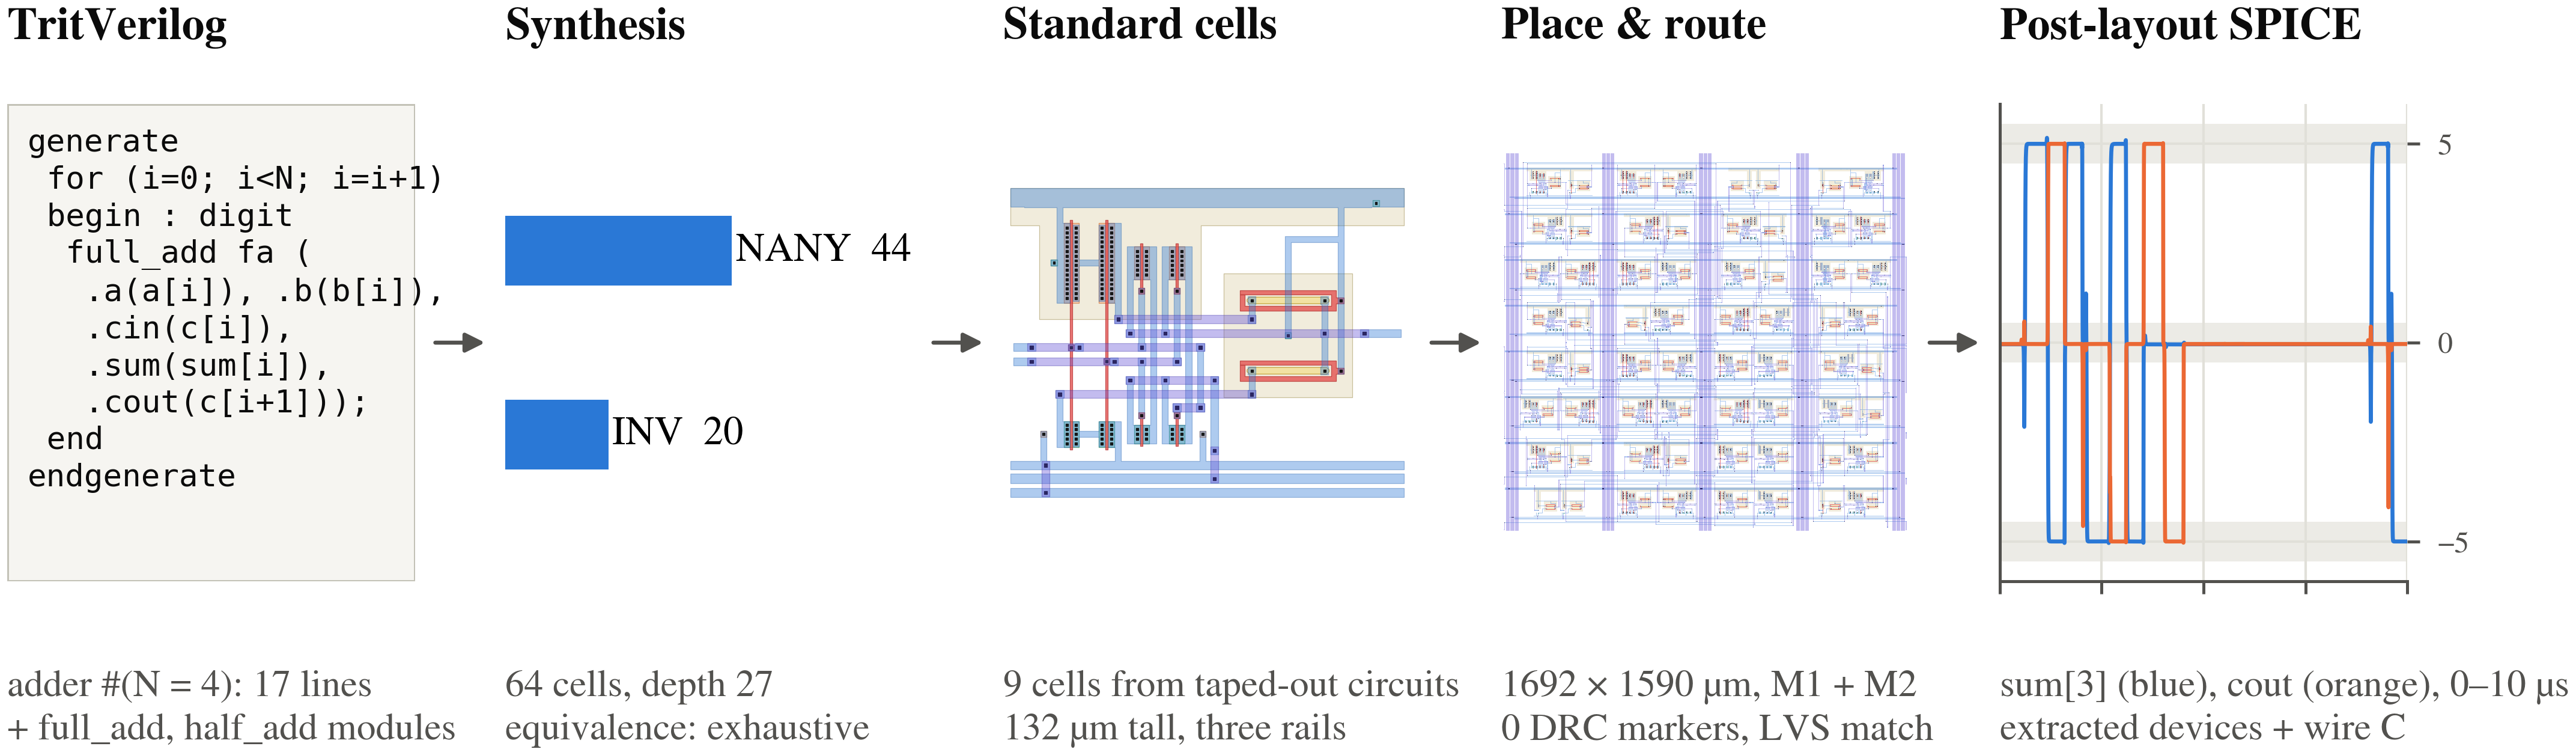

**図の4トリット加算器：** トップレベルHDL 17行と共通モジュール → 64セル、1692 × 1590 µmのGDS、描画DRCの違反マーカー0件、LVSはMatch。

中間レベルの維持には電力が必要です。この加算器のセル構成では、マッピング後のセルあたり4.17 mW、6トリットで0.4 Wに達します。素子寸法によって、電流と電圧精度のトレードオフが変わります。

[![Colabで開く](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PenguinEino/tritflow/blob/colab-v0/notebook/tritflow_tr1um.ipynb)

無料版Colabでの動作確認（[0ffe7a1](https://github.com/PenguinEino/tritflow/commit/0ffe7a12c34738664e9e788853d87edc9da5b7ec)）：セットアップを含め、全35コードセルが300.7 sで完了しました。

セットアップ後にRun allが止まった場合は、もう一度Run allを選択してください。

<details><summary>著者とライセンス</summary>

- 氏名：Einosuke Okazaki（岡崎 英之介）
- 所属：東京都立産業技術高等専門学校 ものづくり工学科
  情報通信工学コース（日本・東京）
- 学年：第五学年（高校段階と大学の最初の二年間に相当する教育を一貫して行う、
  五年制高専の最終学年）
- メール：einosukeokazaki@gmail.com
- GitHub：PenguinEino

採択された場合、Einosuke OkazakiはISSCC 2027に現地参加し、ポスター発表を行います（2026-10-18に著者が確認）。

Apache-2.0。著者が公開した過去の回路図素材も含みます。

</details>


In [2]:
#@title セットアップ：リリースタグでTritFlowをクローンし、KLayoutとngspiceをインストールして、固定リビジョンのTR-1um PDKを取得 { display-mode: "form" }
_TRITFLOW_SETUP_READY = False
globals().pop("_tf_cells", None)
import os, sys, json, time, hashlib, subprocess, importlib.util
from pathlib import Path
started = time.monotonic()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
SOURCE_URL = "https://github.com/PenguinEino/tritflow.git"
SOURCE_REF = os.environ.get("TRITFLOW_REF", "colab-v0")
def source_git(*args):
    return subprocess.check_output(["git", "-C", str(ROOT), *args], text=True).strip()
if IN_COLAB:
    ROOT = Path("/content/tritflow")
    if not SOURCE_REF or SOURCE_REF.startswith("-") or any(c.isspace() for c in SOURCE_REF):
        raise ValueError("TRITFLOW_REF must name a Git tag or branch")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--single-branch", "--branch", SOURCE_REF,
                        SOURCE_URL, str(ROOT)], check=True)
    if not (ROOT/".git").is_dir():
        raise RuntimeError("/content/tritflow must be a git clone; use a fresh Colab runtime")
    if source_git("remote", "get-url", "origin").removesuffix(".git") != SOURCE_URL.removesuffix(".git"):
        raise RuntimeError("existing checkout has a different origin; use a fresh Colab runtime")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}")
    requested_commit = source_git("rev-parse", "--verify", SOURCE_REF+"^{commit}")
    if SOURCE_COMMIT != requested_commit or source_git("status", "--porcelain", "--untracked-files=no"):
        raise RuntimeError("existing checkout differs from TRITFLOW_REF; use a fresh Colab runtime")
    print(f"Source: {SOURCE_URL} ref={SOURCE_REF} commit={SOURCE_COMMIT}", flush=True)
    if not (ROOT/"notebook/runtime_support.py").is_file():
        raise RuntimeError("TRITFLOW_REF predates this notebook's setup. Select its matching immutable release with TRITFLOW_REF in a fresh runtime.")
    sys.path.insert(0, str(ROOT/"notebook"))
    from runtime_support import SETUP_SCHEMA
    runtime = ROOT/"notebook/runtime.json"
    if not runtime.is_file() or json.loads(runtime.read_text()).get("TRITFLOW_SETUP_SCHEMA") != SETUP_SCHEMA:
        subprocess.run(["bash", str(ROOT/"notebook/colab_setup.sh"), "--source", str(ROOT)], check=True)
    os.environ.update(json.loads(runtime.read_text()))
else:
    candidates = [Path(os.environ.get("TRITFLOW_ROOT", ".")), Path.cwd(), Path.cwd().parent]
    ROOT = next((p.resolve() for p in candidates if (p/"pyproject.toml").is_file()
                 and (p/"tritflow").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("run locally from the full checkout or set TRITFLOW_ROOT")
    SOURCE_COMMIT = source_git("rev-parse", "--verify", "HEAD^{commit}") if (ROOT/".git").exists() else "tracked-tree export (no .git)"
    print(f"Source: {ROOT} commit={SOURCE_COMMIT}")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/"notebook"))
sys.path.append(str(ROOT/"figures"))   # the paper's figure scripts, reused by method cells
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
from runtime_support import check_runtime, print_tool_versions
check_runtime()
print_tool_versions()
_TRITFLOW_SETUP_READY = True


Source: /content/tritflow commit=134dfe793d8170a1547decbca76e558cbb7ca9a6
Scientific Python (host versions preserved): numpy=2.4.3, scipy=1.17.1, matplotlib=3.10.8, plotly=7.1.0


KLayout executable: ~/bin/klayout/klayout
KLayout 0.30.9
ngspice executable: /usr/local/bin/ngspice
******
** ngspice-46+ : Circuit level simulation program
** Compiled with KLU Direct Linear Solver
** The U. C. Berkeley CAD Group
** Copyright 1985-1994, Regents of the University of California.
** Copyright 2001-2025, The ngspice team.
** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html
** Please file your bug-reports at http://ngspice.sourceforge.net/bugrep.html
** Creation Date: Fri May 29 07:44:23 UTC 2026
******


In [3]:
#@title インポートと実行記録 { display-mode: "form" }
NARRATIVE_CONTEXT_SHA256 = 'a7807b8d0730a28f66d3bc357934aba9ce619ffa1bb10ba3022f760fea6402fd'

globals().pop("_tf_cells", None)
if not globals().get("_TRITFLOW_SETUP_READY", False):
    raise RuntimeError("Run the first setup cell successfully, then rerun the imports cell. If setup requested a restart, restart once first.")
from runtime_support import CellState
import numpy as np
from IPython.display import display, HTML, Image
from tritflow import flow, CELLS_DIR, PDK_ROOT, PASS_BAND, TRIT_VOLTS
from tritflow.sim import dc_transfer, input_vectors, subcircuits
from tritflow.viz.graph import truth_table_html
from tritflow.viz.waves import waveform_figure
from tritflow.viz.layout import render_gds, placement_animation, routing_progress
from tritflow.viz.cell import device_mapping
from tritflow.sim.provenance import pdk_provenance
from tritflow.sim.postlayout import logical_nodeset
from cache import Cache, runtime_fingerprint, source_manifest
from campaign import RecordedCampaign
from schematics import schematic_gallery
from experiments import (complete_design, experiment_artifacts, assert_experiment,
                         load_edited, verify_publication_sources, adder_demo_vectors)
EXTENDED = os.environ.get("TRITFLOW_EXTENDED", "0") == "1"
BUILD = Path(os.environ.get("TRITFLOW_NOTEBOOK_BUILD", ROOT/"build/notebook")).resolve()
qualified_pdk = pdk_provenance(PDK_ROOT)
assert qualified_pdk["qualified_commit"] == json.loads((ROOT/"notebook/setup_pins.json").read_text())["pdk_commit"]
native_sources = source_manifest(ROOT,PDK_ROOT)
cache = Cache(BUILD/"cache", runtime_fingerprint(ROOT, PDK_ROOT,names=native_sources),
              force=os.environ.get("TRITFLOW_FORCE_RUN", "0") == "1",sources=native_sources)
recorded_campaign = RecordedCampaign(ROOT/"notebook/assets/four_designs.zip",ROOT,PDK_ROOT,
                                     enabled=not cache.force)
renderer_sha256 = hashlib.sha256((ROOT/"tritflow/viz/layout.py").read_bytes()).hexdigest()
from presentation import show, table, evidence

from IPython.display import Markdown, Code
from editorial import context, context_identity, render as render_narrative, dimensions
from paper_evidence import load_paper
from learning import sizing_slider, value_selector, highlight_devices
from predictions import divider, zero_dc, rail_power
from presentation import details_html, details_svg
from routing_identity import routing_label, archive_routing
paper = load_paper(ROOT)
narrative_values = context(ROOT)
assert context_identity(narrative_values) == NARRATIVE_CONTEXT_SHA256, "Published figure measurements changed; regenerate the notebook before running."

_tf_cells = CellState({'setup': 'setup', 'imports': 'imports', 'opening_inputs': 'Chapter 0: From HDL to a checked adder layout', 'method-opening': 'method-opening', 'opening': 'Chapter 0: From HDL to a checked adder layout', 'method-gates': 'method-gates', 'gates': '1. Three levels from ordinary CMOS', 'method-sizing': 'method-sizing', 'sizing': '2. Sizing sets the middle level', 'method-cells': 'method-cells', 'cells': '3. Taped-out circuits become placeable cells', 'method-arithmetic': 'method-arithmetic', 'arithmetic': '4. Describe signed arithmetic in TritVerilog', 'method-synthesis': 'method-synthesis', 'synthesis': '5. Follow an expression into cells', 'method-schematic': 'method-schematic', 'method-pnr': 'method-pnr', 'pnr': '6. Route signals and feed the standing current', 'method-pre': 'method-pre', 'pre': 'Chapter 7: Does the layout still work?', 'published': 'Chapter 7: Does the layout still work?', 'method-sta': 'method-sta', 'sta': 'Chapter 7: Does the layout still work?', 'method-edit': 'method-edit', 'method-pick': 'method-pick', 'method-custom': 'method-custom', 'custom_check': 'Chapter 8: Change the circuit and close the loop', 'method-custom_layout': 'method-custom_layout', 'custom': 'Chapter 8: Change the circuit and close the loop', 'method-broken': 'method-broken', 'method-shuttle': 'method-shuttle', 'shuttle': '9. Next: compare the model with silicon', 'characterization': 'Appendix B: Verification evidence and how to rerun', 'four': 'Appendix B: Verification evidence and how to rerun', 'final': 'Appendix B: Verification evidence and how to rerun'})


## 0. HDLから検証済みの加算器レイアウトへ

論文用の図は4トリットのリップルキャリー加算器を示しています。実行する
例題では2トリット版を作ります。短いAPI呼び出し列を実行し、
生成したレイアウトと、和の最上位桁およびキャリーを確認してください。

トリットがとる値は−1、0、+1です。ここでは、それぞれの電圧を
-5、0、+5 Vとします。トリットは独立した
信号型であり、Verilogの`x`や`z`はトリットの追加の値ではありません。
波形上の網掛けの帯は、各目標レベルに対する許容誤差を示しています。

> **ここから分かること。** HDL、マッピング後のセル、抽出した接続、
> 波形は、同じ演算を表しています。電圧の網掛け帯によって、
> 符号付きの各出力トリットと、物理的な合否判定を対応付けています。

次は、このセルの一つを開き、中間電圧を作る仕組みを見ていきます。


`examples/adder.tv`

```verilog
`include "full_add.tv"
// Little-endian arithmetic: a[i] and b[i] have weight 3**i.
// A + B + cin = SUM + 3**N * cout; N must be >= 1.
module adder #(parameter N = 4)
  (input trit [N-1:0] a, b, input trit cin,
   output trit [N-1:0] sum, output trit cout);
  wire trit [N:0] c;
  assign c[0] = cin;
  genvar i;
  generate
    for (i = 0; i < N; i = i + 1) begin : digit
      full_add fa (.a(a[i]), .b(b[i]), .cin(c[i]),
                   .sum(sum[i]), .cout(c[i+1]));
    end
  endgenerate
  assign cout = c[N];
endmodule
```


In [4]:
#@title 第0章の入力：試験条件と独立した整数演算による正解値 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('opening_inputs', 'Chapter 0: From HDL to a checked adder layout', requires=[]):
    LOAD_F, HOLD_S, STEP_S, EDGE_S, TEMP_C = 100e-15, 1e-6, 2e-9, 1e-9, 27
    PNR_ROWS, PNR_ANNEAL_STEPS = None, 600  # automatic near-square floorplan; placement effort
    CONDITIONS = dict(hold_s=HOLD_S, step_s=STEP_S, edge_s=EDGE_S, temperature_c=TEMP_C, timeout=600)
    out = BUILD/"adder2_demo"
    def adder_reference(vector):
        """Independent balanced-ternary integer oracle; `inputs` comes from the method cell."""
        v = dict(zip(inputs, vector, strict=True))
        remainder = sum((v[f"a[{i}]"] + v[f"b[{i}]"])*3**i for i in range(2)) + v["cin"]
        result = {}
        for i in range(2):
            result[f"sum[{i}]"] = (remainder+1)%3-1
            remainder = (remainder-result[f"sum[{i}]"])//3
        return {**result, "cout": remainder}


In [5]:
d = flow.load(ROOT/"examples/adder.tv", "adder", {"N": 2})        # 1. TritVerilog source
net = d.synthesize(name="adder2_demo")                           # 2. cells + exhaustive equivalence check
inputs = [p.name for p in net.ports if p.dir == "input"]
vectors, vector_labels = adder_demo_vectors(inputs)               #    three-level test sequence
lay = net.place_and_route(output_dir=out, seed=0, rows=PNR_ROWS, anneal_steps=PNR_ANNEAL_STEPS)  # 3. GDS
drc, lvs = lay.drc(), lay.lvs()                                  # 4. TR-1um DRC deck, strict LVS
guesses = logical_nodeset(net, lvs["report"], inputs, vectors[0])
post = lay.extract().simulate(vectors, load=LOAD_F, expected=adder_reference,
                              nodeset=guesses, **CONDITIONS)     # 5. extracted devices + wire C in ngspice
print(f"DRC clean: {drc['clean']} · LVS match: {lvs['matched']} · analog PASS: {post['measurements']['passed']}")


DRC clean: True · LVS match: True · analog PASS: True


In [6]:
#@title 第0章の検証 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('opening', 'Chapter 0: From HDL to a checked adder layout', requires=[]):
    logical = d.truth_table()
    outputs = [p.name for p in net.ports if p.dir == "output"]
    assert all(len(v) == len(inputs) for v in vectors)
    assert len(logical[inputs[0]]) == 3**len(inputs)
    expected_sequence = [adder_reference(v) for v in vectors]
    assert all({r[p] for r in expected_sequence} == {-1,0,1} for p in outputs)
    assert all(a != b for a,b in zip(vectors,vectors[1:]))
    for row in zip(*(logical[name] for name in inputs)):
        assert adder_reference(row) == {k: int(v) for k,v in d.design.evaluate(dict(zip(inputs,row))).items()}
    assert drc["clean"] and lvs["matched"], (drc, lvs)
    assert post["measurements"]["passed"], post["measurements"]
    demo = {**post, "stats": lay.stats, "drc": drc, "lvs": lvs, "initial_nodeset_v": guesses}
    assert not lay.stats["library_mock"]
    assert all({row["outputs"][p]["ideal_trit"] for row in demo["measurements"]["rows"]} == {-1,0,1}
               and demo["measurements"]["max_settling_s"][p] > 0 for p in outputs)
    table([["Live adder", "Cells", "Die (µm)", "DRC markers", "Strict LVS", "Analog"],
           [net.top,net.report()["total_cells"],dimensions(lay.stats["die_size_um"]),
            demo["drc"]["violations"],demo["lvs"]["matched"],demo["measurements"]["passed"]]])
    print(f"Independent integer oracle: {len(logical[inputs[0]])} exhaustive states; extracted sequence: {len(set(vectors))} selected states.")


Live adder,Cells,Die (µm),DRC markers,Strict LVS,Analog
adder2_demo,32,1284 × 1038,0,True,True


Independent integer oracle: 243 exhaustive states; extracted sequence: 9 selected states.


## 1. 通常のCMOSで三つのレベルを作る

中間の出力レベルは、導通するトランジスタと抵抗の枝によって生じます。
入力がゼロのとき、インバータの出力は両方の電源レールにつながり、
その釣り合いで電圧が決まります。入力が一定でも電流が流れます。
NANYにはVMIDへの経路が加わり、入力トリットの符号が逆のときに出力をクランプします。
もう一方の入力を各論理レベルに固定したときの伝達特性と、
その下に示すVDD電流を対応させて読んでください。

各ゲートの関数は次のとおりです。

$$
\begin{aligned}
\mathrm{INV}(a)&=-a, & \mathrm{NAND}(a,b)&=-\min(a,b),\\
\mathrm{NOR}(a,b)&=-\max(a,b), & \mathrm{NANY}(a,b)&=-\mathrm{clamp}(a+b,-1,1).
\end{aligned}
$$

**まず予想する。** INVを選び、入力を中間電圧に設定します。
導通する各MOSをオン抵抗に置き換え、直列抵抗はそのまま残します。
上側と下側の枝全体の抵抗を、それぞれ$R_u$、$R_d$とします。

$$
I_{\mathrm{hand}}=\frac{V_{DD}-V_{SS}}{R_u+R_d},\qquad
V_{Y,\mathrm{hand}}=V_{SS}+I_{\mathrm{hand}}R_d,
$$

$$
P_{\mathrm{hand}}=(V_{DD}-V_{SS})I_{\mathrm{hand}}.
$$

両方の枝の抵抗が等しければ、出力は中間電圧になると予想できます。表示する手計算値には
素子寸法とPDKの公称モデルパラメータを用います。その後のSPICEでは、
素子の非線形性を含めて計算します。


A=VMIDで導通しうる経路はVDD → MP → RP → Y → RN → MN → VSSです。公称寸法では$R_u$ = 11.33 kΩ、$R_d$ = 11.23 kΩとなります。**SPICEの前に手計算：** I = 0.4432 mA; Y = -0.02066 V; P = 4.432 mW。

`examples/gates.tv`

```verilog
// The four primitive cells, written as TritVerilog expressions.
// Trits are -1, 0, +1; '~' negates, '&' is min, '|' is max.
module gates(input  trit a, b,
             output trit inva, nandab, norab, nanyab);
  assign inva   = ~a;          // INV  : -a
  assign nandab = ~(a & b);    // NAND : -min(a, b)
  assign norab  = ~(a | b);    // NOR  : -max(a, b)
  assign nanyab = nany(a, b);  // NANY : -sat(a + b)
endmodule
```


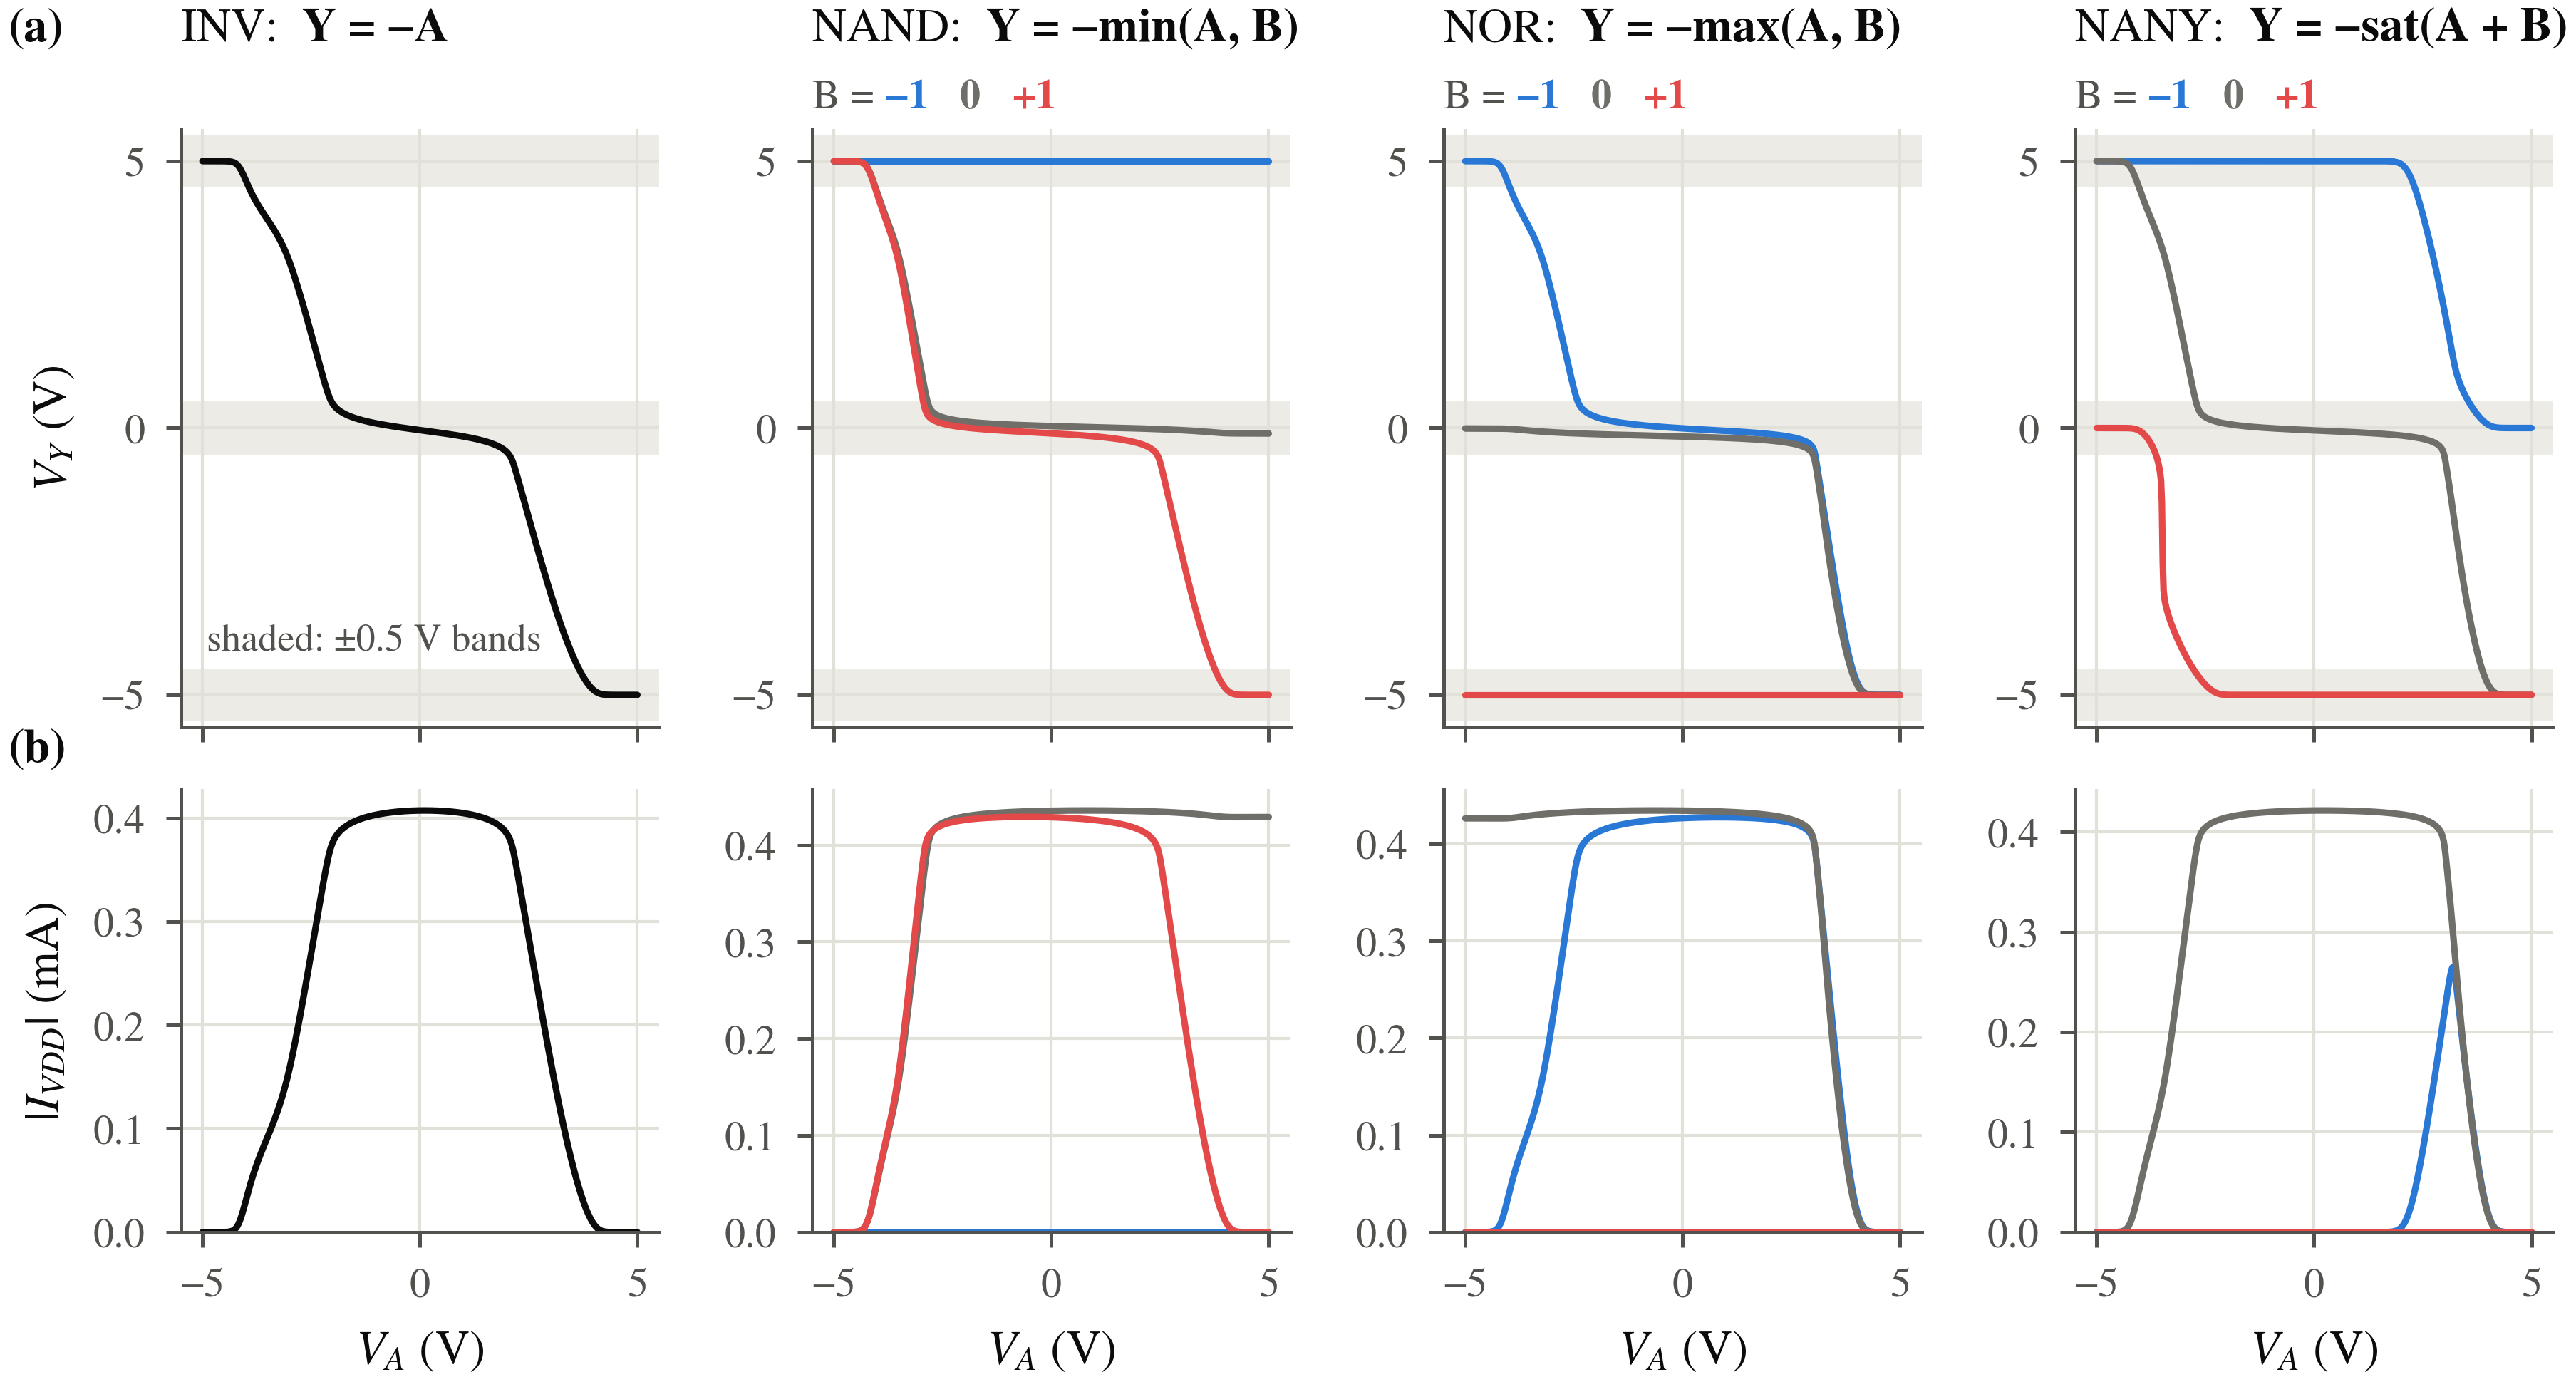

A = 0 V:  Y = -39.5 mV,  supply current = 0.407 mA


In [7]:
from fig_gates import simulate, draw                      # the paper's own Fig. 2 script
from style import save as save_figure
gates = flow.load(ROOT/"examples/gates.tv", "gates")       # the definition shown above
t = gates.truth_table()                                    # all nine input pairs, ideal trits
curves = simulate(CELLS_DIR/"out")                         # ten ngspice DC sweeps of the extracted layouts
png = save_figure(draw(curves), "fig_gates", out=BUILD/"figures")
display(Image(filename=str(png), width=1000))              # Fig. 2, regenerated from your own run
v_a, v_y, i_ma = curves["INV"][0]
i0 = int(np.argmin(abs(v_a)))
print(f"A = 0 V:  Y = {1e3*v_y[i0]:.1f} mV,  supply current = {i_ma[i0]:.3f} mA")


**三値論理セルのDC特性** 抽出後のINV、NAND、NOR、NANYセルについて、
入力Aに対する(a)出力電圧と(b)VDD電流の絶対値を示します。
温度は27 °Cで、Bがあるセルでは各トリットレベルに固定しています。
入力が中間レベルのとき、INVのVDD電流は0.4072 mAで、
各電源レールの電力を符号付きで合計すると4.072 mWです。
網掛けは出力の許容帯±0.5 Vを示します。

> **ここから分かること。** 入力が中間レベルのとき、抽出後のINVは
> -0.03954 Vに整定し、27 °CでVDDから
> 0.4072 mAが流れます。入力が一定のとき、各レールの電力を符号付きで
> 合計すると4.072 mWになります。

回路図の寸法を使った分圧回路の手計算値は-0.02066 V、
4.432 mWで、対応する回路図のDC計算では-0.03954 V、
4.072 mWとなります。

$a=0$では、$\min(a,-a)$も$\max(a,-a)$もゼロになります。
この例だけでも、二値論理の相補則を合成規則として使えないことが分かります。

In [8]:
#@title 第1章の検証とテープアウト済みINVの回路図 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('gates', '1. Three levels from ordinary CMOS', requires=[]):
    assert np.array_equal(t["inva"], -t["a"])
    assert np.array_equal(t["nandab"], -np.minimum(t["a"], t["b"]))
    assert np.array_equal(t["norab"], -np.maximum(t["a"], t["b"]))
    assert np.array_equal(t["nanyab"], -np.clip(t["a"]+t["b"],-1,1))
    details_html("Gate truth tables", truth_table_html(gates.design))
    for name in ["INV","NAND","NOR","NANY"]:
        body = subcircuits((CELLS_DIR/f"out/{name}/{name}.spice").read_text())[name.lower()]["body"]
        assert ("VMID" in body.upper()) == (name == "NANY"), name
    # The regenerated figure uses the same public DC call and zero-input sample as the paper.
    assert {cell: sorted(c) for cell, c in curves.items()} == {"INV": [0], "NAND": [-1, 0, 1], "NOR": [-1, 0, 1], "NANY": [-1, 0, 1]}
    assert abs(v_a[i0]) < 1e-9
    assert abs(v_y[i0]-paper["inv_dc"]["output_v"]) < 1e-8
    details_html("Taped-out INV schematic and exported source",schematic_gallery(
        ROOT/"notebook/assets/schematics",names=["INV"],selected="INV"))


Vector,ainput,binput,invaoutput,nandaboutput,noraboutput,nanyaboutput
1,-1,-1,+1,+1,+1,+1
2,-1,0,+1,+1,0,+1
3,-1,+1,+1,+1,-1,0
4,0,-1,0,+1,0,+1
5,0,0,0,0,0,0
6,0,+1,0,0,-1,-1
7,+1,-1,-1,+1,-1,0
8,+1,0,-1,0,-1,-1
9,+1,+1,-1,-1,-1,-1


## 2. 素子寸法が中間レベルを決める

素子寸法を変えると、分圧回路の両側が変わります。プルダウンを強くすると
中間出力は下がり、プルアップを強くすると上がります。両方の直列抵抗を大きくすると
静的電流は減りますが、MOSの非対称性は引き続き電圧に影響します。
MOS寸法を固定してインバータの伝達特性を比較し、INVとNANYの誤差・電流の
散布図を読んでください。丸で囲んだ点は、参照設計で採用した
寸法を示します。

**まず予想する。** 導通しているMOSのオン抵抗は、
$W/L$に反比例すると考えます。新しいSPICE曲線を見る前に、
前章の分圧回路を使って予想してください。

$$
r_{\mathrm{on}}'\simeq r_{\mathrm{on}}
\frac{(W/L)_{\mathrm{adopted}}}{(W/L)'},\qquad
I'=\frac{V_{DD}-V_{SS}}{R_u'+R_d'},
$$

$$
\Delta V_Y\simeq
(V_{DD}-V_{SS})\frac{R_u\Delta R_d-R_d\Delta R_u}{(R_u+R_d)^2}.
$$



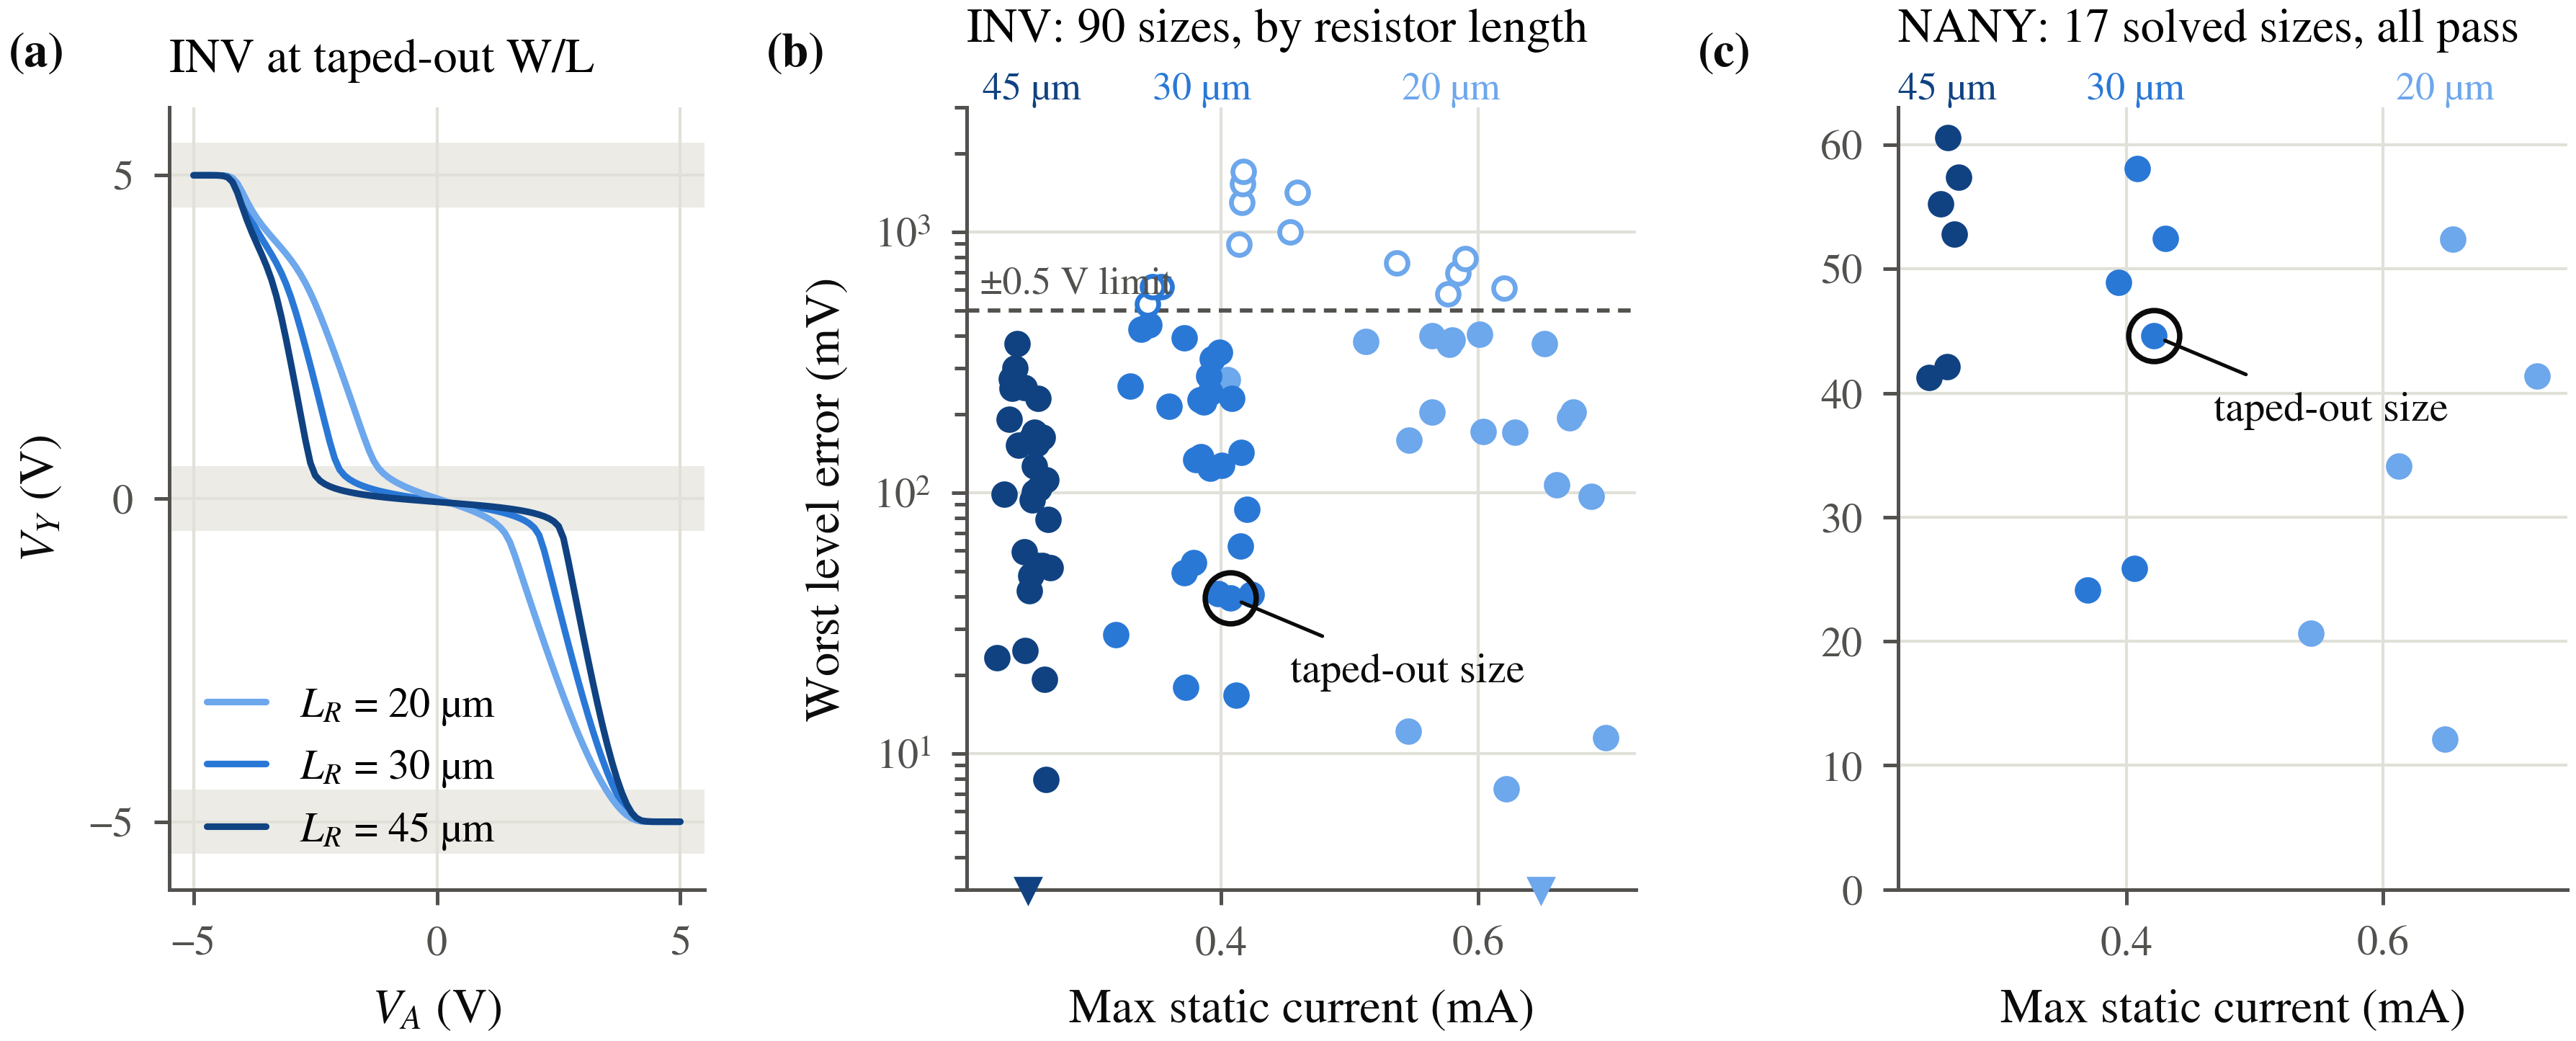

**寸法によって中間レベルの精度と静的電流が変わる** (a)採用したMOS寸法で、
抵抗長を20、30、45 µmとしたINVの伝達特性。
(b,c)離散的な論理状態での最大レベル誤差と、各レールの電流絶対値の最大値の関係。
有限値が得られたINVの90件と
NANYの17件を示します。
塗りつぶしと白抜きのマーカーは、誤差が
±0.5 V以内か範囲外かを区別します。逆三角は
3 mV未満の誤差を表示下限に示し、外側の丸は
参照設計で使う寸法を示します。

> **ここから分かること。** 散布図には、有限値が得られたINVの90件と
> NANYの17件を示しています。
> 丸で囲んだINV寸法では、論理レベル誤差の最大値が
> 39.54 mV、各レールの電流絶対値の最大値が
> 407.2 µAです。NANYの対応する値は、
> 44.6 mVと421.4 µAです。

MOS寸法を固定してINVの両方の抵抗を30から
45 µmへ長くすると、分圧回路の手計算では
中間レベルが7.984 mV上昇すると予想されます。一方、回路図のSPICEでは
-12.9 mVとなります。手計算モデルは電流の減少を
正しく予想しますが、この小さな電圧変化の符号は外しています。このモデルで考慮するのは、
形状から求めた抵抗値と一定のMOSオン抵抗だけです。実際には、両方の
F_RRの基板端子はVDDにつながっていますが、二つの抵抗の信号端子は
異なる電圧にあるため、バイアスに依存する抵抗値の
補正も異なります。MOSの動作も非線形です。計算結果では、電流が
407.2から260.7 µAへ減る一方、
最大レベル誤差は
39.54から52.44 mVへ増えます。


INV at zero input,Hand estimate,SPICE
Output (V),-0.02066,-0.03954
Static power (mW),4.432,4.072


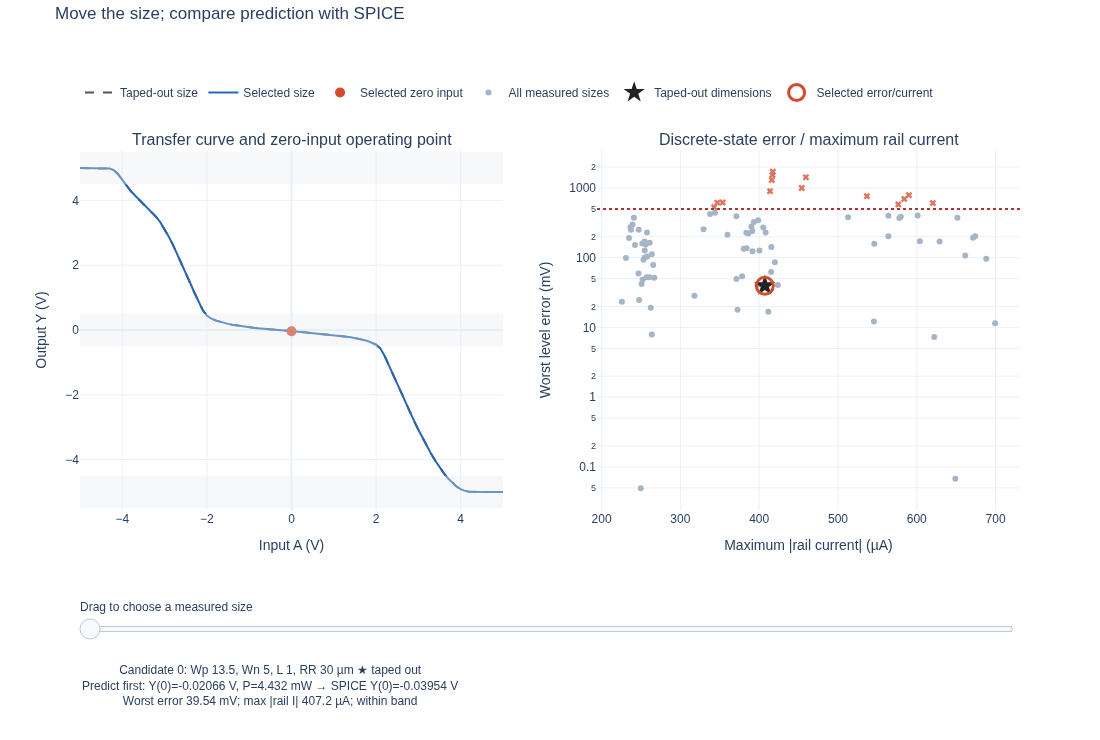

In [9]:
from tritflow.sim.sizing import load_grid
sizing_grids = {cell: load_grid(cell) for cell in ("INV", "NANY")}  # precomputed W/L/R sweeps
gi = sizing_grids["INV"]
adopted = gi["rows"][gi["adopted_index"]]                           # the taped-out size
hand = divider(adopted["dimensions"], PDK_ROOT)                     # predict first ...
table([["INV at zero input", "Hand estimate", "SPICE"],
       ["Output (V)", hand["output_v"], zero_dc(adopted)["output_v"]["Y"]],
       ["Static power (mW)", hand["power_w"]*1e3, rail_power(zero_dc(adopted), gi["conditions"]["supplies_v"])*1e3]])
show(sizing_slider(gi, PDK_ROOT))                                   # ... then explore every simulated size


In [10]:
#@title 第2章の詳細：テープアウト時のMOS寸法で試す抵抗長の候補 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('sizing', '2. Sizing sets the middle level', requires=[]):
    # Hold MOS sizes fixed: these are actual simulated RR candidates.
    rr_candidates = sorted((r for r in gi["rows"] if r["dc"] and
        all(r["dimensions"][k] == adopted["dimensions"][k] for k in ("MP","MN"))),
        key=lambda r:r["dimensions"]["RP"]["l_um"])
    table([["Common RR length (µm)","Worst level error (mV)","Max |rail I| (µA)","Reference"]]+[
        [r["dimensions"]["RP"]["l_um"],r["max_error_v"]*1e3,r["max_static_current_a"]*1e6,
         "taped out" if r["is_adopted"] else ""] for r in rr_candidates])


Common RR length (µm),Worst level error (mV),Max |rail I| (µA),Reference
20,0.06736,649,
30,39.54,407.2,taped out
45,52.44,260.7,


## 3. テープアウトした回路を配置可能なセルにする

配線ツールには回路だけでなく、セル境界、規則を満たすピン接続領域、
配線障害物の情報が必要です。これらのセルは高さを共通にし、VDD、VMID、VSSを
セル行の水平方向に通します。元のNANYと変換後のNANYを同じ縮尺で比較し、
突き当て配置した行を各レールがどう通るかを追ってください。素子の輪郭で、プルアップ、
プルダウン、クランプ、抵抗の各グループを示しています。

セル内部のM2とビアも配線障害物に含めます。信号ピンは、縦方向のM2配線から
ビアで接続できるM1上に置きます。セルの向きは通常配置か
左右反転とし、レールの並び順を保ちます。TIEセルは有限の抵抗を介して
定数を供給し、FILLは隙間でもレールとウェルを連続させます。



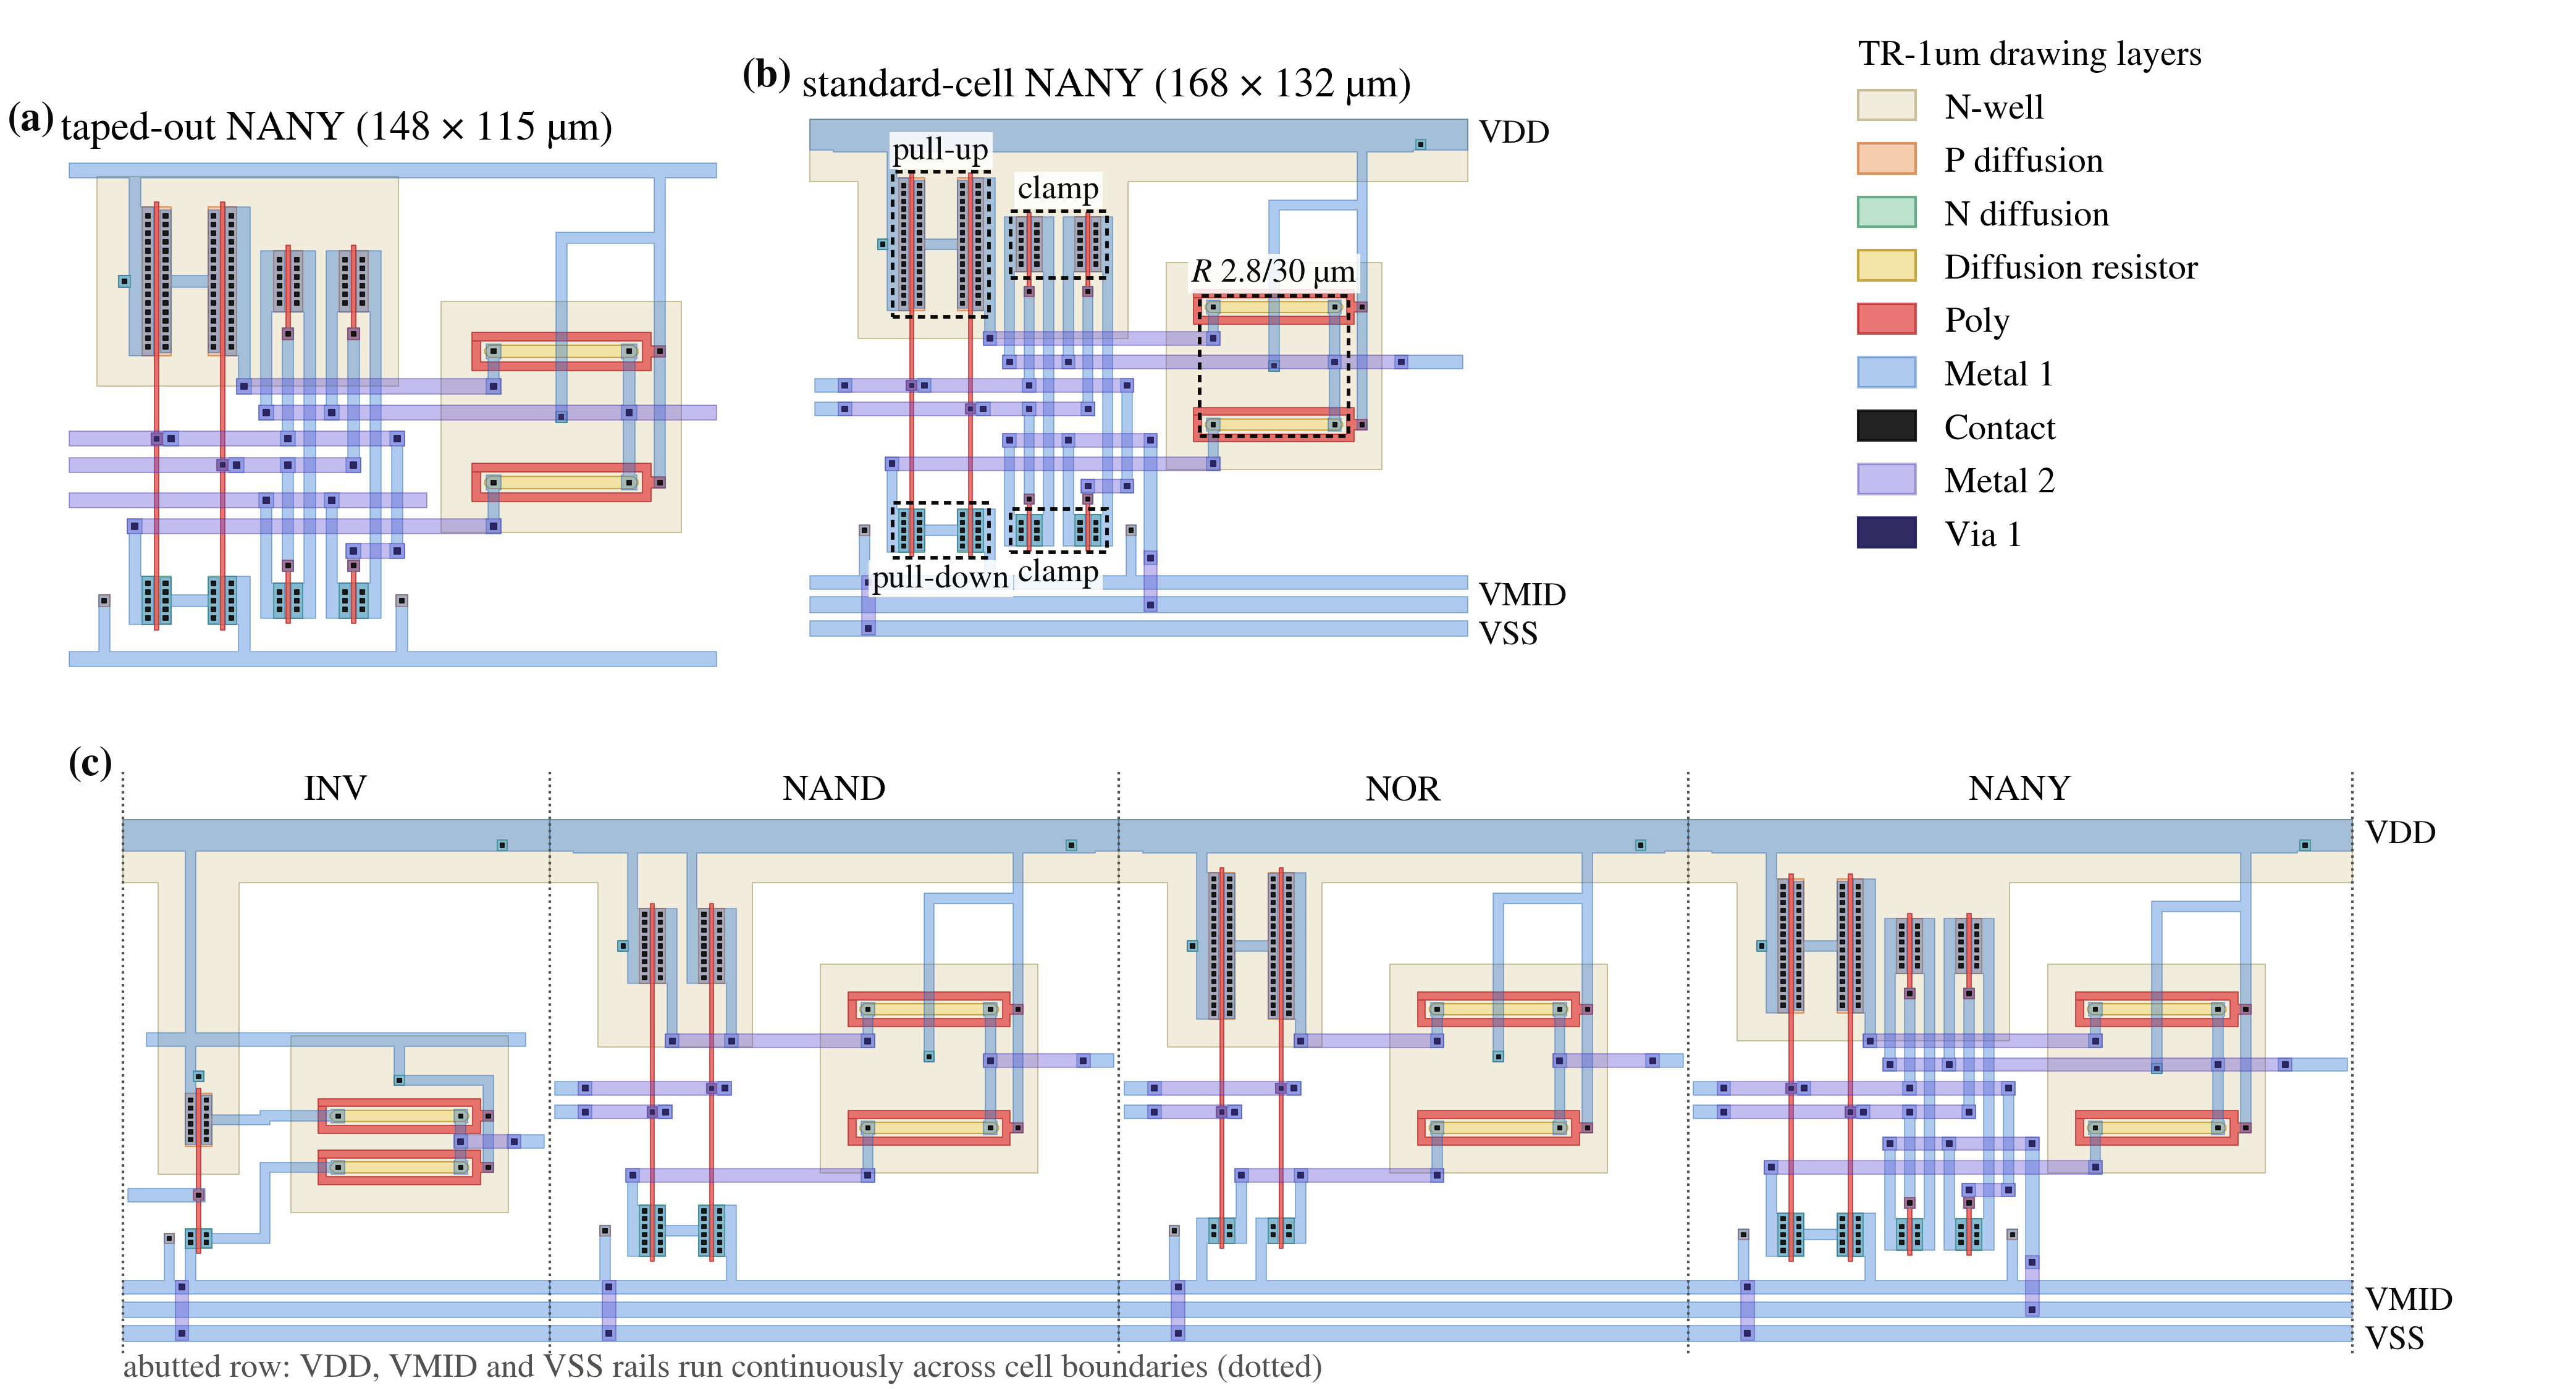

**参照NANYを三本の電源レールを持つセル行に適合させる** (a)テープアウトした
参照レイアウトの寸法は148 × 115 µmです。(b)変換後の
セルは回路と素子寸法を保ち、168 ×
132 µmに収めています。素子グループと電源レールにラベルを付けています。
(c)4個の論理セルを突き当て配置した行では、VDD、VMID、
VSSが、図示したセル境界をまたいで連続しています。

> **ここから分かること。** NANYは、回路と素子寸法を保ちながら、148 × 115 µmから
> 168 × 132 µmへと拡大します。面積は
> 参照レイアウトの1.303倍です。
> VDD、VMID、VSSは、行内の全4セルにわたって連続しています。

セル単体の検証と、突き当て配置の検証結果は付録Bに示します。


{'INV': '108 × 132 µm', 'NAND': '144 × 132 µm', 'NOR': '144 × 132 µm', 'NANY': '168 × 132 µm', 'BUF': '216 × 132 µm', 'TIEP': '72 × 132 µm', 'TIEZ': '72 × 132 µm', 'TIEN': '72 × 132 µm', 'FILL': '24 × 132 µm'}


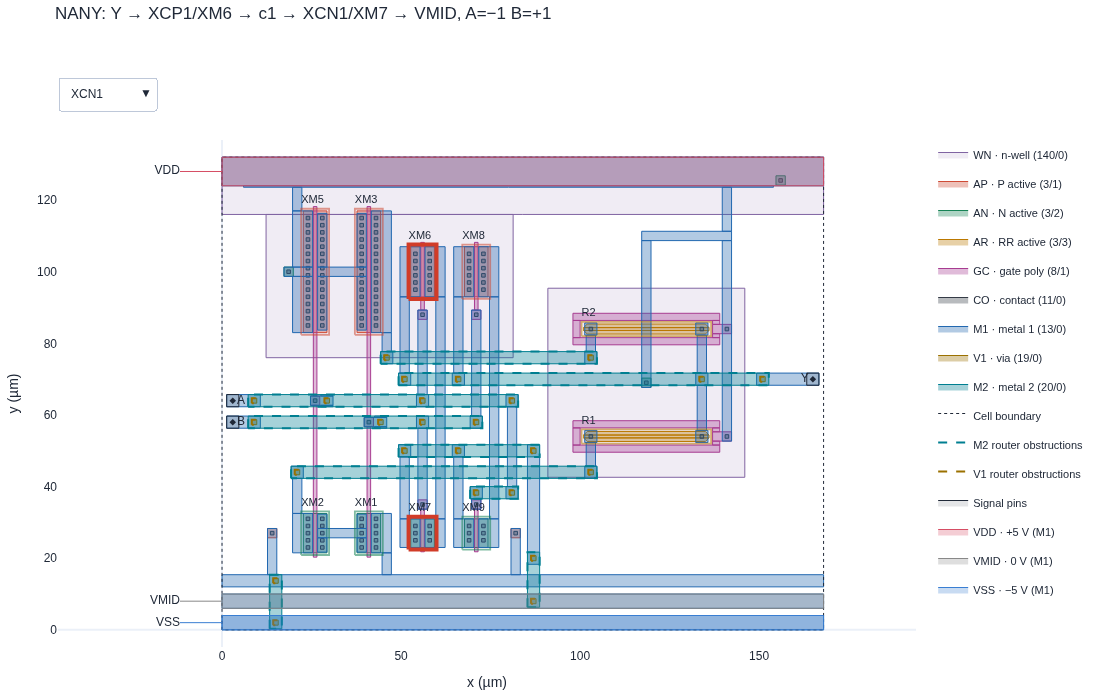

In [11]:
library = json.loads((CELLS_DIR/"out/library.json").read_text())
abstracts = {c["name"]: json.loads((CELLS_DIR/"out"/c["abstract"]).read_text()) for c in library}
print({name: f"{a['width']:g} × {a['height']:g} µm" for name, a in abstracts.items()})
mapping = device_mapping("NANY", selected="XCN1")       # LVS-matched schematic devices on the real GDS
show(highlight_devices(mapping, {"XCP1", "XCN1"},
                       title="NANY: Y → XCP1/XM6 → c1 → XCN1/XM7 → VMID, A=−1 B=+1"))


In [12]:
#@title 第3章の検証：テンプレート、クランプ素子、セルの適合性確認 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('cells', '3. Taped-out circuits become placeable cells', requires=[]):
    template = json.loads((CELLS_DIR/"template.json").read_text())
    generation = json.loads((CELLS_DIR/"out/generation.json").read_text())
    assert {a["height"] for a in abstracts.values()} == {template["height"]}
    assert generation["height_um"] == template["height"]

    cell_dimension_rows = ([["Cell", "Width × common height (µm)", "Area (µm²)", "Free full-height M2 tracks"]]+
          [[name, [a["width"],a["height"]], a["width"]*a["height"], a["free_M2_tracks"]["count"]]
           for name,a in abstracts.items()])
    abstract = json.loads((CELLS_DIR/"out/NANY/NANY.abstract.json").read_text())
    # Highlight both conducting devices of the zero-level clamp. These are device
    # outlines, not an invented extracted current-density or wire-current map.
    clamp_devices = {"XCP1","XCN1"}
    clamp_body = subcircuits((CELLS_DIR/"out/NANY/NANY.spice").read_text())["nany"]["body"]
    clamp_terminals = {fields[0]:fields[1:5] for fields in map(str.split,clamp_body.splitlines()) if fields}
    assert clamp_terminals["XCP1"] == ["c1","A","Y","VDD"]
    assert clamp_terminals["XCN1"] == ["c1","B","VMID","VSS"]
    clamp_character = json.loads((CELLS_DIR/"out/NANY/NANY.char.json").read_text())
    assert hashlib.sha256((CELLS_DIR/"out/NANY/NANY.ext.spice").read_bytes()).hexdigest() == clamp_character["source_sha256"]
    clamp_dc = next(r for r in clamp_character["dc"] if r["input_trits"] == [-1,1])
    assert clamp_dc["passed"] and abs(clamp_dc["output_v"]["Y"]) <= PASS_BAND
    assert clamp_devices <= {r["name"] for r in mapping.rows}
    evidence("Device correspondence and W/L",mapping.rows)

    qualification = CELLS_DIR/"out/verify_report.json"
    if qualification.is_file():
        report = json.loads(qualification.read_text())
        assert report["passed"]
        assert all(hashlib.sha256((PDK_ROOT/name).read_bytes()).hexdigest() == value
                   for name,value in report["deck_sha256"].items()), "cell qualification uses a different PDK"
        for cell, artifacts in report["artifact_sha256"].items():
            for suffix, expected_hash in artifacts.items():
                assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.{suffix}").read_bytes()).hexdigest() == expected_hash
        cell_qualification_rows = ([["Cell", "Recorded DRC clean", "Recorded LVS qualification", "LVS method"]]+[
            [name, result["drc"]["passed"], result["lvs"]["passed"],
             result["lvs"].get("method","strict device/port comparison")]
            for name,result in report["cells"].items()])
        if "FILL" in report["cells"]:
            evidence("FILL qualification", report["cells"]["FILL"]["lvs"]["explanation"])
        evidence("Recorded qualification scope", report["scope"])
    else:
        raise FileNotFoundError("Required pinned-PDK cell qualification: "+str(qualification))


## 4. TritVerilogで符号付き演算を記述する

平衡三値では、独立した符号ビットなしで符号付き整数を表します。
桁$i$の重みは$3^i$です。半加算器は二つのトリットを加算し、全加算器は
さらにキャリー入力も受け取ります。共通のHDLとマッピング後のゲートを見比べ、
図に示す和とキャリーの等式をたどってください。generateループで
これらの桁回路を接続すると、冒頭の多桁加算器になります。

$$
a+b+{c}_{in}=s+3{c}_{out},\qquad
A+B+{c}_{in}=\sum_{i=0}^{N-1}s_i3^i+{c}_{out}3^N.
$$

図の入力では$1+1+0=(-1)+3\cdot(+1)$が成り立ちます。
下の全真理値表の検証では、ゲートの論理式とは独立に
整数加算を使います。

このHDLは、`trit`、ベクトル、パラメータ、名前付きモジュール接続、
generateループに対応します。`~`、`&`、`|`、`nany`は、それぞれ符号反転、最小値、
最大値、飽和加算の符号反転を意味します。リテラルでは`T`が−1を表します。
信号の加算はゲートで構成します。HDL内の`+`は整数の
パラメータと添字のための演算子です。



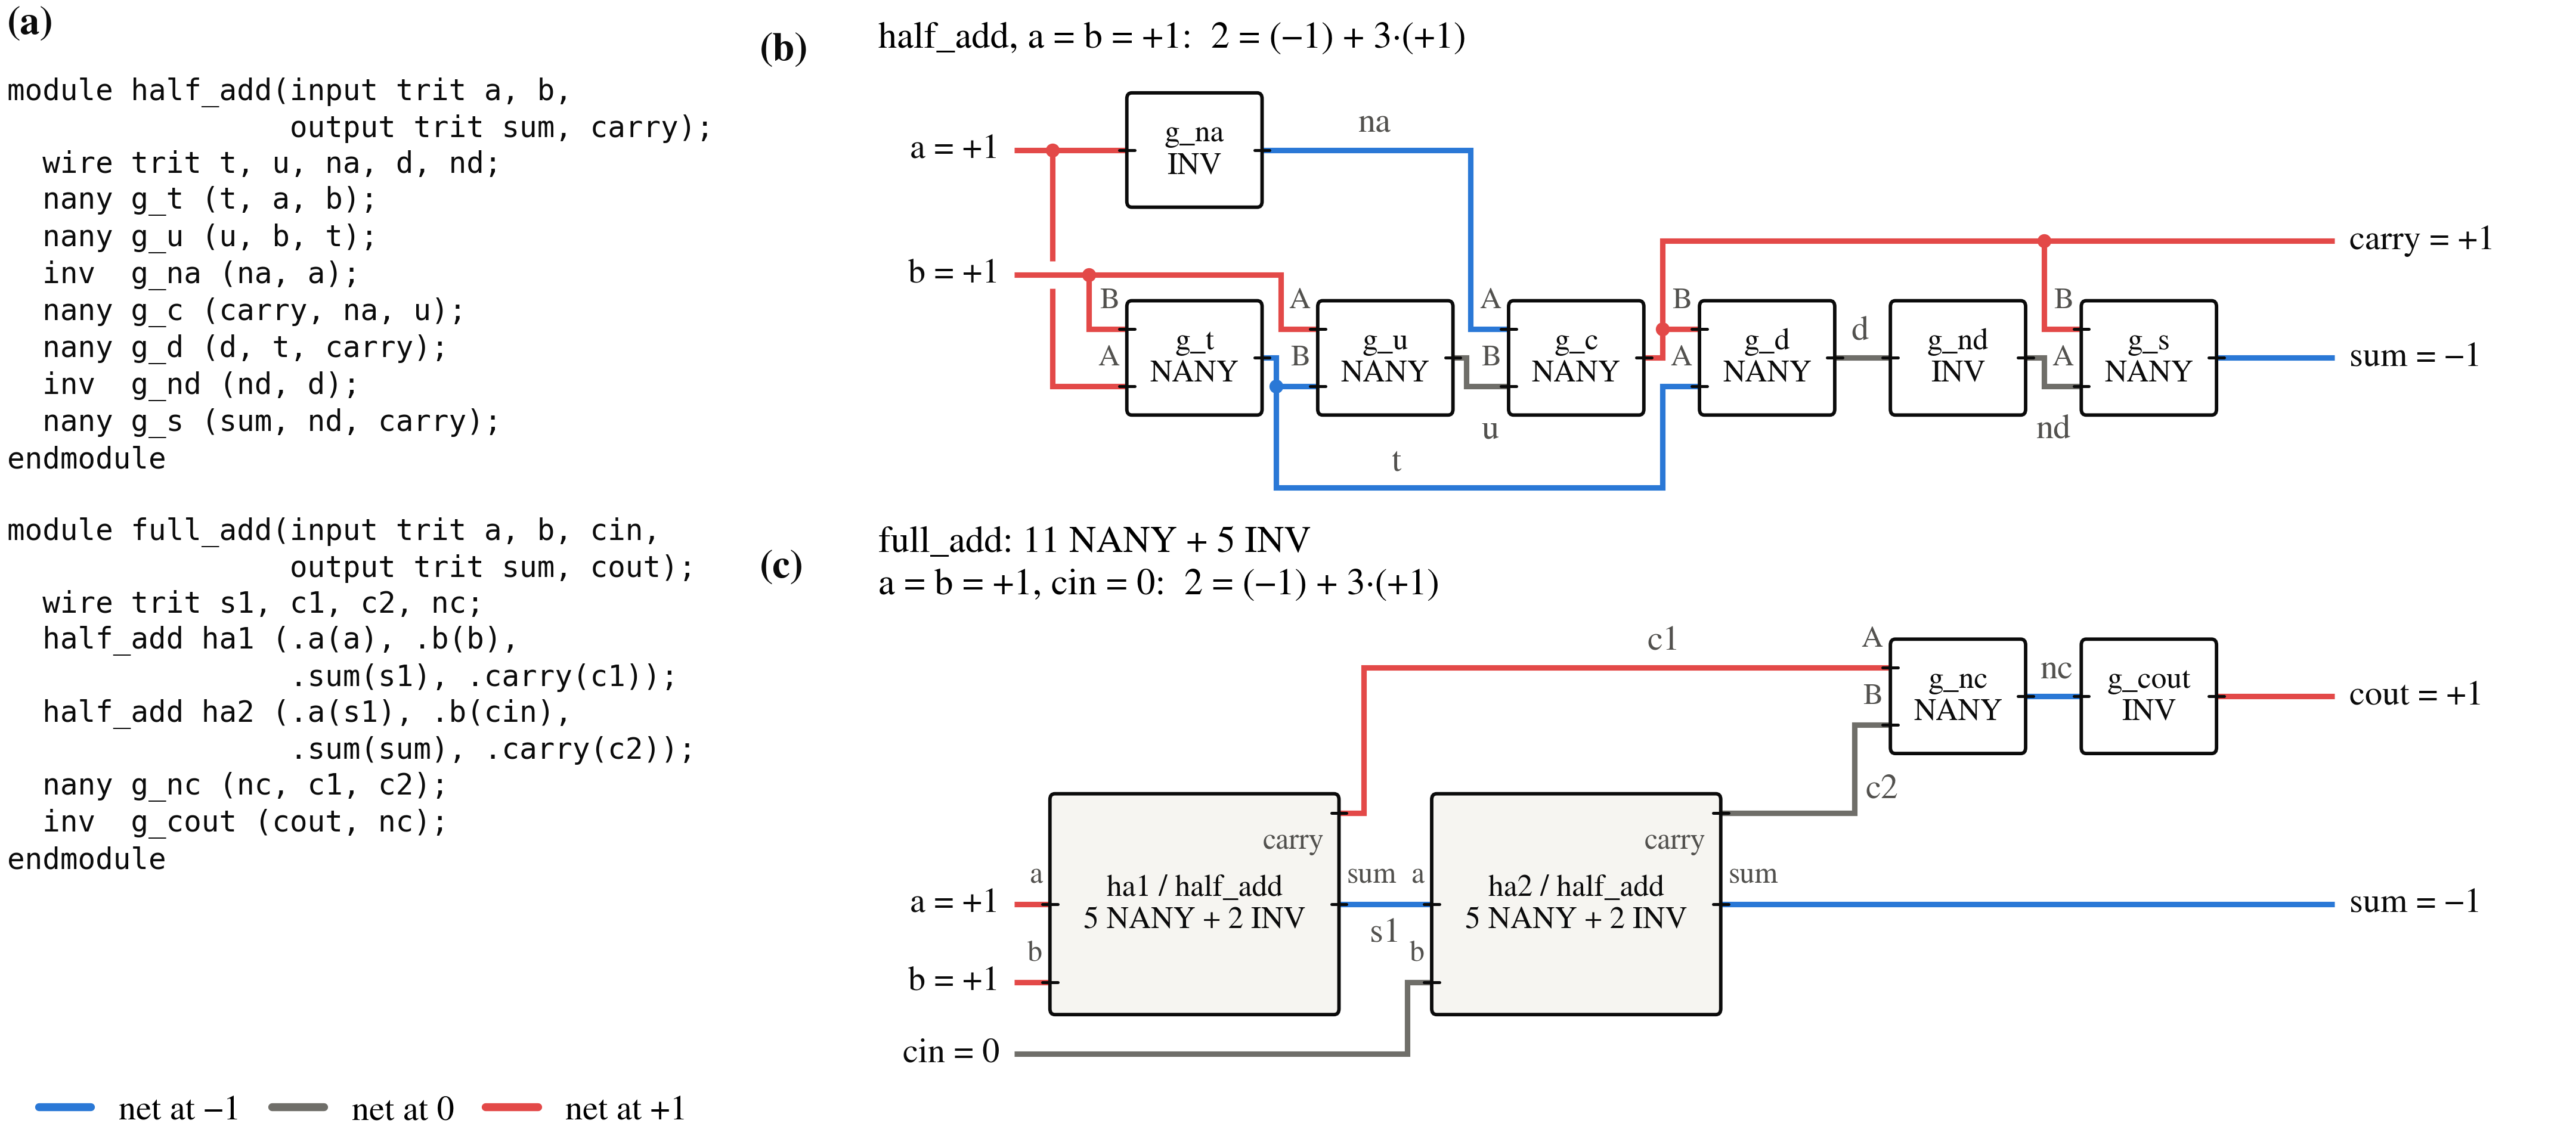

**三値セルで演算を表す** (a)共通の半加算器・全加算器の
HDL、(b)NANY 5セルと
INV 2セルにマッピングした半加算器、(c)NANY
11セルとINV 5セルからなる全加算器の階層構造。
ネットの色は、図の入力に対して整定した負・中間・正のトリット値を
示します。どちらの例でも、和とキャリーが整数としての合計を保ちます。

> **ここから分かること。** 半加算器はNANY 5セルと
> INV 2セル、全加算器は
> NANY 11セルとINV 5セルからなります。
> 全加算器の階層構造では半加算器を再利用し、それぞれのキャリーを
> NANY、続いてINVに通してまとめます。


`examples/half_add.tv`

```verilog
// Reference: balanced-ternary-logic/HALF_ADDER_SIMULATION.md.
// a + b = sum + 3*carry. Exactly five NANY and two INV cells.
module half_add(input trit a, b, output trit sum, carry);
  wire trit t, u, na, d, nd;
  nany g_t (t, a, b);
  nany g_u (u, b, t);
  inv g_na (na, a);
  nany g_c (carry, na, u);
  nany g_d (d, t, carry);
  inv g_nd (nd, d);
  nany g_s (sum, nd, carry);
endmodule
```

`examples/full_add.tv`

```verilog
`include "half_add.tv"
// Reference: balanced-ternary-logic/FULL_ADDER.md.
// a + b + cin = sum + 3*cout. Exactly eleven NANY and five INV.
module full_add(input trit a, b, cin, output trit sum, cout);
  wire trit s1, c1, c2, nc;
  half_add ha1 (.a(a), .b(b), .sum(s1), .carry(c1));
  half_add ha2 (.a(s1), .b(cin), .sum(sum), .carry(c2));
  nany g_nc (nc, c1, c2);
  inv g_cout (cout, nc);
endmodule
```


In [13]:
ha = flow.load(ROOT/"examples/half_add.tv", "half_add")
fa = flow.load(ROOT/"examples/full_add.tv", "full_add")
fa_table = fa.truth_table()                                     # all 27 input states
assert np.array_equal(fa_table["a"] + fa_table["b"] + fa_table["cin"], fa_table["sum"] + 3*fa_table["cout"])
ha_counts, fa_counts = ha.synthesize().report()["cells"], fa.synthesize().report()["cells"]
print("half_add:", ha_counts, "  full_add:", fa_counts)


half_add: {'INV': 2, 'NANY': 5}   full_add: {'INV': 5, 'NANY': 11}


In [14]:
#@title 第4章の検証：テープアウト済み回路図とセル数を照合 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('arithmetic', '4. Describe signed arithmetic in TritVerilog', requires=[]):
    details_html("Half-adder exhaustive truth table",truth_table_html(ha.design))
    details_html("Full-adder exhaustive truth table",truth_table_html(fa.design))
    ha_table = ha.truth_table()
    assert np.array_equal(ha_table["a"]+ha_table["b"], ha_table["sum"]+3*ha_table["carry"])
    schematic_sources = json.loads((ROOT/"notebook/assets/schematics/manifest.json").read_text())["schematics"]
    ha_symbols = schematic_sources["half_adder"]["instances_by_symbol"]
    fa_symbols = schematic_sources["full_adder"]["instances_by_symbol"]
    symbol_names = {"INV":"inverter", "NANY":"nany"}
    assert ha_counts == {cell:ha_symbols[symbol] for cell,symbol in symbol_names.items()}
    assert fa_counts == {cell:fa_symbols["half_adder"]*ha_counts[cell]+fa_symbols[symbol]
                         for cell,symbol in symbol_names.items()}
    table([["Circuit", "Cells", "Exhaustive input states"],
           ["half_add",ha_counts,len(ha_table["sum"])], ["full_add",fa_counts,len(fa_table["sum"])]])
    evidence("Ripple-adder HDL", (ROOT/"examples/adder.tv").read_text())


Vector,ainput,binput,sumoutput,carryoutput
1,-1,-1,+1,-1
2,-1,0,-1,0
3,-1,+1,0,0
4,0,-1,-1,0
5,0,0,0,0
6,0,+1,+1,0
7,+1,-1,0,0
8,+1,0,+1,0
9,+1,+1,-1,+1


Vector,ainput,binput,cininput,sumoutput,coutoutput
1,-1,-1,-1,0,-1
2,-1,-1,0,+1,-1
3,-1,-1,+1,-1,0
4,-1,0,-1,+1,-1
5,-1,0,0,-1,0
6,-1,0,+1,0,0
7,-1,+1,-1,-1,0
8,-1,+1,0,0,0
9,-1,+1,+1,+1,0
10,0,-1,-1,+1,-1


Circuit,Cells,Exhaustive input states
half_add,INV: 2; NANY: 5,9
full_add,INV: 5; NANY: 11,27


## 5. 式がセルに変わる過程をたどる

合成では、パラメータと階層を展開し、三値の式を簡約してから、
ライブラリのセルにマッピングします。下のAPI実行セルでは、マッピングした半加算器を
回路図として描きます。左が入力、右が和とキャリーで、各
ボックスが一つのライブラリセルです（Σ = NANY、三角 = INV）。入力トリットをクリックすると、
すべての配線の色が整定後の値に応じて変わります。

青、灰、赤の配線は、それぞれ−1、0、+1を表します。a = b = +1を試してください。入力の
合計は2で、セルはこれをsum = −1、carry = +1として表します。
2 = (−1) + 3·(+1)が成り立つためです。出力を確認する前に、
共有される中間ネットをたどってください。

最小値の符号反転はNANDに直接マッピングし、最小値をそのまま得るにはINVを追加します。
最大値にも同様にNORを使います。定数はTIEセルにマッピングします。
合成では、トリットで成り立つ恒等式を使い、二重反転の除去、共通の式の共有、
未使用論理の削除を行います。明示的に記述され、出力に寄与するゲートインスタンスは、
そのセル種別を維持します。バッファツリーでファンアウトを制限し、等価性検証では
元のソースと最終的なセル回路網を比較します。

> **ここから分かること。** マッピング後の半加算器は7セルで、
> NANY 5セルとINV 2セルからなります。
> 図に示す正の入力では、和の桁が負、
> キャリーが正となり、整数としての合計を保ちます。

この同じセル回路網を、配置ツールへの入力と、レイアウト検証の
参照回路図の両方に使います。


In [15]:
fa_net = fa.synthesize()                         # rewrite → map to cells → equivalence check
print(fa_net.report()["equivalence"])
half_net = flow.load(ROOT/"examples/half_add.tv", "half_add").synthesize()
display(value_selector(half_net))                # click input trits; every net shows its settled value


{'passed': True, 'mode': 'exhaustive', 'vectors': 27, 'seed': None}


In [16]:
#@title 第5章の検証：マッピング規則とゲートレベルTritVerilog { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('synthesis', '5. Follow an expression into cells', requires=[]):
    assert fa_net.report()["equivalence"]["passed"]
    assert fa_net.report()["equivalence"]["vectors"] == len(fa_table["sum"])
    table([["Report field", "Value"]]+[[k,v] for k,v in fa_net.report().items()],details="Full synthesis report")
    from tritflow.synth import tritverilog
    evidence("Gate-level TritVerilog", tritverilog(fa_net))
    mapping_cases = [("~a",["INV"]), ("~(a&b)",["NAND"]), ("a&b",["NAND","INV"]),
                     ("~(a|b)",["NOR"]), ("a|b",["NOR","INV"]), ("nany(a,b)",["NANY"]),
                     ("1'tT",["TIEN"]), ("1't0",["TIEZ"]), ("1't1",["TIEP"])]
    mapping_rows = [["HDL expression", "Computed cells"]]
    for expr, expected_cells in mapping_cases:
        mapped = flow.loads(f"module mapping(input trit a,b,output trit y); assign y={expr}; endmodule").synthesize()
        assert sorted(inst.cell for inst in mapped.instances) == sorted(expected_cells)
        mapping_rows.append([expr, mapped.report()["cells"]])
    table(mapping_rows,details="Expression-to-cell mapping checks")


Report field,Value
top,full_add
cells,INV: 5; NANY: 11
total_cells,16
logic_depth,12
hierarchy,<top>: INV: 1; NANY: 1; ha1: INV: 2; NANY: 5; ha2: INV: 2; NANY: 5
max_fanout,3
fanout_limit,4
equivalence,passed: True; mode: exhaustive; vectors: 27; seed: None


HDL expression,Computed cells
~a,INV: 1
~(a&b),NAND: 1
a&b,INV: 1; NAND: 1
~(a|b),NOR: 1
a|b,INV: 1; NOR: 1
"nany(a,b)",NANY: 1
1'tT,TIEN: 1
1't0,TIEZ: 1
1't1,TIEP: 1


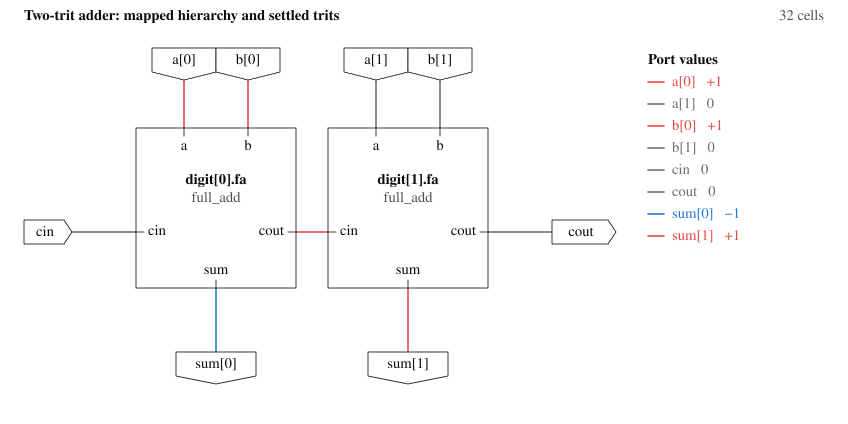

In [17]:
sch = net.schematic(inputs={"a[0]": 1, "a[1]": 0, "b[0]": 1, "b[1]": 0, "cin": 0}, net_names=True,
                    title="Two-trit adder: mapped hierarchy and settled trits")
display(sch)                                     # the synthesized netlist, drawn as a schematic


## 6. 信号を配線し、静的電流を供給する

配置では、配線チャネルを挟んでセルを行状に並べます。乱数シードを指定した
焼きなまし探索で推定配線長を短縮し、格子ベースの配線ツールで
二層のメタルを使ってピンを接続します。M1の信号配線はチャネル内に限定し、M2は
障害物のないトラックでセル上を通せます。三つの電源には、
セルの静的電流を流せるだけの配線断面と給電点が必要です。

配線ツールは接続、間隔、ビアの囲みを検査してから、PDKの
描画DRCデッキを実行します。LVSは抽出した素子と接続を、
マッピング後の回路図と比較します。図では演算の桁ごとにセルを色分けし、
配置中に記録した半周囲長配線長（HPWL）を示しています。



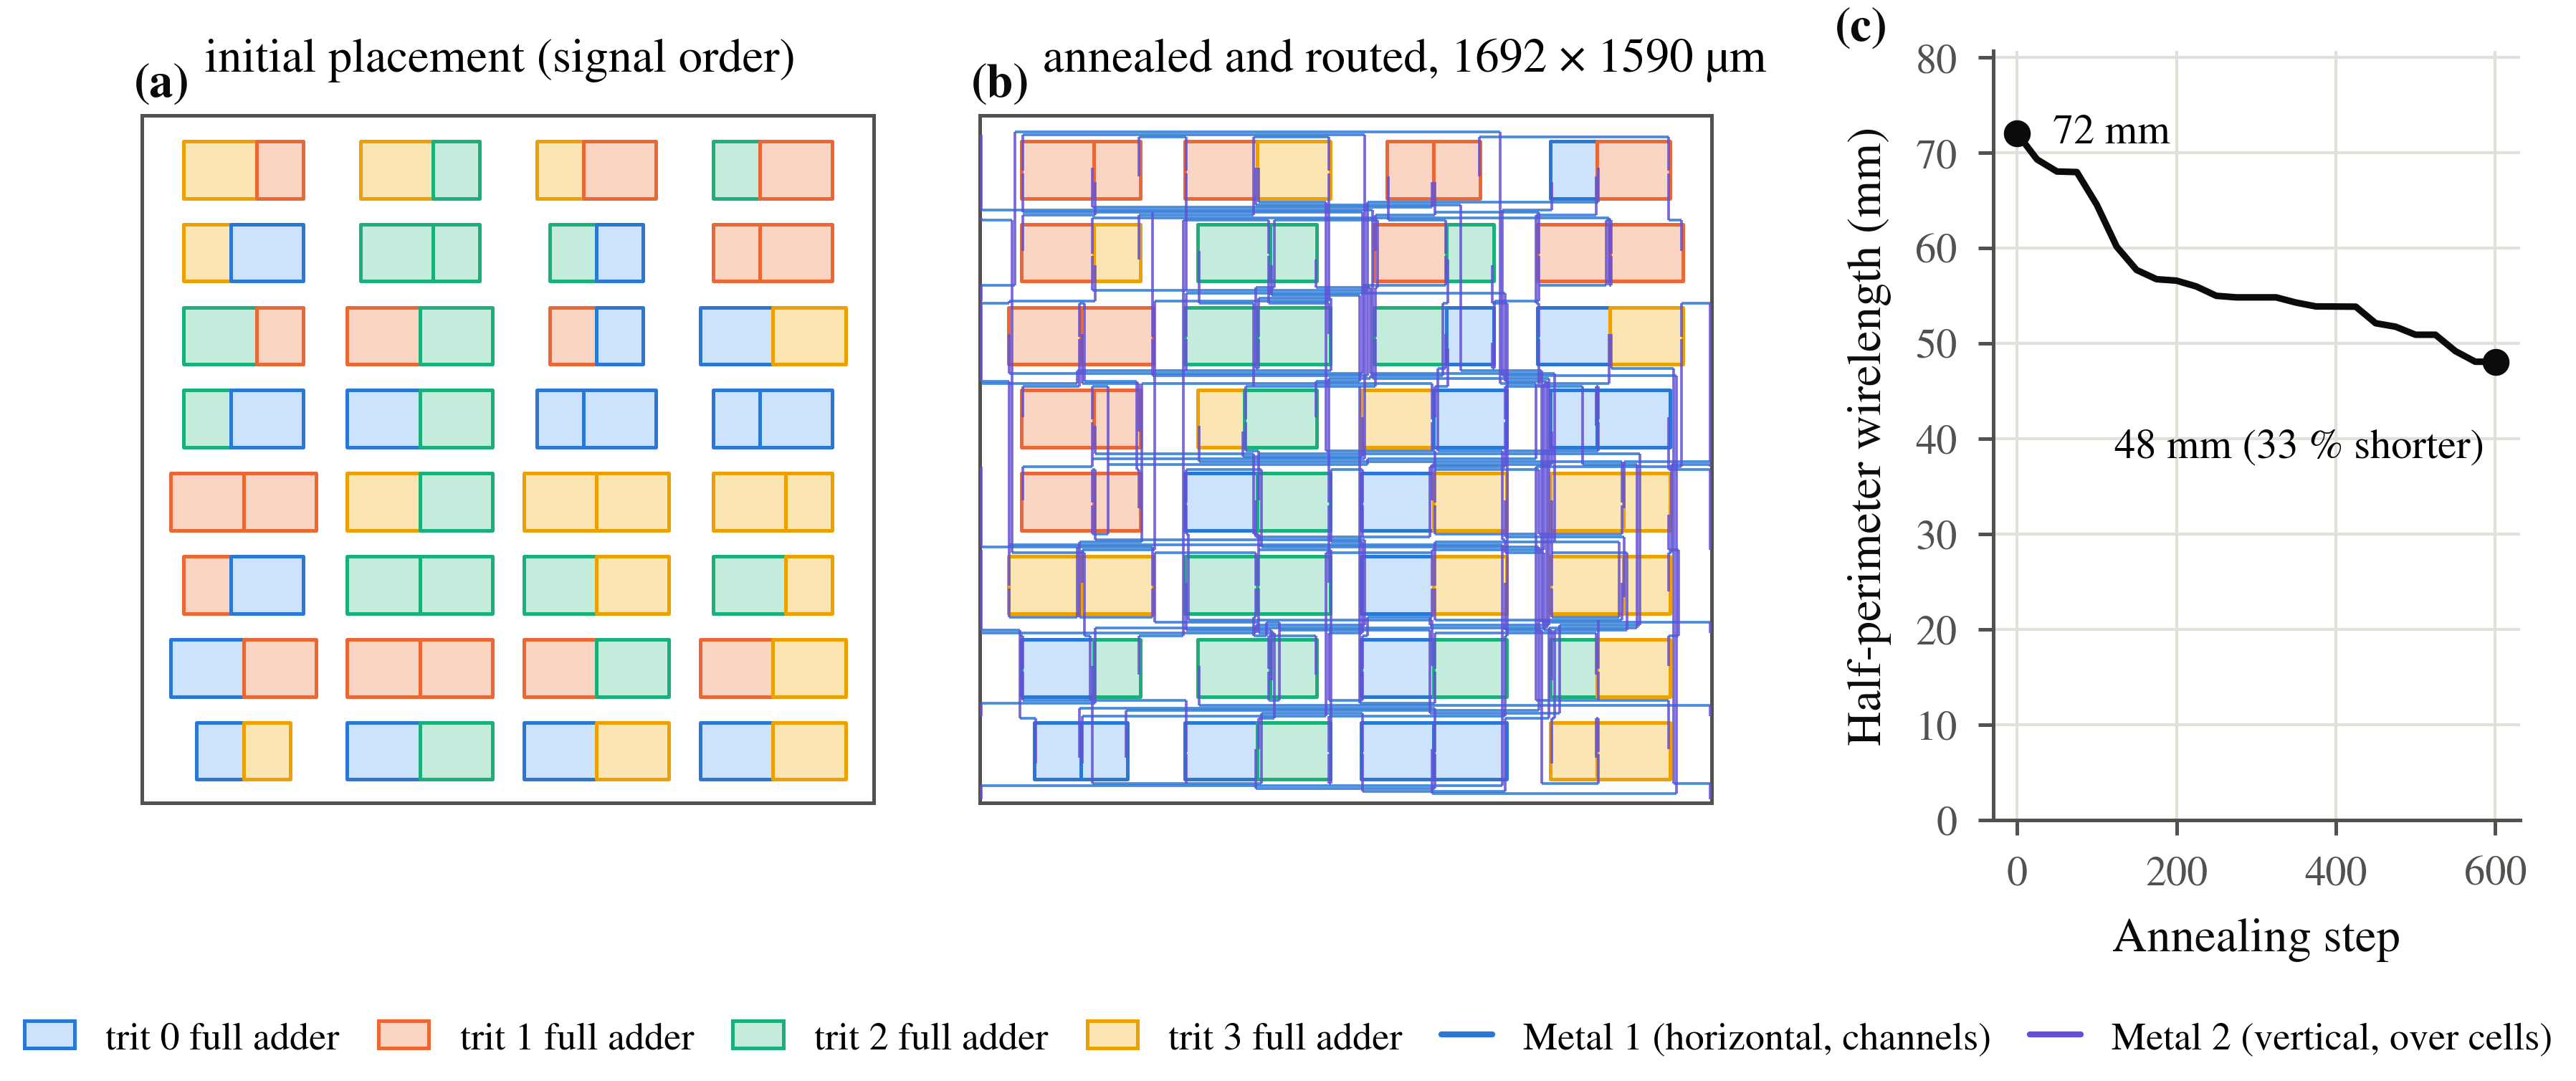

**図の加算器の配置配線** (a)信号順の初期配置、
(b)焼きなましと配線を終えた4トリットのレイアウト。
実行ID paper/adder4 · seed 7での寸法は1692 × 1590 µmです。(c)は
記録したセル端子のHPWLです。
焼きなましによってHPWLは72.04から
48.07 mmとなり、33.27%減少します。
セルの色は全加算器の桁を表し、配線は
チャネル内の水平M1と、セル上の垂直M2を区別しています。

> **ここから分かること。** 図の4トリット加算器の寸法は
> 1692 × 1590 µmです。焼きなましにより、セル端子のHPWLは
> 72.04から48.07 mmとなり、
> 33.27%減少します。

以降の電気的な比較では、このレイアウトから
素子と配線形状の両方を取り出します。


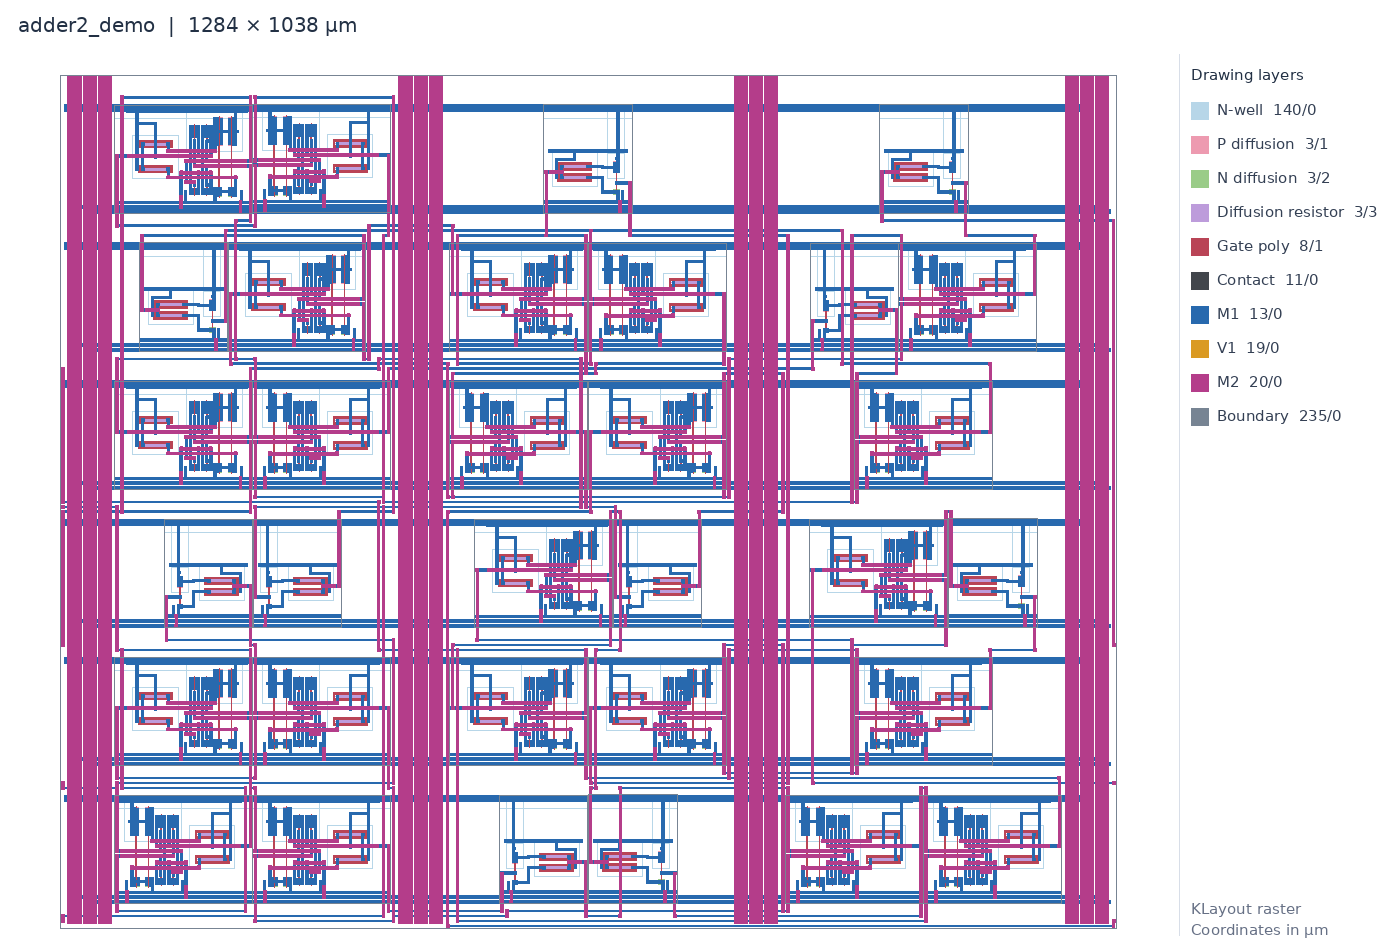

32 cells in 6 rows · die 1284 × 1038 µm · utilization 47 % · annealing shortened HPWL by 48 %


In [18]:
png = render_gds(lay.gds_path, out/"adder2_demo.layout.png", top=net.top)   # KLayout render of the GDS
display(Image(filename=str(png), width=760))
s = lay.stats
print(f"{s['instance_count']} cells in {s['row_count']} rows · die {s['die_size_um'][0]:.0f} × {s['die_size_um'][1]:.0f} µm"
      f" · utilization {100*s['utilization']:.0f} % · annealing shortened HPWL by {s['hpwl_improvement_pct']:.0f} %")


In [19]:
#@title 第6章の詳細と任意のフロアプラン実験 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('pnr', '6. Route signals and feed the standing current', requires=['opening']):
    table([["Metric", "Two-trit adder"]]+[[k,v] for k,v in lay.stats.items()],details="Full physical statistics")
    assert all(check["clean"] for check in lay.data["checks"].values())
    assert lay.stats["routed_nets"] == len(net.nets())
    assert {p["orient"] for p in lay.data["placements"]} <= {"R0","MY"}
    evidence("Live adder physical checks",lay.data["checks"])
    table([["Initial / final cell-terminal HPWL (µm)",
            [lay.data["history"][i]["hpwl"] for i in (0,-1)]]])
    if EXTENDED:
        show(placement_animation(lay.data))
    if EXTENDED:
        show(routing_progress(lay.data))
    RUN_FLOORPLAN_EXPERIMENT = False  # opt in after changing the controls below
    EXPERIMENT_ROWS, EXPERIMENT_ANNEAL_STEPS, EXPERIMENT_SEED = None, 2400, 7
    if RUN_FLOORPLAN_EXPERIMENT:
        folder = BUILD/"floorplan_experiment"
        def route_experiment():
            routed = net.place_and_route(output_dir=folder, rows=EXPERIMENT_ROWS,
                       anneal_steps=EXPERIMENT_ANNEAL_STEPS, seed=EXPERIMENT_SEED)
            drc, lvs = routed.drc(), routed.lvs()
            assert drc["clean"] and lvs["matched"]
            return {"stats":routed.stats, "drc":drc, "lvs":lvs}
        trial = cache.run("floorplan-experiment", {"net":net.to_json(),"rows":EXPERIMENT_ROWS,
                         "steps":EXPERIMENT_ANNEAL_STEPS,"seed":EXPERIMENT_SEED}, route_experiment,
                         artifacts=[folder/f"{net.top}.gds",folder/f"{net.top}.pnr.json"])
        assert trial["drc"]["clean"] and trial["lvs"]["matched"]
        table([["Measured floorplan experiment",trial["stats"]]])
        show(placement_animation(flow.load_layout(net,folder).data))


Metric,Two-trit adder
die_size_um,"[1284, 1038]"
die_area_um2,1.333e+06
wirelength_um,M1: 1.443e+04; M2: 1.499e+04
via_count,246
power_via_count,480
utilization,0.473
instance_count,32
row_count,6
net_count,37
spans_per_row,3


Initial / final cell-terminal HPWL (µm),"[2.756e+04, 1.421e+04]"


## 7. レイアウト後も正しく動くか？

タイミング評価では、出力がいつ有効なトリットになるかを定める必要があります。ここでは、
入力ランプの開始から、出力が目標値の±0.5 V帯に入り、
その入力区間の終わりまで帯内に留まるまでの時間とします。同じ抽出素子について、
推定配線容量の有無で比較し、その後、出力負荷と
加算器の桁数を増やします。キャリー経路と静的電力について、それぞれ予想を立てて確かめます。

**まず予想する。** 全加算器の一桁分を使い、リップルキャリー経路を見積もります。
キャリーの整定時間を$t_{c,1}$、キャリーと和のうち遅い方の
出力端点の整定時間を$t_{e,1}$とします。一桁増やすごとにキャリー段が一つ加わります。

$$
t_{\mathrm{hand}}(N)=t_{e,1}+(N-1)t_{c,1}.
$$

全入力がゼロの状態では、マッピング後のセル数を数え、各セルのゼロ入力時のDC
電力を合計します。各レールの電流は、SPICEの電圧源の符号規約に従います。

$$
P_c(0)=-\sum_{r\in\{DD,MID,SS\}} V_r I_{r,c}(0),\qquad
P_{\mathrm{hand}}(N)=\sum_c n_c(N)P_c(0).
$$



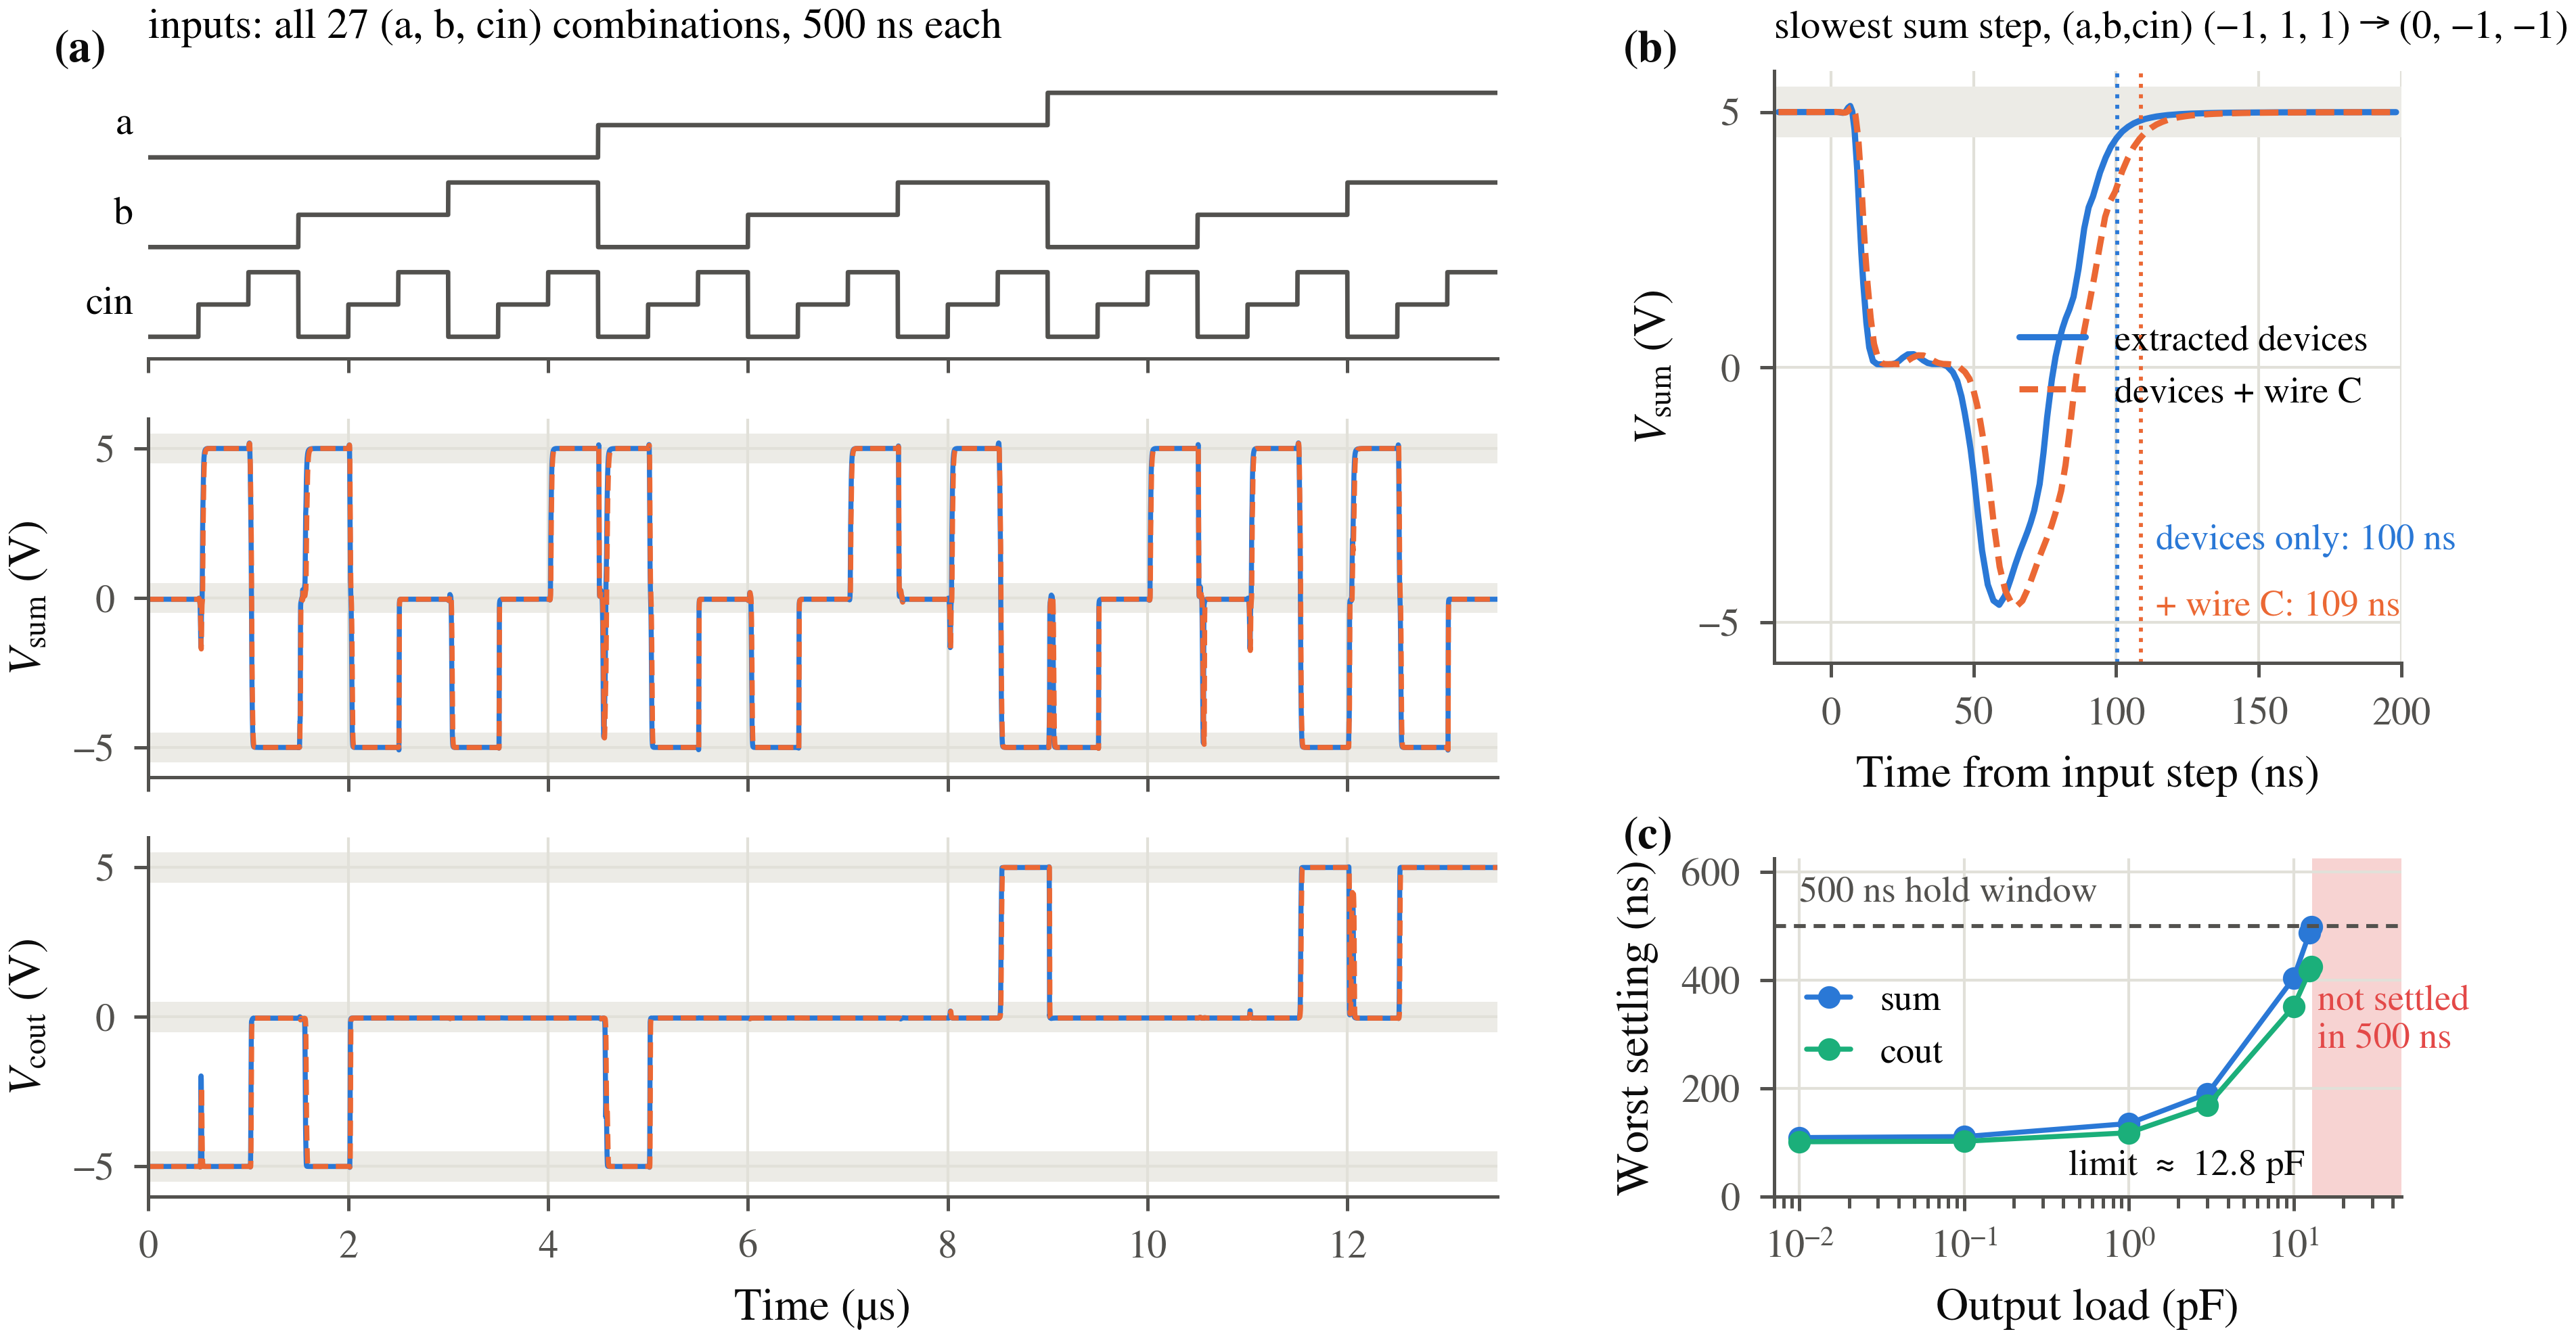

**全加算器の整定と、観測された負荷の限界** (a)実行ID
paper/full_add · seed 19の全加算器について、27入力状態を
500 ns間隔、
各出力10 fFの条件で与えます。素子のみの場合と、素子に配線容量を加えた場合の
出力は、いずれも±0.5 Vの判定基準を満たします。
(b)配線容量を含む場合に和の整定が最も遅くなる遷移では、同じ抽出素子に
推定配線容量を加えると、許容帯への最終進入時刻が100.3から108.6 nsへ
変わります。
(c)両出力に等しい負荷を与える掃引では、500 nsの
入力区間内での合格点と不合格点が
12.81から12.97 pFの間にあります。


sum[1]  devices only  132.1 ns  →  with wire C  149.3 ns
sum[0]  devices only  124.6 ns  →  with wire C  138.5 ns
cout    devices only  102.1 ns  →  with wire C  107.0 ns


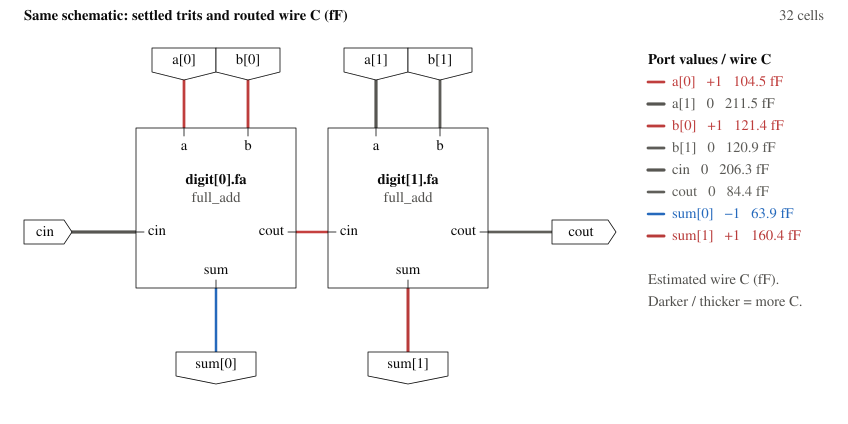

In [20]:
pre = lay.extract(wire_c=False).simulate(vectors, load=LOAD_F, expected=adder_reference,
                                         nodeset=guesses, **CONDITIONS)    # same devices, no wire C
for pin, t_post in post["measurements"]["max_settling_s"].items():
    print(f"{pin:7s} devices only {1e9*pre['measurements']['max_settling_s'][pin]:6.1f} ns"
          f"  →  with wire C {1e9*t_post:6.1f} ns")
wire_report = lay.result.net_parasitics()                                 # routed wire C per logical net
routed_sch = sch.annotate(parasitics=wire_report, title="Same schematic: settled trits and routed wire C (fF)")
display(routed_sch)


In [21]:
#@title 第7章の検証：同一素子で配線容量の有無を比較 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('pre', 'Chapter 7: Does the layout still work?', requires=['opening']):
    assert pre["measurements"]["passed"]
    assert pre["stimulus"]["vectors"] == demo["stimulus"]["vectors"]
    assert pre["stimulus"]["hold_s"] == demo["stimulus"]["hold_s"]
    assert pre["stimulus"]["step_s"] == demo["stimulus"]["step_s"]
    assert routed_sch.scene is sch.scene
    evidence("Schematic wire-C scope (excludes receiving-pin C)",wire_report["assumptions"])
    if EXTENDED:
        for load in [10e-15,1e-12]:
            loaded = cache.run(f"adder2-load-{load:g}", {"vectors":vectors,"load":load}, lambda:
                lay.extract().simulate(vectors, load=load, expected=adder_reference,
                                       hold_s=2e-6, step_s=2e-9, timeout=180))
            assert loaded["measurements"]["passed"], loaded["measurements"]
            print(load, loaded["measurements"]["passed"], loaded["measurements"]["max_settling_s"])


中間レベルの維持には電力が必要です。この加算器のセル構成では、マッピング後のセルあたり4.17 mW、6トリットで0.4 Wに達します。素子寸法によって、電流と電圧精度のトレードオフが変わります。

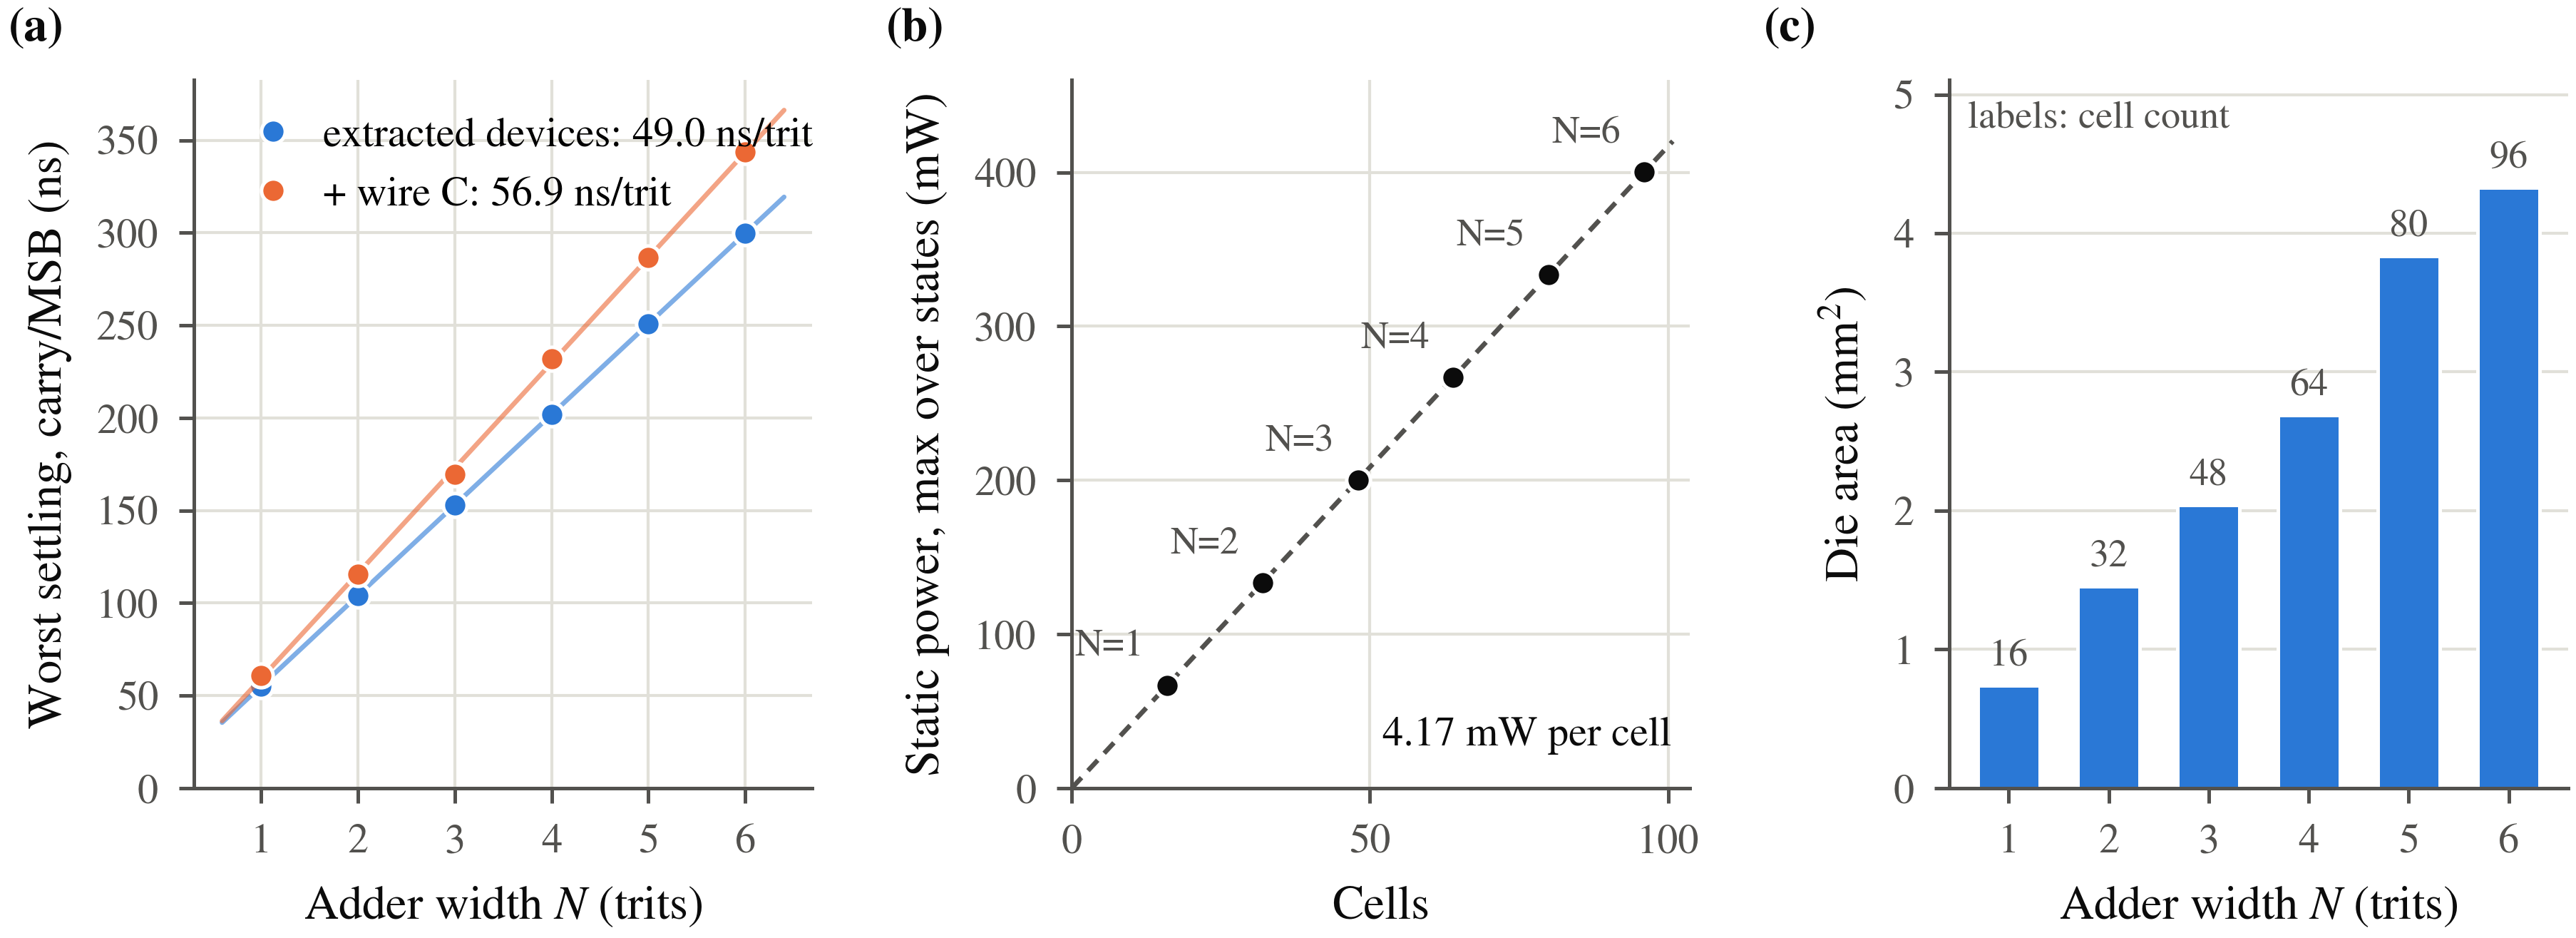

**一つのパラメータ付きHDLソースから生成したリップルキャリー加算器**
1–6トリットの加算器を合成し、
配置配線、描画DRC/LVS検証を行い、各出力10 fF、
公称モデルでシミュレーションします（実行系列 width-sweep · seed 7）。
(a)記録したキャリー出力端点の整定時間に対する近似直線の傾きは、
抽出素子のみで48.95 ns/trit、
推定配線容量を加えると56.88 ns/tritです。
(b)試験した状態でのDC電力の最大値から、この加算器のセル構成では、
マッピング後のセルあたり実効的に4.169 mWとなります。
(c)ダイ面積とセル数は、桁数を増やす際の物理的なコストを示します。

> **ここから分かること。** 全加算器の27状態を
> 500 nsの入力区間で試すと、負荷試験の合格点と不合格点は、
> 各出力12.81から12.97 pFの間にあります。
> 桁数1–6に対する近似直線では、
> キャリー出力端点の整定時間の傾きが、素子のみで48.95 ns/trit、
> 配線容量を含めると56.88 ns/tritです。
> 試験した状態の静的電力の近似値は、マッピング後のセルあたり4.169 mWで、
> 6桁では400.2 mWに達します。

図に示す最大桁数の加算器について、手計算値と比較してください。遅延の
比較には、プロットと同じキャリーおよび和の最上位桁の出力端点を使います。
電力の比較には、別途、全入力がゼロのDC状態を使います。

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">評価量</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">手計算値</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">SPICE</th></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">キャリー経路の整定時間、素子のみ (ns)</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">278.9</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">299.7</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">全入力ゼロ時の静的電力 (mW)</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">400.2</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">400.2</td></tr>
</table>
</div>

入力を一定に保っても、この電流は流れます。スイッチング周波数を
下げるだけではなくなりません。別途行う電源レールの抵抗網解析の結果は付録Bに示します。


In [22]:
#@title 第7章の記録済み実験：桁数と負荷の掃引 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('published', 'Chapter 7: Does the layout still work?', requires=[]):
    from tritflow.sim.scaling import load_scaling
    from tritflow.sim.load_sweep import load_sweep_results
    from tritflow.viz.scaling import scaling_figure, load_sweep_figure, scaling_fit_figure
    for filename, loader, figure in [("adder_scaling.json",load_scaling,scaling_figure),
                                      ("full_add_load_sweep.json",load_sweep_results,load_sweep_figure)]:
        published = ROOT/"results"/filename
        result = loader(published)
        records = result["rows"] if filename == "adder_scaling.json" else [result]
        compatible_sources = []
        for record in records:
            compatible_sources.extend(verify_publication_sources(record,ROOT,PDK_ROOT))
        if compatible_sources:
            evidence("Recorded-source compatibility: exact optional schematic delegate only",compatible_sources)
        evidence("Published experiment scope: "+filename,result.get("coverage",result.get("scope")))
        evidence("Published limits / conditions",result.get("limits",result.get("conditions")))
        if filename == "adder_scaling.json":
            table([["Width", "Routing realization", "Recorded state", "PASS", "Error"]]+
                  [[r["n"],f"width-sweep/adder{r['n']} · seed {r['seed']}",r["state"],r["passed"],r["error"]] for r in result["rows"]])
        else:
            table([["Measured boundary (F)",result["boundary"]], ["Boundary found",result["boundary_found"]],
                   ["Outputs / input-state count",[result["outputs"],len(result["vectors"])]]])
        if EXTENDED:
            show(figure(result))
        if filename == "adder_scaling.json":
            if EXTENDED:
                show(scaling_fit_figure(result))


Width,Routing realization,Recorded state,PASS,Error
1,width-sweep/adder1 · seed 7,complete,True,None
2,width-sweep/adder2 · seed 7,complete,True,None
3,width-sweep/adder3 · seed 7,complete,True,None
4,width-sweep/adder4 · seed 7,complete,True,None
5,width-sweep/adder5 · seed 7,complete,True,None
6,width-sweep/adder6 · seed 7,complete,True,None


Measured boundary (F),last_pass_f: 1.281e-11; first_fail_f: 1.297e-11; coarse_first_fail_f: 3e-11; width_f: 1.563e-13
Boundary found,True
Outputs / input-state count,"[[sum, cout], 27]"


### 静的タイミング解析で予測し、SPICEで確かめる

一桁分からの見積もりで、桁数に対する傾向を説明できます。三値の静的タイミング
解析（STA）では、実際のセル経路を評価します。各タイミングアークは、
入力・出力トリットの遷移方向と他の入力の状態ごとに特性評価し、
遷移前後の電圧の中点を使います。そのため、中間レベルを含む
ステップと、電源レール間の全振幅ステップとでは、判定しきい値が異なります。

STAは中点間の遅延を積み上げ、測定した各出力の
スルーを次のセルに渡します。最終出力の中点から
±0.5 V帯に入って留まるまでの時間は、出力端点で一度だけ加えます。
各ゲートで整定時間を丸ごと加えると、中間段での整定までの残り時間を重複して数えてしまいます。
条件をそろえた比較では、順序付きのピンイベントで再収束経路を表し、
SPICEと同じ入力遷移集合、配線容量、負荷、入力ランプを使います。
`vector_pairs`には、遷移前後の全入力を記した辞書を渡してください。



下のセルでは、今回生成した加算器に配線後の配線容量を与えてSTAを実行し、上のSPICE実行結果と比較します。


In [23]:
from tritflow.sta import analyze
states = [dict(zip(inputs, v)) for v in vectors]
wire_caps = {name: e["wire_capacitance_f"] for name, e in wire_report["nets"].items()}
timing = analyze(net, vector_pairs=list(zip(states, states[1:])), wire_caps=wire_caps,
                 output_load_f=LOAD_F, input_transition_s=EDGE_S)    # milliseconds, no SPICE
for pin, t_sta in timing.arrival.items():
    print(f"{pin:7s} STA {1e9*t_sta:6.1f} ns   SPICE {1e9*post['measurements']['max_settling_s'][pin]:6.1f} ns")


sum[1]  STA  141.0 ns   SPICE  149.3 ns
sum[0]  STA  132.4 ns   SPICE  138.5 ns
cout    STA  114.3 ns   SPICE  107.0 ns


In [24]:
#@title 第7章のSTA比較表とクリティカルパス { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('sta', 'Chapter 7: Does the layout still work?', requires=['opening']):
    rows = [[pin, t*1e9, post["measurements"]["max_settling_s"][pin]*1e9,
             100*(t/post["measurements"]["max_settling_s"][pin]-1)] for pin, t in timing.arrival.items()]
    table([["Output", "STA (ns)", "Post-layout SPICE (ns)", "Difference (%)"]]+rows)
    assert set(timing.arrival) == set(post["measurements"]["max_settling_s"])
    evidence("STA critical path and assumptions", {"critical_output": timing.critical_output,
             "critical_path": timing.critical_path, "assumptions": timing.assumptions})


Output,STA (ns),Post-layout SPICE (ns),Difference (%)
sum[1],141,149.3,-5.592
sum[0],132.4,138.5,-4.392
cout,114.3,107,6.851


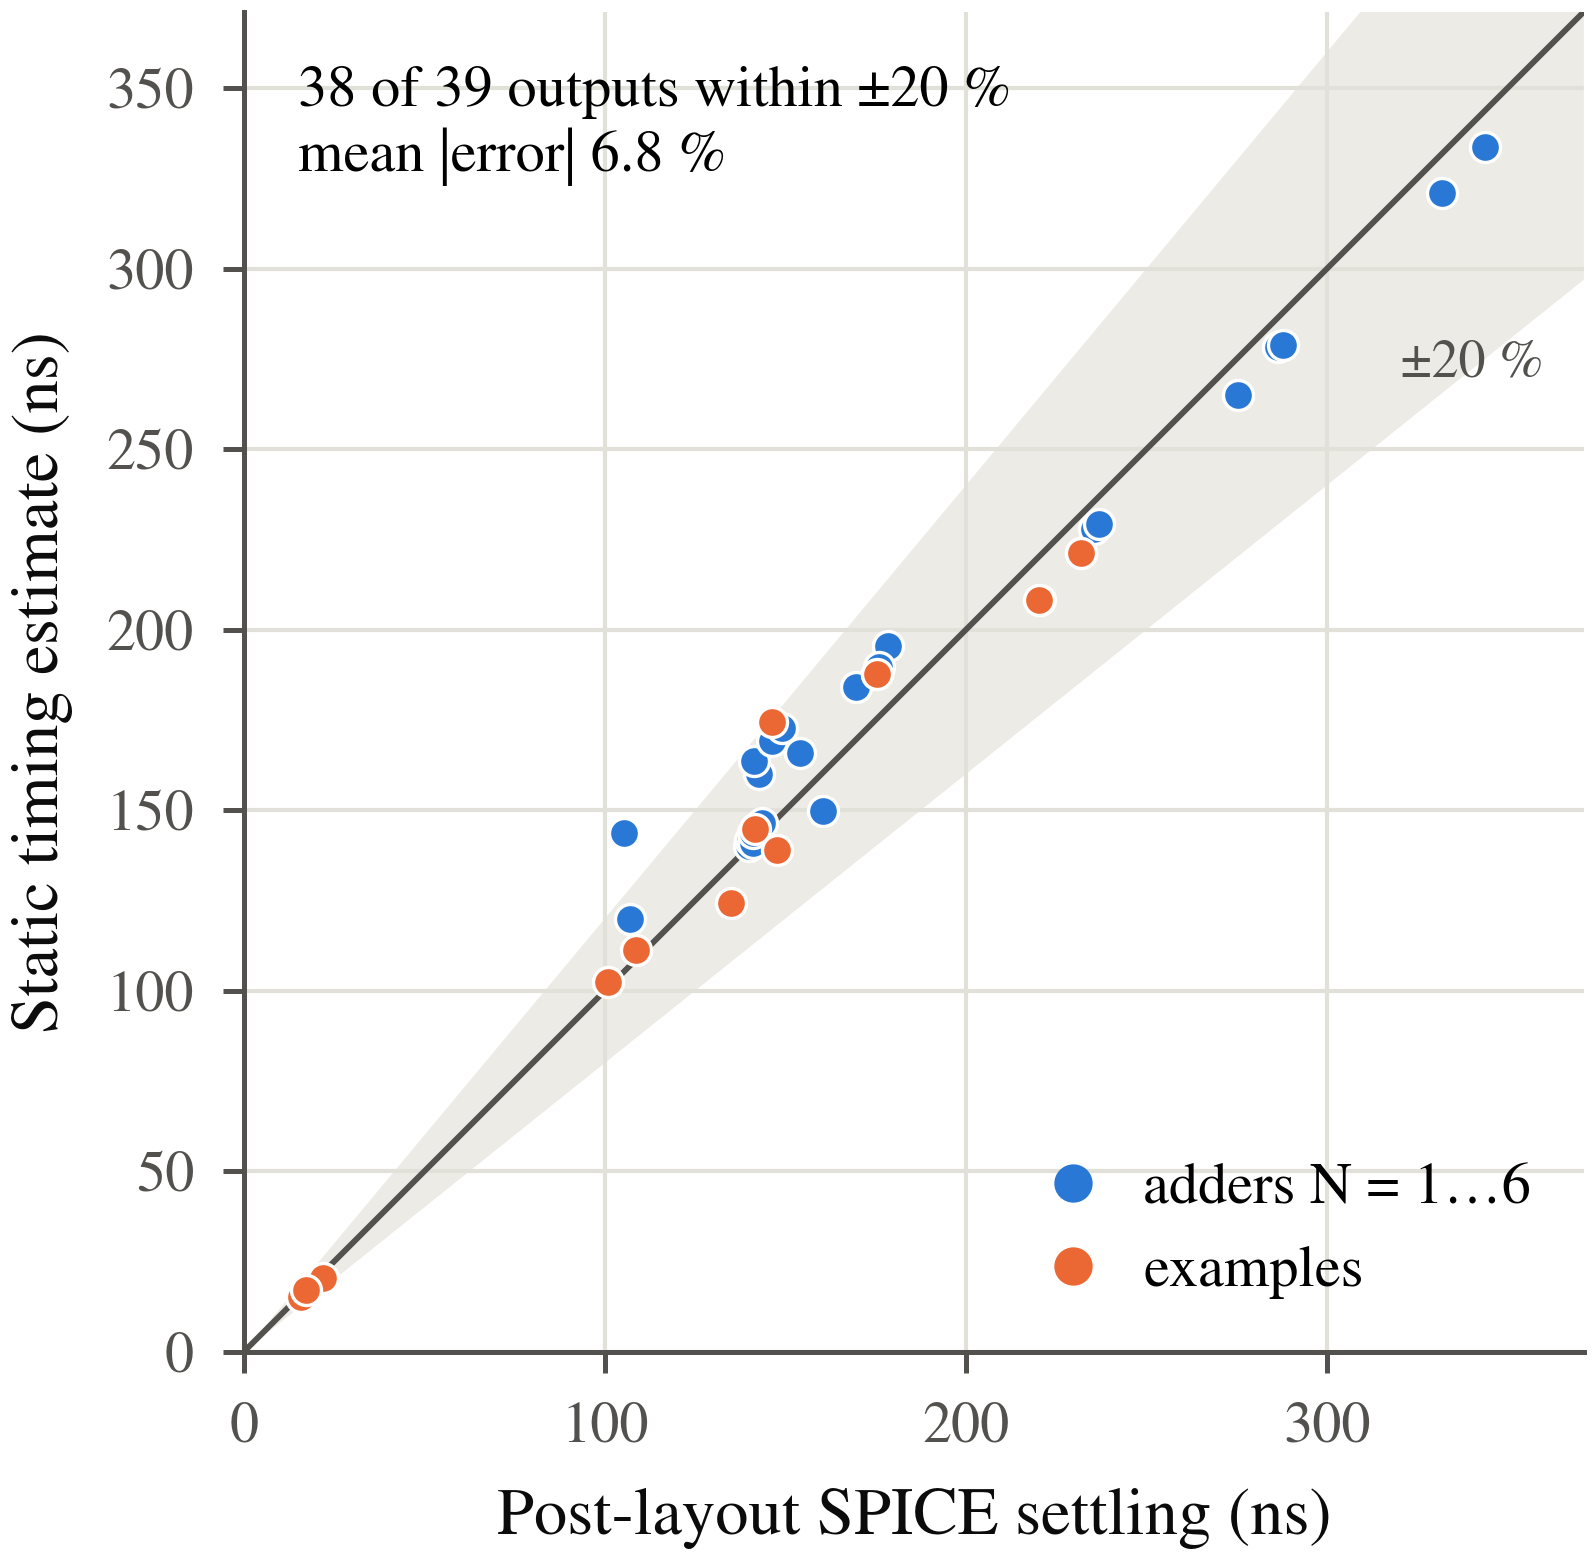

**三値の静的タイミング解析と抽出回路のSPICEとの比較** 各点は、
同じ入力遷移集合に対する、各出力の最大値同士を比較したものです。
遷移クラスごとの中点遅延、伝搬させたスルー、出力端点で一度だけ加える整定までの残り時間を
用います。直線は両者の一致、網掛けは±20%を示します。
例題の設計と
1–6桁の加算器を通じて、39個中
38個の出力最大値がこの帯内に入り、
平均絶対パーセント誤差は6.782%です（配線結果ID：
STA scaling: adder1, adder2, adder3, adder4, adder5, adder6; STA example: adder4, full_add, mac1, mul1）。
ここにはプロットしていない別の保守的な包絡値は、平均で
実測した最大値の2.182×となり、保存済みの
公称条件のケースを保守的に覆いますが、保証されたアナログ的な上限ではありません。

> **ここから分かること。** 記録済みの検証では、同じ入力遷移集合で比較した
> 39個中38個の出力最大値が
> SPICEの±20%以内に入り、平均絶対
> パーセント誤差は6.782%です。例外は`scaling/adder2/cout`で、
> 36.48%の過大予測です。イベントモデルでは、部分的にしか振れないパルスの振幅と履歴を
> 表現していません。

別の保守的な上限値は、平均で出力最大値の2.182×、
つまり約二倍の余裕を持ち、保存済みの公称条件のケースを覆います。
ただし、未試験の波形やプロセス・電圧・温度コーナーを保証するものではありません。


## 8. 回路を変更し、検証まで一巡する

符号検出器、符号付き比較器、乗算器、min/maxソータから選んでください。
数学的な仕様を読み、下のHDLを編集して、
設計セルを実行します。まず真理値表で、元のソースとマッピング後の論理の両方を、
独立した整数演算の正解値と比較します。その後は冒頭の加算器と同じ手順で、配置、配線、描画DRC、LVS、
抽出後シミュレーションを行います。

*コードセルで回路を選択してHDLを確認し、
式を変更してください。生成されるレイアウトと波形は、編集したソースに対応します。*

等価な実装に変更するときは、算術の参照仕様を保ってください。
意図する機能を変える場合は、その仕様も編集します。
最初の実験として、ソータの最小値を最大値に置き換えてみてください。
真理値表の検証によって、配線前に不一致が検出されます。



**最初に試す、検証に通る編集：** 下に表示するソータは、最小値を`~((~a) | (~b))`で実装しています。独立したソートの参照仕様を保ったまま実行し、新しくマッピングした回路図とGDSを生成してください。


In [25]:
# Your circuit: edit this TritVerilog, then run the cells below.
# This first edit writes min(a, b) through De Morgan, as -max(-a, -b).
source = """
module minmax(input  trit a, b,
              output trit lo, hi);
  assign lo = ~((~a) | (~b));   // min(a, b)
  assign hi = a | b;            // max(a, b)
endmodule
"""


In [26]:
from examples.curated import DESIGNS
from tritflow.synth import evaluate_netlist
CHOICE = os.environ.get("TRITFLOW_CIRCUIT", "minmax")   # or: sign | compare2 | mul2
example = DESIGNS[CHOICE]                                # its independent arithmetic reference
if CHOICE != "minmax":
    source = example.path.read_text()
print(example.description)


Sort two scalar trits into ascending order


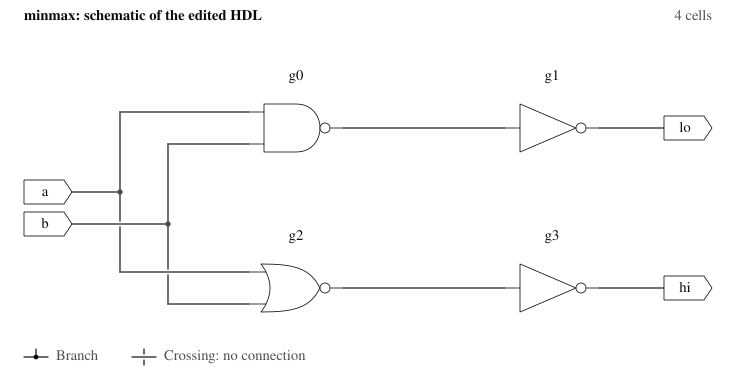

In [27]:
custom_circuit = load_edited(example, source, BUILD/"your_circuit"/"source"/example.top)
custom = custom_circuit.synthesize()                                     # your HDL → cells
display(custom.schematic(net_names=True, title=f"{custom.top}: schematic of the edited HDL"))


In [28]:
#@title 第8章の検証：すべての入力状態を独立した算術の正解値と照合 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('custom_check', 'Chapter 8: Change the circuit and close the loop', requires=[]):
    truth = custom_circuit.truth_table()
    pins = custom_circuit.design.inputs
    planned = list(zip(*(truth[p] for p in pins)))
    oracle = example.oracle(pins)
    mapped_truth = evaluate_netlist(custom,{p:truth[p] for p in pins})
    for i, vector in enumerate(planned):
        expected = oracle(vector)
        source_actual = {p:int(truth[p][i]) for p in expected}
        mapped_actual = {p:int(mapped_truth[p][i]) for p in expected}
        if source_actual != expected or mapped_actual != expected:
            raise AssertionError(f"Independent reference disagreement at {dict(zip(pins,vector))}: "
                                 f"expected {expected}, HDL {source_actual}, cells {mapped_actual}. "
                                 "Check your edit; change the arithmetic reference only if you intend a different function.")
    details_html("Edited-circuit exhaustive truth table",truth_table_html(custom,max_rows=len(planned)))


Vector,ainput,binput,looutput,hioutput
1,-1,-1,-1,-1
2,-1,0,-1,0
3,-1,+1,-1,+1
4,0,-1,-1,0
5,0,0,0,0
6,0,+1,0,+1
7,+1,-1,-1,+1
8,+1,0,0,+1
9,+1,+1,+1,+1


DRC clean: True · LVS match: True


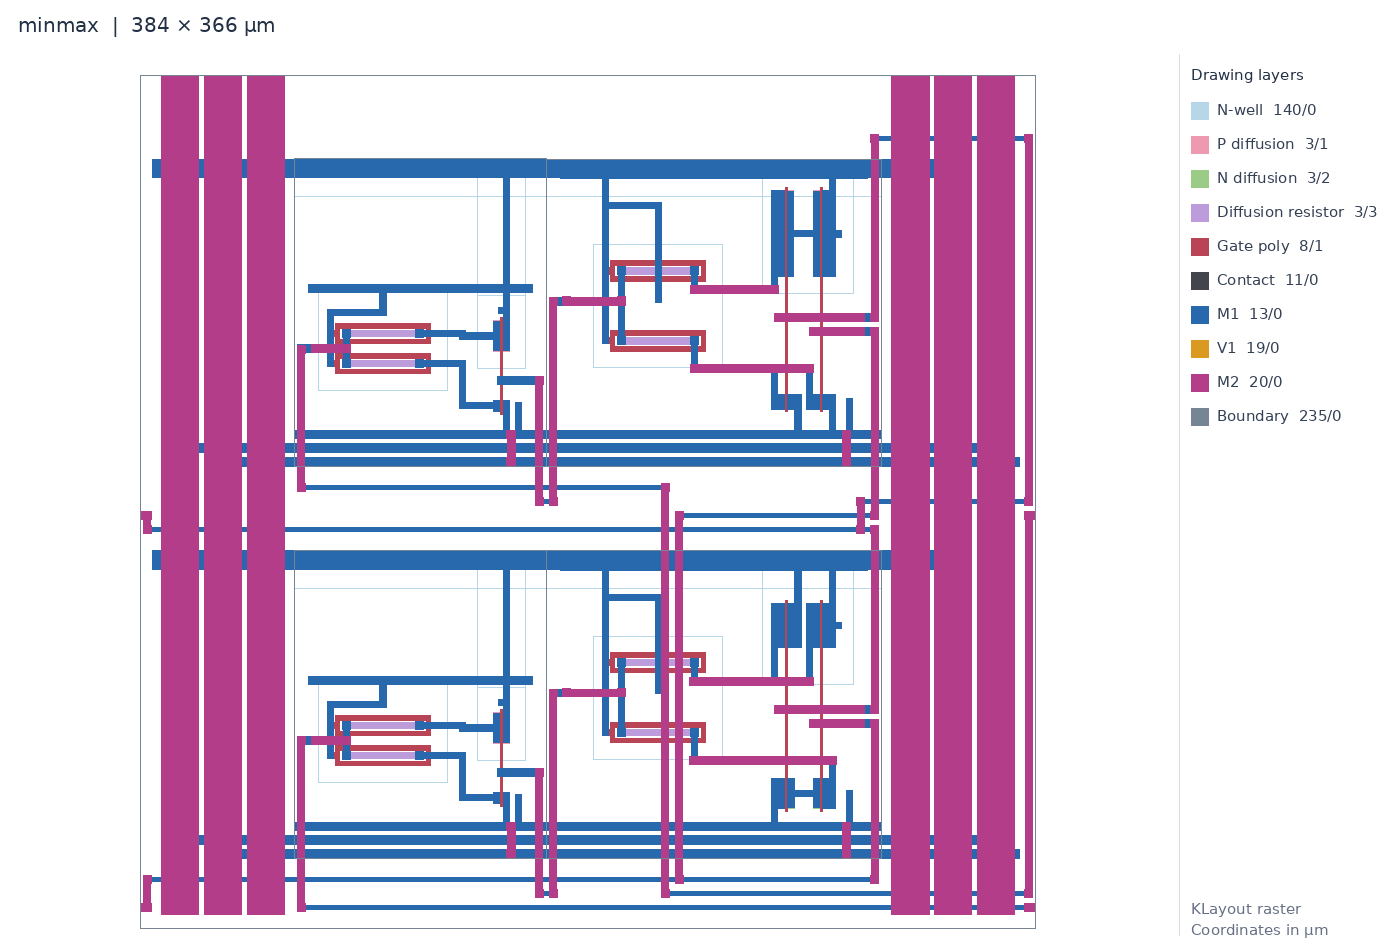

In [29]:
custom_out = BUILD/"your_circuit"/example.top
custom_lay = custom.place_and_route(output_dir=custom_out, seed=0, anneal_steps=600)   # → GDS
print("DRC clean:", custom_lay.drc()["clean"], "· LVS match:", custom_lay.lvs()["matched"])
display(Image(filename=str(render_gds(custom_lay.gds_path, custom_out/f"{custom.top}.layout.png",
                                      top=custom.top)), width=760))


Running: your-minmax


Independent arithmetic input states,9
Physical results,"die_size_um: [384, 366]; die_area_um2: 1.405e+05; wirelength_um: M1: 1482; M2: 1385; via_count: 32; power_via_count: 80; utilization: 0.4734; instance_count: 4; row_count: 2; net_count: 6; spans_per_row: 1; channel_tracks: 4; aspect_ratio: 1.049; anneal_steps: 600; routed_nets: 6; library_mock: False; max_supply_drop_v: 0.001178; bypass_tracks_per_side: 0; hpwl_before_um: 932; hpwl_after_um: 416; hpwl_improvement_pct: 55.36; runtime_s: placement: 0.00648; routing: 0.008324; export_and_verification: 1.325; total: 1.339"
DRC clean / LVS matched,"[True, True]"
Initial Newton guesses (V),pre: xdut.n_ex_I7: 5; xdut.n_ex_I6: 5; post: xdut.n_ex_I7: 5; xdut.n_ex_I6: 5


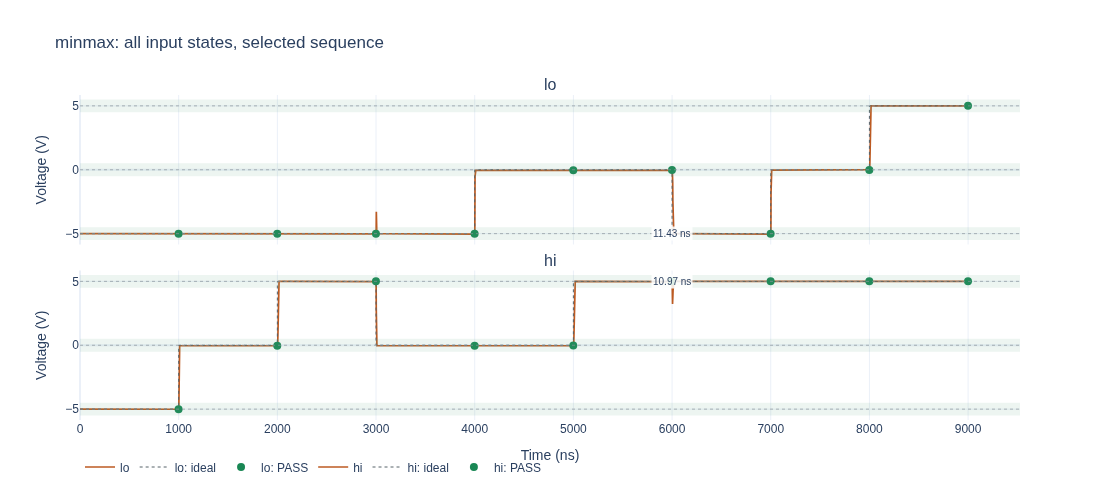

> **What this shows.** minmax passes the integer reference for
> 9 input states. Its 4 mapped cells occupy
> 384 × 366 µm; drawing DRC has 0 markers, LVS is
> Match, and the extracted sequence visits
> 9 input states with output checks PASS.

Use the generated HDL, SPICE, GDS and result files as the starting point for
another ternary design on OpenSUSI TR-1um.


In [30]:
#@title 第8章：自分のレイアウトから抽出したSPICEとその波形 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('custom', 'Chapter 8: Change the circuit and close the loop', requires=['custom_check']):
    custom_result = cache.run(f"your-{CHOICE}", {"source":source,"net":custom.to_json(),"vectors":planned,
                             "expected":[oracle(v) for v in planned],"load_f":10e-15,"hold_s":1e-6,
                             "step_s":2e-9,"rows":None,"anneal_steps":600,"seed":0,"initialize_internal":True},
        lambda: complete_design(custom,custom_out,planned,oracle,hold_s=1e-6,initialize_internal=True),
        artifacts=lambda r: experiment_artifacts(r,custom_out,example.top))
    assert_experiment(custom_result)
    assert {tuple(row["input_trits"]) for row in custom_result["post"]["measurements"]["rows"]} == set(planned)
    table([["Independent arithmetic input states",len(planned)], ["Physical results",custom_result["stats"]],
           ["DRC clean / LVS matched",[custom_result["drc"]["clean"],custom_result["lvs"]["matched"]]],
           ["Initial Newton guesses (V)",custom_result["initial_nodeset_v"]]],details="Selected circuit physical evidence and Newton guesses")

    show(waveform_figure(custom_result["post"],title=f"{CHOICE}: all input states, selected sequence"))
    custom_values = {"custom.name":custom.top,"custom.logic_states":len(planned),
        "custom.cells":custom.report()["total_cells"],"custom.die_um":dimensions(custom_result["stats"]["die_size_um"]),
        "custom.drc_items":custom_result["drc"]["violations"],"custom.lvs_status":"Match",
        "custom.analog_states":len(set(planned)),"custom.analog_status":"PASS"}
    custom_takeaway = (ROOT/"notebook/narrative/08_your_circuit.md").read_text().split("> **What this shows.**",1)[1]
    display(Markdown(render_narrative("> **What this shows.**"+custom_takeaway,{**narrative_values,**custom_values})))


意図的に未対応の式を使うと、合成前に、該当箇所が分かる読みやすいエラーが表示されます。


In [31]:
from tritflow.hdl import HDLError
broken = """
module broken(input trit a, b, output trit y);
  assign y = a + b;   // '+' on signals is not a gate
endmodule
"""
try:
    flow.loads(broken, "broken", filename="your_circuit.tv")
except HDLError as error:
    print(error)
    print("Repair: use gates for signal arithmetic; e.g. nany(a, b) gives the negative saturated sum.")
else:
    raise AssertionError("unsupported signal arithmetic must be rejected")


your_circuit.tv:3:14: arithmetic/comparison on trits is unsupported; use ~, &, |, nany and sized trit literals
Repair: use gates for signal arithmetic; e.g. nany(a, b) gives the negative saturated sum.


## 9. 次の段階：モデルと実チップを比較する

参照セルのチップは2027年一月に到着する予定です。実測によって、
分圧とタイミングの予想を実素子と照合します。まずDCの
出力レベルと各レールの静的電流を測り、次に、既知の入力
エッジと負荷で整定を測ります。記録した電源電圧、温度、プローブ負荷に
合わせて、比較用のSPICE実験を設定します。

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">測定</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">結果とともに記録する項目</th><th width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">SPICEとの比較対象</th></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">入力のDC掃引</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">電源電圧、温度、各レールの電流</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">伝達特性と中間レベルの誤差</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">トリットレベル間のステップ</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">入力エッジ、スキュー、出力の総負荷</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">目標電圧帯への最終進入</td></tr>
<tr><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">電源と温度の掃引</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">各測定での実際の動作点</td><td width="33.3333%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:33.3333%;">レベルと電流の感度</td></tr>
</table>
</div>

最初の比較では、中間領域を通るように入力を掃引し、
出力と各レールの電流を測ります。次にトリットレベル間でステップを与え、
同じ電圧帯への最終進入を測定し、複数の負荷で繰り返します。
回路負荷に加えて、パッド、パッケージ、測定器の容量を記録します。
その後、電源と温度を掃引すれば、どの差がバイアスに依存し、
どの差が配線や素子の仮定の見直しを要するかを調べられます。


### 自分のHDLからシャトル向けのトップレベルへ

配線済みのコアにも、フレーム、実際の端子、マスクデータの準備が必要です。
`PnrResult.to_chip()`は、固定リビジョンの
MPW TEGフレームのコピー内に対応するコアを配置し、シールリングと配置禁止領域を保ち、
コピーしたパッド群を外周のパッシブな`OSS_PAD_TEG`パッドに置き換えます。
標準の加算器レイアウトを選択した場合の公開API呼び出しは、次のとおりです。

```python
chip = layout.result.to_chip()
checks = chip.signoff()
chip.gds_path
```

`to_chip()`はトップ全体を構築して適合性を確認し、`ChipResult.signoff()`は
検証を再実行するか、変更のない検証済みレポートを再利用します。`layout.signoff()`だけでは
コアのみの検証なので、トップ全体のサインオフには返されたchipを使ってください。出力には、
描画GDS、参照回路、パッドマップ、準備済みのマスクGDS、
各ツールの生のレポートが含まれます。


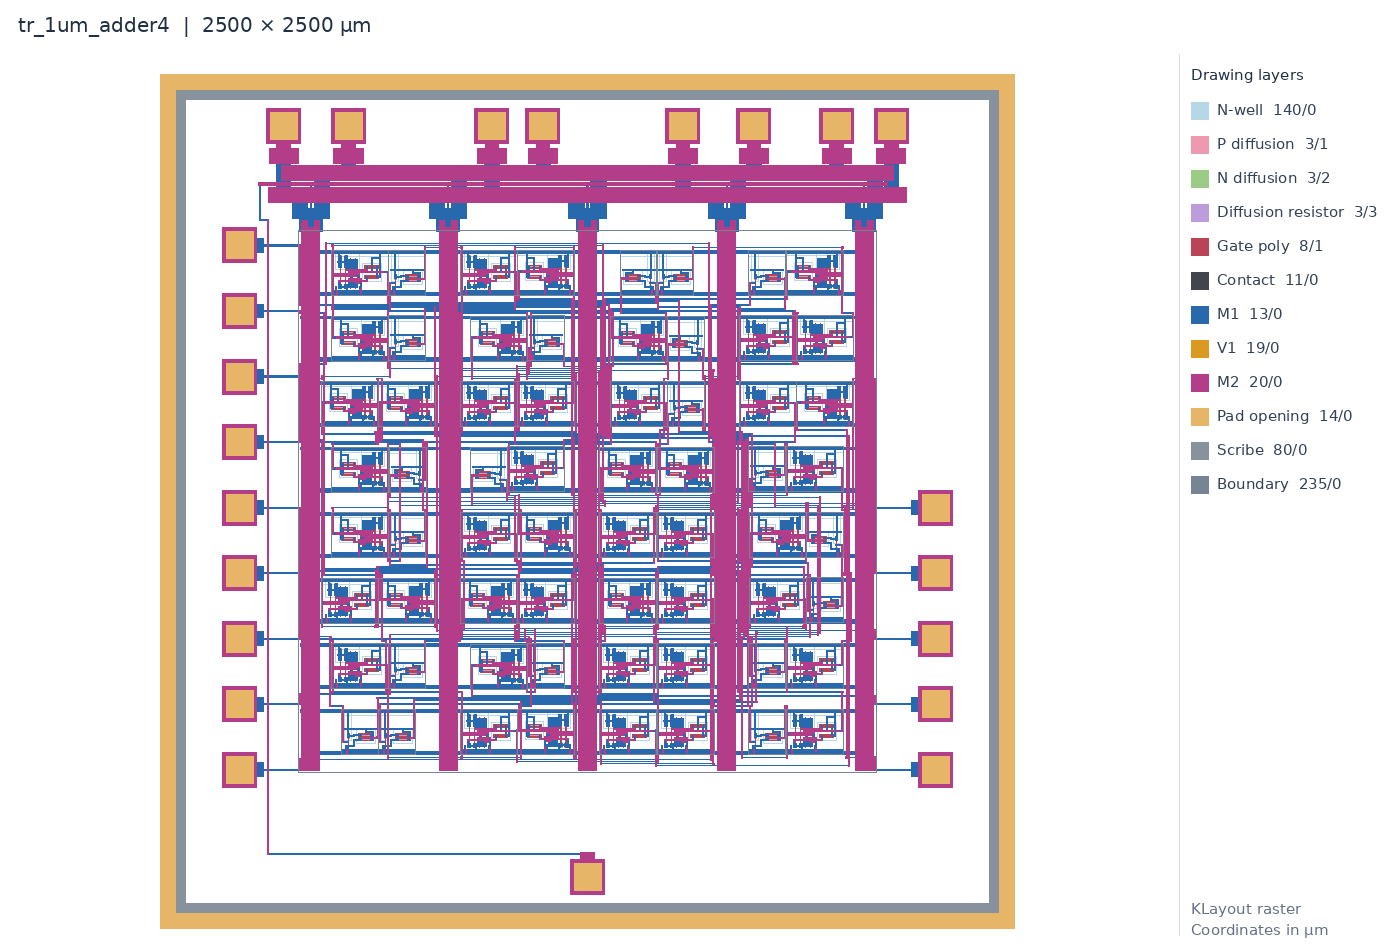

Check,Result
drawing_drc,clean: True; violations: 0
drawing_lvs,matched: True; strict_ports: True
mask_drc,clean: True; violations: 0
mpw_precheck,clean: True; exit_code: 0
submission_ready,False
reason,Custom TEG pad/bond allocation and ESD/power/package approval still required


In [32]:
chip = json.loads((ROOT/"notebook/assets/chip/adder4/signoff.json").read_text())   # recorded run, adder4 seed 7
display(Image(filename=str(ROOT/"notebook/assets/chip/adder4/tr_1um_adder4.png"), width=640))
table([["Check", "Result"]] + [[k, chip[k]] for k in
      ("drawing_drc", "drawing_lvs", "mask_drc", "mpw_precheck", "submission_ready", "reason")])
# Reproduce locally with KLayout and the OpenSUSI MPW template (see docs/status/PNR.md):
#   full = macro.to_chip(); full.signoff()


In [33]:
#@title 第9章の検証：記録済みのサインオフ結果とパッドマップ { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('shuttle', '9. Next: compare the model with silicon', requires=[]):
    assert chip["physical_checks_passed"] and chip["drawing_drc"]["clean"] and chip["mask_drc"]["clean"]
    assert chip["drawing_lvs"]["matched"] and chip["drawing_lvs"]["strict_ports"]
    assert hashlib.sha256((ROOT/"notebook/assets/chip/adder4/tr_1um_adder4.gds").read_bytes()).hexdigest() == chip["gds_sha256"]
    details_html("Pad map and remaining submission steps",
                 "<pre style='white-space:pre-wrap'>"+(ROOT/"notebook/assets/chip/adder4/README.md").read_text()+"</pre>")


> **ここから分かること。** 記録済みのフレーム付き加算器はpaper/adder4 · seed 7をもとにしており、
> 寸法は2500 × 2500 µm、実パッドは23個です。描画DRCの報告は
> 0件、厳密な描画LVSはMatch、
> マスクデータ準備後のマスクDRCの報告は0件、
> MPW事前チェックはPassです。

物理検証には合格していますが、`submission_ready`は`false`のままです。
実際の設計を提出する前に、次の作業が必要です。

1. フレーム全体と独自のパッド／プローブマップについて、シャトル主催者から
   割り当ての承認を得ます。このトップは、従来の共用スロットには収まりません。
2. ボンディング／パッケージ図を完成させます。同じ電源ドメインの全電源パッドに給電し、
   VMIDは別に供給します。ダイアタッチと共通基板をVSSとする取り決めも行います。
3. -5/
   0/+5 Vの電源について、プロセスとESDの承認を得ます。これらのパッシブパッドには
   ESD回路がありません。パッケージ／プローブ負荷、電源インピーダンス、パッド／ボンドの
   許容電流を確認します。
4. シャトル用のメタデータ、ライセンス、回路図、参照回路の
   提出一式を完成させます。凍結したリビジョンに対して主催者のCIを実行し、最終的な
   マスクと電気的な結果をシャトル担当者と確認します。

確認したシャトルのフローでは、マスクデータ準備前の描画に対して厳密なLVSを行い、
マスク作成後のLVSは定義されていません。TritFlowは成果物と
レポートを準備しますが、割り当ての申請や提出は行いません。


## 付録A. この結果から確認できること

論理等価性、物理的な接続、アナログの整定は、それぞれ異なる
問いに答えます。付録Bの表では、実際に行った検証と、
各結果の条件を明示しています。

**実チップ。** 参照セルはテープアウト済みですが、実チップはまだ測定していません。適合化したスタンダードセルのレイアウトと生成した設計は、シミュレーションとレイアウト上の結果です。

**動作条件。** 明示的に示した掃引を除き、公称モデルと、表示した電源、温度、入力ランプ、負荷を使っています。統計的なミスマッチや、PVT全般での動作を保証するものではありません。

**論理。** このHDLは組合せ三値回路を記述します。順序回路、`x`/`z`の意味体系、一般的な信号の算術演算子には対応していません。等価性検証は、設計ごとに明示した全数検査またはサンプリングによります。

**アナログ検証の範囲。** 一つのシーケンスで全入力状態を通っても、すべての有向遷移や入力スキューを試したことにはなりません。大規模な回路では、明示したキャリー伝搬パターンと算術パターンを使います。静的な最大値の対象は、列挙したDC状態に限られます。

**タイミング。** 整定とは、入力ランプの開始を起点に測り、記録した入力区間の終わりまで許容帯内に留まる、最後の帯内進入を指します。時間分解能はサンプリングと補間に制限されます。未整定の出力については、有限の遅延値を報告しません。入力区間を長くすると、負荷の合否が変わる場合があります。

**静的タイミング。** 精度比較で扱うSTAの範囲は、SPICEで試験した遷移集合と条件に限られ、すべての遷移での精度を示すものではありません。イベントモデルは論理イベントとスルーを伝搬させますが、部分的にしか振れないアナログパルスの振幅や履歴は扱いません。別の保守的な見積もりは、保存済みの公称条件の観測値を覆いますが、任意の波形やPVTに対する保証付き上限ではありません。

**配線モデル。** 素子抽出にはPDKのLVSデッキを使います。追加する配線容量は、接続されたメタルの面積と周囲長に仮定した係数を適用し、ネットごとの集中容量として見積もったものです。較正済みの寄生抽出ではありません。主要な比較には、信号配線抵抗、結合、ポリの分布RC、パッケージの影響を含めていません。

**素子の比較。** 素子本体が同一であれば、回路の同一性を確認できます。メタル容量の比較では、形状に依存する負荷を追加します。いずれの比較も、配線RC全体や実チップとの等価性を確認するものではありません。

**手計算。** 分圧回路には、近似したオン抵抗と簡略化した抵抗モデルを使います。リップルキャリーの見積もりでは独立した一つのキャリー段を繰り返し、セルのDC電力の合計には全入力ゼロのバイアスを使います。これらは理解のための予想であり、任意の入力や経路に対する上限ではありません。

**ポリ抵抗。** 任意で行うポリ抵抗の検討は、ゲートポリのシート抵抗を仮定した感度解析です。抵抗素子やMOS拡散層のパラメータを、較正済みのゲートポリモデルの代わりにはできません。

**電源供給。** 分圧型セルは静的電力を消費します。電源レールの抵抗網では、特性評価から得た電流の包絡値と、仮定したメタル／ビア抵抗を使います。これは理想電源によるSPICE波形とは別の解析です。公開されたDC上限を配線幅で換算し、余裕を確保しても、寿命、過渡動作、パッド、ボンド、電流集中に対する適合性を確認したことにはなりません。

**製造。** コアとフレーム付きトップの検証は分けて示します。任意のTEGラッパーについては、描画DRC、厳密な描画LVS、マスク準備、マスクDRC、確認対象のMPW事前チェックを行っています。マスク作成後のLVS段階は定義されていません。パッシブパッドにESD回路はありません。提出には、割り当て／独自パッドマップの承認、全電源のボンディング、基板／ダイアタッチの合意、パッケージ／負荷／電流の確認、プロセス／ESDの承認、主催者の最終CIが引き続き必要です。


付録Bの物理ライブラリと実験ファイルには、仮定と
試験した入力計画を残し、再利用できるようにしています。


## 付録B. 検証の根拠と再実行の方法

以下の各結果には、対応するHDL、ライブラリ、PDK、各ツールの生のレポートへのリンクがあります。記録済みの
結果には、その実行で使ったツールと条件が残っています。保存済みの
レポートを読むだけでは、新たな物理検証や電気的検証は実行されません。

以下の配線結果IDを使い、論文用の図と
四設計の結果を区別してください。回路名だけではレイアウトを特定できません。

<div style="display:block;width:100%;min-width:0;max-width:100%;overflow-x:auto;contain:inline-size;box-sizing:border-box;">
<table width="100%" style="width:100%;min-width:0;max-width:100%;table-layout:fixed;border-collapse:collapse;">
<tr><th width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">図または結果のまとまり</th><th width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">配線結果ID</th></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">論文用の加算器の概要と配置</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">paper/adder4 · seed 7</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">論文用の全加算器の波形と負荷掃引</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">paper/full_add · seed 19</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">論文用の桁数掃引</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">width-sweep · seed 7</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">四設計の保存結果：adder4</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/adder4 · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">四設計の保存結果：full_add</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/full_add · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">四設計の保存結果：mac1</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/mac1 · seed 0</td></tr>
<tr><td width="20%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:20%;">四設計の保存結果：mul1</td><td width="80%" style="white-space:normal;overflow-wrap:anywhere;word-break:normal;min-width:0;vertical-align:top;text-align:left;padding:.45em .7em;width:80%;">four-design/mul1 · seed 0</td></tr>
</table>
</div>

詳細な物理検証表とタイミング表では、各設計／出力の行の
**配線結果ID**列に、この識別子を再掲します。論文用と
保存結果の全加算器は配線が異なるため、外部負荷と入力区間が同じでも、
和の整定時間は別の測定値です。

各アナログ実験の展開表示される表には、実際の入力順序、
訪問した異なる状態数、取りうる状態数、入力区間、エッジ時間、最大時間刻み、
温度、外部負荷、初期化区間、合格基準を示します。出力ごとの
許容帯に対する誤差と整定時間も波形とともに示します。遷移の最大値には
初期化を含めません。Newton法の初期推定値を補助的に使う場合は、
回路とともに列挙します。これらは過渡解析を拘束しません。

**ノートブックを実行する。** Colabバッジを開き、**「ランタイム → すべてのセルを実行」（Runtime → Run all）**を選択します。
セットアップセルには、解決されたソースのリビジョンとインストール済みツールが表示されます。
既定のセッションでは、冒頭の加算器と、選択した編集可能な回路を実行します。
大規模な寸法・桁数・負荷の掃引では、記録済みデータを読み込むことがあります。末尾の
表では、新規計算、ローカル結果の再利用、記録済み実験を区別し、
各段階の実経過時間を示します。最後のセルには、セットアップを含む今回のセッションの実測実行時間が表示されます。上記のColab実行記録には、
試験したソース、完了状況、セットアップの再試行を含む計測範囲を明記しています。
過去の実行成功が、それ以降のリビジョンを検証するわけではありません。

STA表では、各設計／出力について`tested_predicted_s`と`simulated_s`を比較し、
条件をそろえた入力計画、負荷、配線結果IDを
示します。別の保守的な見積もり`predicted_s`と、その
適用範囲は別々の列に残します。精度帯内の点だけでなく、目標範囲外の出力端点も
表示します。大部分が正確でも、
全出力の精度検証に合格したことにはなりません。フレーム付きトップの表では、元のコア、
フレーム、パッドマップを特定し、描画DRC、厳密な描画LVS、マスクDRC、
MPW事前チェックを、それぞれ`submission_ready`や残りの
承認手順とともに示します。マスク作成後のLVS結果を意味するものではありません。

<details>
<summary>計算を再実行する</summary>

実行前に`TRITFLOW_FORCE_RUN=1`を設定すると、共通設計の例題を含め、
計算量の大きいノートブックの段階を再計算します。ローカルの結果キャッシュと
記録済みの共通設計アーカイブの両方を使わずに実行します。この変数では、
別途公開されているセル特性評価、寸法・桁数・負荷の掃引データは再生成しません。
`TRITFLOW_EXTENDED=1`で、ノートブックの追加実験を有効にします。
ビルドディレクトリは`TRITFLOW_NOTEBOOK_BUILD`で選択します。

固定リビジョンのPDKとツールをインストールし、リポジトリ全体をチェックアウトした環境で、次のコマンドを実行すると、
大規模なシミュレーション実験を再生成して結果を検証できます。

```sh
python3 -m tritflow.sim.sizing
python3 examples/postlayout_all.py
python3 examples/adder_scaling.py --jobs 1
python3 -m tritflow.sim.publication
python3 -m pytest tests/sim tests/extract -q
```

同じSPICEの生出力が利用可能なら、`python3 -m tritflow.sta.validate`で
SPICEを再実行せずにタイミング比較を再計算できます。第9章のchip APIは、
チップの`signoff/`ディレクトリにレポートを保存します。
`chip.signoff(force=True)`は、トップ全体の検証を新たに実行します。既定では、繰り返しの
呼び出し時に、保存済み成果物を検証してから再利用します。

`tritflow.sim.load_sweep.sweep_output_load(directory, destination=...)`は、
生成済みの物理設計に対して全加算器の負荷実験を繰り返します。
`tritflow.sim.scaling.run_scaling(...)`では、新たな
桁数依存性の実験について、桁数と保存先を選択します。既存の入力とツールの生出力は、
再利用前に検証します。必ず新たに計算させるには、該当する実験出力を削除するか、
新しい保存先を選んでください。失敗した測定や欠落した測定も表示に残ります。

HDL、合成、物理設計の部分を変更する場合は、各部分の
回帰テストを別々に実行してください。DRC/LVSの生のレポート、SPICEデッキ、シミュレータのログ、
波形は、生成した各設計とともに保存されます。

</details>

<details>
<summary>ソースとライセンス</summary>

設計ソースは、[TritFlow](https://github.com/PenguinEino/tritflow)、
[著者の参照三値回路](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic)、
[OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um)で
公開しています。KLayoutのパッケージは
[公式配布元](https://www.klayout.de/build.html)から取得します。
提出物にはApache-2.0ライセンスとNOTICEを含めます。過去の回路図をもとにした
図版は、著者が同じライセンスで
公開しています。PDKには、PDK自身のライセンスと出典表記が適用されます。

</details>


無料版Colabでの動作確認（[0ffe7a1](https://github.com/PenguinEino/tritflow/commit/0ffe7a12c34738664e9e788853d87edc9da5b7ec)）：セットアップを含め、全35コードセルが300.7 sで完了しました。

セットアップ後にRun allが止まった場合は、もう一度Run allを選択してください。


<details><summary>セットアップ、復旧、ソースの選択</summary>

Colabでは`colab-v0`を`/content/tritflow`に浅いクローンで取得します。`TRITFLOW_REF`で別のリリースを選べます。
このノートブックに対応するソースのリビジョンを使ってください。セットアップはColabのNumPy/SciPy/Matplotlib/Plotlyを維持し、
最低バージョンを確認して、KLayout/ngspiceのバージョンを表示します。バージョンの混在を検出した場合は、
一度再起動し、セットアップとインポートを再実行してください。章の実行が失敗した場合は、指定された前提セルを再実行します。
科学計算の入力が欠落・変更している場合は実行を停止し、図版のみの変更では警告だけを出します。
末尾の表では、計算と記録済み実験を区別します。

</details>


In [34]:
#@title 付録B：セルの特性評価とファンアウトの検証結果 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('characterization', 'Appendix B: Verification evidence and how to rerun', requires=[]):
    characters = {cell: json.loads((CELLS_DIR/f"out/{cell}/{cell}.char.json").read_text())
                  for cell in ["INV","NAND","NOR","NANY","BUF"]}
    rows = [["Cell", "Max DC error (mV)", "Max static rail |I| (µA)", "Input C (fF)", "Suggested fanout"]]
    for cell, char in characters.items():
        assert hashlib.sha256((CELLS_DIR/f"out/{cell}/{cell}.ext.spice").read_bytes()).hexdigest() == char["source_sha256"]
        assert all(hashlib.sha256((PDK_ROOT/"libs.tech/spice/models"/name).read_bytes()).hexdigest() == value
                   for name,value in char["model_sha256"].items()), cell
        assert char["passed"] and all(row["passed"] for row in char["dc"])
        assert len({tuple(row["input_trits"]) for row in char["dc"]}) == 3**len(char["inputs"])
        assert all(result["passed"] for result in char["transient"])
        rows.append([cell, 1e3*max(abs(v) for row in char["dc"] for v in row["error_v"].values()),
                     max(abs(i) for row in char["dc"] for i in row["rail_current_a"].values())*1e6,
                     char["input_capacitance"]["max_f"]*1e15, char["fanout"]["suggested_max"]])
    characterization_rows = rows
    evidence("Full-precision DC checkpoints", {cell:char["dc"] for cell,char in characters.items()})
    table([["Cell", "Recorded conditions", "Tested loads (fF)", "Fanout evidence"]]+
          [[cell, char["conditions"], [r["load_f"]*1e15 for r in char["transient"]], char["fanout"]]
           for cell,char in characters.items()], details="Characterization conditions and complete fanout evidence")
    fanout_rows = [["Cell", "Measured receiver counts", "Chain depth", "Worst chain (ns)",
                    "Driver at largest tested fanout (ns)", "Max level error (mV)"]]
    for cell, char in characters.items():
        cascade = char["cascade"]
        assert cascade["source_sha256"] == char["source_sha256"]
        assert cascade["passed"] and cascade["chains_passed"] and all(c["passed"] for c in cascade["cases"])
        largest = max(cascade["fanouts_tested"])
        chain_times = [t for c in cascade["cases"] if c["mode"] == "chain"
                       for t in c["max_settling_s"].values() if t is not None]
        loaded_times = [c["max_settling_s"]["y0"] for c in cascade["cases"]
                        if c["mode"] == "fanout" and c["fanout"] == largest]
        fanout_rows.append([cell, cascade["fanouts_tested"], cascade["chain_depth"],
                           max(chain_times)*1e9, max(loaded_times)*1e9,
                           max(c["max_error_v"] for c in cascade["cases"])*1e3])


Cell,Recorded conditions,Tested loads (fF),Fanout evidence
INV,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 4; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
NAND,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 4; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
NOR,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 3; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
NANY,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 2; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"
BUF,temperature_c: 27; supplies_v: VDD: 5; VMID: 0; VSS: -5; band_v: 0.5; edge_s: 1e-09; hold_s: 2e-07; step_s: 5e-10,"[10, 100, 1000]","suggested_max: 8; tested_counts: [1, 2, 4, 8]; capacitance_estimate_max: 4; method: measured self-loading; every receiver pin and other-input trit bias; five-stage chains; scope: nominal 27 C, ideal rails, 10 fF per receiver/final output; no interconnect RC or PVT; chain_depth: 5"


In [35]:
#@title 付録B：四設計の物理検証・タイミング検証 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('four', 'Appendix B: Verification evidence and how to rerun', requires=[]):
    from tritflow.sim.postlayout import representative_vectors, arithmetic_oracle
    FOUR_DESIGN_LOAD_F, FOUR_DESIGN_HOLD_S, FOUR_DESIGN_STEP_S = 10e-15, 500e-9, 2e-9
    four_results = {}
    physical_rows = [["Design", "Routing realization", "Die (µm)", "Aspect", "Utilization", "DRC / LVS", "Input states visited / possible",
                      "Post max error (mV)", "Rail deviation / zero shift (mV)"]]
    timing_rows = [["Design", "Routing realization", "Output", "Device-only max (ns)", "+ wire-C max (ns)", "Largest same-transition change (ns)"]]
    four_run_labels = {}
    for name, source_name, params in [("adder4","adder",{"N":4}), ("full_add","full_add",{}),
                                      ("mac1","mac1",{}), ("mul1","mul1",{})]:
        mapped = flow.load(ROOT/f"examples/{source_name}.tv", source_name, params).synthesize(name=name)
        pins = [p.name for p in mapped.ports if p.dir == "input"]
        planned, labels = representative_vectors(name, pins)
        oracle = arithmetic_oracle(name, pins)
        directory = BUILD/"four_designs"/name
        options = {"net":mapped.to_json(),"vectors":planned,"labels":labels,
                   "expected":[oracle(v) for v in planned],"load_f":FOUR_DESIGN_LOAD_F,
                   "hold_s":FOUR_DESIGN_HOLD_S,"step_s":FOUR_DESIGN_STEP_S,
                   "rows":None,"anneal_steps":600,"seed":0,"initialize_internal":True}
        lookup_started = time.monotonic()
        result = None if cache.force else recorded_campaign.get(name,options)
        if result is not None:
            cache.events.append((f"four-{name}","recorded"))
            cache.timings.append({"stage":f"four-{name}","state":"recorded",
                                  "elapsed_s":time.monotonic()-lookup_started})
            print(f"Recorded {name}: retained native checks; see Appendix B")
        else:
            result = cache.run(f"four-{name}",options,
                lambda: complete_design(mapped,directory,planned,oracle,load_f=FOUR_DESIGN_LOAD_F,
                           hold_s=FOUR_DESIGN_HOLD_S,step_s=FOUR_DESIGN_STEP_S,initialize_internal=True,dataset='four-design'),
                artifacts=lambda r: experiment_artifacts(r,directory,name))
        assert_experiment(result)
        state = 'recorded' if cache.events[-1][1] == 'recorded' else ('fresh' if cache.events[-1][1] == 'run' else 'local reuse')
        if state == 'recorded':
            assert result['routing'] == archive_routing(ROOT/'notebook/assets/four_designs.zip')[name]
        run_label = routing_label(result['routing'],state=state,digest=True)
        four_run_labels[name] = run_label
        assert result["post"]["stimulus"]["vectors"] == list(map(tuple,planned))
        stats, ir = result["stats"], result["ir"]
        rail = max(abs(v) for c in ir["cells"].values() for v in c["rail_deviation_v"].values())
        zero = max(abs(c["zero_level_shift_v"]) for c in ir["cells"].values() if c["zero_level_shift_v"] is not None)
        physical_rows.append([name,run_label,stats["die_size_um"],max(stats["die_size_um"])/min(stats["die_size_um"]),
                              stats["utilization"],[result["drc"]["clean"],result["lvs"]["matched"]],
                              f"{len(set(planned))} / {3**len(pins)}",result["post"]["measurements"]["max_error_v"]*1e3,
                              [rail*1e3,zero*1e3]])
        before, after = [result[mode]["measurements"] for mode in ("pre","post")]
        for pin in after["max_settling_s"]:
            changes = [b["outputs"][pin]["settling_s"]-a["outputs"][pin]["settling_s"]
                       for a,b in zip(before["rows"][1:],after["rows"][1:],strict=True)]
            timing_rows.append([name,run_label,pin,before["max_settling_s"][pin]*1e9,after["max_settling_s"][pin]*1e9,
                                max(changes)*1e9])
        four_results[name] = result


    if recorded_campaign.manifest:
        evidence("Recorded four-design producer tools (not local requalification)",
                 recorded_campaign.manifest["tools"])
    table([["Shared load (fF)",FOUR_DESIGN_LOAD_F*1e15], ["Hold / max step (ns)",
           [FOUR_DESIGN_HOLD_S*1e9,FOUR_DESIGN_STEP_S*1e9]],
           ["Input plan labels", {name:representative_vectors(name,
              r["post"]["stimulus"]["inputs"])[1] for name,r in four_results.items()}]],details="Four-design stimulus conditions and labels")


Recorded adder4: retained native checks; see Appendix B
Recorded full_add: retained native checks; see Appendix B
Recorded mac1: retained native checks; see Appendix B
Recorded mul1: retained native checks; see Appendix B


Shared load (fF),10
Hold / max step (ns),"[500, 2]"
Input plan labels,"adder4: [zero, positive_propagate_setup, positive_carry_through_all_four_digits, positive_carry_release_through_all_four_digits, negative_propagate_setup, negative_carry_through_all_four_digits, negative_carry_release_through_all_four_digits, positive_overflow, negative_overflow, opposite_operands, alternating, alternating_reverse, positive_digit_0, negative_digit_0, positive_digit_1, negative_digit_1, positive_digit_2, negative_digit_2, positive_digit_3, negative_digit_3]; full_add: [exhaustive_0, exhaustive_1, exhaustive_2, exhaustive_3, exhaustive_4, exhaustive_5, exhaustive_6, exhaustive_7, exhaustive_8, exhaustive_9, exhaustive_10, exhaustive_11, exhaustive_12, exhaustive_13, exhaustive_14, exhaustive_15, exhaustive_16, exhaustive_17, exhaustive_18, exhaustive_19, exhaustive_20, exhaustive_21, exhaustive_22, exhaustive_23, exhaustive_24, exhaustive_25, exhaustive_26]; mac1: [exhaustive_0, exhaustive_1, exhaustive_2, exhaustive_3, exhaustive_4, exhaustive_5, exhaustive_6, exhaustive_7, exhaustive_8, exhaustive_9, exhaustive_10, exhaustive_11, exhaustive_12, exhaustive_13, exhaustive_14, exhaustive_15, exhaustive_16, exhaustive_17, exhaustive_18, exhaustive_19, exhaustive_20, exhaustive_21, exhaustive_22, exhaustive_23, exhaustive_24, exhaustive_25, exhaustive_26, exhaustive_27, exhaustive_28, exhaustive_29, exhaustive_30, exhaustive_31, exhaustive_32, exhaustive_33, exhaustive_34, exhaustive_35, exhaustive_36, exhaustive_37, exhaustive_38, exhaustive_39, exhaustive_40, exhaustive_41, exhaustive_42, exhaustive_43, exhaustive_44, exhaustive_45, exhaustive_46, exhaustive_47, exhaustive_48, exhaustive_49, exhaustive_50, exhaustive_51, exhaustive_52, exhaustive_53, exhaustive_54, exhaustive_55, exhaustive_56, exhaustive_57, exhaustive_58, exhaustive_59, exhaustive_60, exhaustive_61, exhaustive_62, exhaustive_63, exhaustive_64, exhaustive_65, exhaustive_66, exhaustive_67, exhaustive_68, exhaustive_69, exhaustive_70, exhaustive_71, exhaustive_72, exhaustive_73, exhaustive_74, exhaustive_75, exhaustive_76, exhaustive_77, exhaustive_78, exhaustive_79, exhaustive_80]; mul1: [exhaustive_0, exhaustive_1, exhaustive_2, exhaustive_3, exhaustive_4, exhaustive_5, exhaustive_6, exhaustive_7, exhaustive_8]"


In [36]:
#@title 付録B：検証結果の表、来歴、実行時間 { display-mode: "form" }
if "_tf_cells" not in globals():
    raise RuntimeError("Run setup and imports successfully before this chapter; rerun them after any requested runtime restart.")
with _tf_cells.running('final', 'Appendix B: Verification evidence and how to rerun', requires=['opening_inputs', 'opening', 'gates', 'sizing', 'cells', 'arithmetic', 'synthesis', 'pnr', 'pre', 'published', 'sta', 'custom_check', 'custom', 'shuttle', 'characterization', 'four']):
    table(characterization_rows,details="Cell DC / capacitance / fanout summary")
    table(fanout_rows,details="Transistor-level cascade and fanout tests")
    table(cell_dimension_rows,details="All standard-cell dimensions and pin-access tracks")
    table(cell_qualification_rows,details="Cell drawing-DRC and LVS qualification")
    table(physical_rows,details="Four-design physical and arithmetic checks (retained or fresh as below)")
    table(timing_rows,details="Four-design identical-device timing comparison")
    evidence("Cell ordered-pair/orientation abutments",report["abutment"])
    for name,grid in sizing_grids.items():
        evidence(name+" sizing status including unavailable points",[
            {"index":i,"dimensions":r["dimensions"],"passed":r["passed"],"error":r["error"]}
            for i,r in enumerate(grid["rows"]) if not r["passed"]])
    evidence("Live adder acceptance, sequence and initialized Newton guesses",{
        "logic":net.report()["equivalence"],"labels":vector_labels,"vectors":vectors,
        "measurements":demo["measurements"],"nodeset":demo["initial_nodeset_v"],
        "conditions":{"load_f":LOAD_F,"hold_s":HOLD_S,"edge_s":EDGE_S,"step_s":STEP_S,"temperature_c":TEMP_C}})
    evidence("Native paper-figure inputs and committed image/data hashes",paper)
    table([["Routing realization", "PNR SHA-256", "GDS SHA-256"]]+
          [[routing_label(r),r['pnr_sha256'],r['gds_sha256']]
           for r in (paper['paper_pnr']['routing'],paper['paper_post']['routing'])]+
          [[four_run_labels[name],r['routing']['pnr_sha256'],r['routing']['gds_sha256']]
           for name,r in four_results.items()],details="Native identities for each paper and four-design routing realization")
    assert (runtime_fingerprint(ROOT,PDK_ROOT,names=native_sources) == cache.fingerprint and
            source_manifest(ROOT,PDK_ROOT,names=native_sources) == native_sources), "consumed sources changed during Run all; rerun after publication settles"
    load_paper(ROOT)  # measurements remain strict; illustration changes only warn
    table([["Stage", "Fresh / local cache / recorded", "Wall time this run (s)"]]+[
        [r["stage"],r["state"],round(r["elapsed_s"],3)] for r in sorted(cache.timings,key=lambda r:r["elapsed_s"],reverse=True)])
    table([["Design", "Routing realization", "Measured producer phase", "Wall time (s)", "Process + child CPU time (s)"]]+[
        [name,four_run_labels[name],stage,round(seconds,3),round(result["cpu_times_s"][stage],3)] for name,result in four_results.items()
        for stage,seconds in result["timings_s"].items()],details="Physical and pre/post-SPICE runtime breakdown (producer evidence)")
    print("Cache stages:")
    for name,state in cache.events:
        print(f"  {name}: {state}")
    print(f"Run time including setup: {time.monotonic()-started:.1f} s")
    print("Artifacts:", BUILD)


Cell,Max DC error (mV),Max static rail |I| (µA),Input C (fF),Suggested fanout
INV,39.54,407.2,114.4,8
NAND,102.7,435.4,206.1,8
NOR,159,434.2,278,8
NANY,44.6,421.4,394.1,8
BUF,35.24,814.3,114.4,8


Cell,Measured receiver counts,Chain depth,Worst chain (ns),Driver at largest tested fanout (ns),Max level error (mV)
INV,"[1, 2, 4, 8]",5,15.11,36.03,39.54
NAND,"[1, 2, 4, 8]",5,35.5,65.33,104.3
NOR,"[1, 2, 4, 8]",5,64.53,94.5,158.9
NANY,"[1, 2, 4, 8]",5,70.26,144.9,106.5
BUF,"[1, 2, 4, 8]",5,27.05,37.87,35.66


Cell,Width × common height (µm),Area (µm²),Free full-height M2 tracks
INV,"[108, 132]",1.426e+04,13
NAND,"[144, 132]",1.901e+04,6
NOR,"[144, 132]",1.901e+04,6
NANY,"[168, 132]",2.218e+04,3
BUF,"[216, 132]",2.851e+04,25
TIEP,"[72, 132]",9504,9
TIEZ,"[72, 132]",9504,8
TIEN,"[72, 132]",9504,8
FILL,"[24, 132]",3168,2


Cell,Recorded DRC clean,Recorded LVS qualification,LVS method
INV,True,True,strict device/port comparison
NAND,True,True,strict device/port comparison
NOR,True,True,strict device/port comparison
NANY,True,True,strict device/port comparison
BUF,True,True,strict device/port comparison
TIEP,True,True,strict device/port comparison
TIEZ,True,True,strict device/port comparison
TIEN,True,True,strict device/port comparison
FILL,True,True,empty-device extraction + strict three-rail RR probe fixture


Design,Routing realization,Die (µm),Aspect,Utilization,DRC / LVS,Input states visited / possible,Post max error (mV),Rail deviation / zero shift (mV)
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),"[1740, 2022]",1.162,0.3584,"[True, True]",18 / 19683,43.34,"[19.32, 1.478]"
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),"[876, 702]",1.248,0.5126,"[True, True]",27 / 27,43.34,"[3.741, 0.6847]"
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),"[876, 1038]",1.185,0.4721,"[True, True]",81 / 81,43.45,"[6.47, 0.8884]"
mul1,four-design/mul1 · seed 0 · GDS 0f4a46d447b7 (recorded),"[420, 366]",1.148,0.4637,"[True, True]",9 / 9,100.9,"[1.206, 0.3301]"


Design,Routing realization,Output,Device-only max (ns),+ wire-C max (ns),Largest same-transition change (ns)
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[3],201.8,230.1,30.53
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[2],152.9,178.6,26.76
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[1],122.1,148.7,26.53
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),sum[0],122.8,139.2,16.42
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),cout,191.7,221.7,31.49
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),sum,100.3,110.1,15.1
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),cout,90.12,101.5,14.58
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),sum,131.9,147.6,17.85
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),cout,121.8,135,13.85
mac1,four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),and_out,13.38,15.8,3.14


Routing realization,PNR SHA-256,GDS SHA-256
paper/adder4 · seed 7,e8bbc6eb2c8de6ccd320a0ff775e51817c0fb26735c8581a0ddd048e4f288e6b,c8b426ff5408c656b8a1390d55edc3e89c9aa23378d9ce306648c2a55df93523
paper/full_add · seed 19,653836fddd49e7054008bb63b23830c287a5faa5ef62e77ef73b5ae193b7fbda,3f51bddf7aaa2706b8f8fe85d6f3aa75917fbc4daac7fa291b492c1d29199241
four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),2f4cd7d847557e479ddcceeb0dd73516097ddea523e29cb7c749b9b11f286753,8a9e5146dd5856e45ae18a090bfea8bf8832aec100996320dd612abf71e619c5
four-design/full_add · seed 0 · GDS e6f70481096a (recorded),fadc6e640d4421434df1f200b254c0ffff2ac69c118996bd6a45bb7c74b7c9ad,e6f70481096ab259602d2be2f9788f664b9368b6a5a6afe4619ab3c92276ff17
four-design/mac1 · seed 0 · GDS bc2ef6dfb832 (recorded),42be88c4b8f7e6880f5365d76e2c971f60502d8d909e8ece10f4e25f2e7d7633,bc2ef6dfb8323d0dc04adc04dd378a55ca05d079e87768d3e8aaf09d20b02496
four-design/mul1 · seed 0 · GDS 0f4a46d447b7 (recorded),a0b80eab6ad3297d2d750b8314b4b0fc5cd2537dcc5ed341ee606e2b8efbeaa3,0f4a46d447b762b21be18d9e2da2c7a0476c65fee9cb4ff1b17681955e22f1c8


Stage,Fresh / local cache / recorded,Wall time this run (s)
your-minmax,run,7.221
four-full_add,recorded,0.042
four-mac1,recorded,0.032
four-adder4,recorded,0.021
four-mul1,recorded,0.002


Design,Routing realization,Measured producer phase,Wall time (s),Process + child CPU time (s)
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),pnr_including_drc,18.43,20.18
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),strict_lvs,0.802,0.797
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),wire_capacitance,0.204,0.204
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),pre_ngspice,55.13,56.4
adder4,four-design/adder4 · seed 0 · GDS 8a9e5146dd58 (recorded),post_ngspice,54.99,56.25
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),pnr_including_drc,1.331,1.331
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),strict_lvs,0.808,0.804
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),wire_capacitance,0.061,0.061
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),pre_ngspice,16.53,17.15
full_add,four-design/full_add · seed 0 · GDS e6f70481096a (recorded),post_ngspice,16.6,17.25


Cache stages:
  your-minmax: run
  four-adder4: recorded
  four-full_add: recorded
  four-mac1: recorded
  four-mul1: recorded
Run time including setup: 70.6 s
Artifacts: /content/tritflow/build/notebook


## 付録C. TritFlowを使い、拡張する

EDA環境が整ったColabから始めるか、ローカルに編集可能なソース一式を
チェックアウトしてください。リポジトリには、フローに必要な例題HDL、生成済みのセル
ビュー、ノートブックの素材が含まれています。Pythonパッケージのインストール
だけでは、これらのファイルはそろいません。

### GitHubからインストールする

空の作業ディレクトリから、選択したソースのリビジョンをインストールします。

```sh
python3 -m pip install --src ./src -e "git+https://github.com/PenguinEino/tritflow.git@colab-v0#egg=tritflow"
cd src/tritflow
```

フロー全体の実行には、RubyのDRC/LVSエンジンを備えたKLayout本体、ngspice、
固定リビジョンのOpenSUSI PDKも必要です。対応するUbuntu amd64リリースでは、
リポジトリのセットアップスクリプトを使ってください。

```sh
bash notebook/colab_setup.sh --source "$PWD"
```

ツールがすでにインストールされている場合は、`TR1UM_PDK`に適合性を確認したPDKツリーを
設定し、必要に応じて`KLAYOUT_BINARY`にKLayout本体の実行ファイルを設定します。ソース、
PDK、ツールの固定バージョンは`notebook/setup_pins.json`に、セットアップの詳細と対応
プラットフォームは`notebook/README.md`に記載しています。

### 七行のAPI

セットアップ後、ソースのルートディレクトリから実行します。

```python
from tritflow import flow
design = flow.load("examples/adder.tv", "adder", {"N": 2})
net = design.synthesize(name="adder2")
layout = net.place_and_route(output_dir="build/adder2")
assert layout.drc()["clean"] and layout.lvs()["matched"]
vectors = [tuple(0 for p in net.ports if p.dir == "input")]
post = layout.extract().simulate(vectors, load=100e-15)
```

これは全入力をゼロとする簡易動作確認のシミュレーションです。`load`の単位はファラドです。各ベクトルは、
`net.ports`にある、各桁に展開した入力ポートの順序に従います。既定の期待出力は、
マッピング後の論理から求めます。算術結果を確認するには、ノートブックと同様に、独立した
整数演算の正解値を`expected=`で渡し、対象の経路を動作させる
遷移計画を用意してください。`post["measurements"]`でレベルと
整定の結果を確認します。シミュレーションが完了しただけでは、合格を確認したことにはなりません。
`layout.extract(wire_c=False)`は抽出素子だけを選択します。既定では、
形状に基づく推定配線容量を追加します。

配線前に`net.schematic(expand="*").show()`で回路を確認し、
`.save("build/adder2.svg")`で同じ回路図を保存できます。第7章では
`tritflow.sta.analyze`、第9章では別のフルチップ用ラッパーを示します。
HDLを文字列で渡す場合は`flow.loads(source, top=..., params=...)`を使います。

### コマンドラインからの実行

次のコマンドも、同じソースのルートディレクトリから実行します。`build/`の下に出力し、
出力とともに各ツールの生のレポートを保存します。

```sh
python3 -m tritflow.synth examples/adder.tv --top adder -P N=2 --name adder2 -o build/adder2
python3 -m tritflow.pnr build/adder2/adder2.json -o build/adder2 --seed 7
```

合成コマンドは、ゲートJSON、マッピング後のTritVerilog、SPICE、
等価性レポートを書き出します。P&RはGDSと配置配線記録を書き出し、
物理検証を行います。抽出後シミュレーションとチップ全体への
ラッパー追加には、上のPython APIを使ってください。汎用の`tritflow`実行コマンドや`tritflow.sta`モジュールのCLIはありません。

ライブラリを開発する場合は、専用の出力ディレクトリで生成と検証を行います。

```sh
python3 -m tritflow.cells build --out build/cell_trial
python3 -m tritflow.cells verify --out build/cell_trial
python3 -m tritflow.sim.characterize INV --spice build/cell_trial/INV/INV.ext.spice --destination build/INV.char.json
```

専用出力先への`build`コマンドはビューを生成し、`verify`は物理検証と
DC検証を行います。`python3 -m tritflow.sta.characterize --help`では中点基準の
タイミング特性評価を説明し、`python3 -m tritflow.sta.validate`では
既存のシミュレーション生出力を使ってSTAとSPICEの比較を繰り返します。付録Bには、
別途行う大規模な電気的実験と再実行コマンドを示しています。

### セルを追加する

回路、ポート、真理値関数を
`tritflow/cells/circuits.py`に定義します。形状は`tritflow/cells/compact.py`
（`WIDTHS`と描画処理の振り分け）に追加し、
`tritflow/cells/primitives.py`のPDKプリミティブを使います。`tritflow/cells/layout.py:build_cell`が
GDS、元のSPICE、抽象情報、真理値表を出力します。共通のセル行高さ、
格子、レール順序、規則を満たすピンアクセスを維持し、内部のすべての配線
障害物を抽象情報に記述してください。

新しい論理セルには、`tritflow/synth/simulate.py`での
ピン順序と評価処理（`CELL_INPUTS`、`evaluate_netlist`）、`tritflow/sim/spice.py:CELL_PINS`でのSPICEピン
順序、`tritflow/sim/characterize.py:logic_value`での特性評価用の
参照関数、`tritflow/synth/mapping.py:Mapper`での
マッピング規則も必要です。HDLプリミティブとして公開する場合は、
`tritflow/hdl/parser.py:GRAMMAR`と`tritflow/hdl/elaborate.py:Elaborator.items`を拡張します。
`tritflow/sta/logic.py`に関数を追加し、STAを使う前に遷移
クラスの特性評価を行います。新しい図が必要なセルでは、`tritflow/schematic/render.py`に回路図シンボルを
追加します。

真理値関数を独立に検証してから、描画DRC、厳密なLVS、DC
レベル、負荷付き過渡応答、セル行の突き当て配置を検証します。配布済みのセルビューを置き換える前に、専用ライブラリで試験的な
配線と抽出後シミュレーションを行ってください。
新しいセルが異なる種類の素子を導入する場合は、抽出デッキにある既存素子の
仮定を見直す必要があります。

### 演算子を追加する

まず、既存のトリット演算を組み合わせた再利用可能なHDLモジュールを検討してください。
新しい構文を導入する場合は、`tritflow/hdl/parser.py:GRAMMAR`と
`tritflow/hdl/elaborate.py:Elaborator.expression`を拡張し、
`tritflow/hdl/ir.py:Design.evaluate`に評価処理を定義し、`tritflow/synth/optimize.py`に定数畳み込みと
書き換えの動作を明示的に追加します。`tritflow/synth/mapping.py:Mapper.map`で演算子を既存の
セルにマッピングします。新しい物理セルが必要な場合は、
上記の追加手順も行います。

小さな演算子についてはトリットの全組合せを網羅し、元のソース、
最適化後のグラフ、マッピング後のセルを、独立した定義と照合します。不正な
使い方に対するエラー診断のテストを追加し、各書き換えを有効にする前に三値の
全領域で検証してください。二値論理の恒等式は、中間レベルを含めても
そのまま成り立つとは限りません。

影響する回帰テストを実行してから、関連する実ツールでの検証を行います。

```sh
python3 -m pytest tests/hdl tests/synth -q
python3 -m pytest tests/cells tests/pnr tests/sim tests/extract -q
python3 -m pytest tests/sta tests/schematic -q
```

別の設計者が比較を再現できるように、新しい例題には入力計画、ツール／PDKのリビジョン、
合格結果と失敗結果の両方を残してください。
